# Demucs(HTDemucs) 구조 뜯어보기 — 하나의 소리가 네 개의 소리가 되기까지

*Claude Code판(층별 텐서 모양·어텐션·SDR 실험)과 ChatGPT판(분석 대상 구분, 문제 정의, 소스 읽기 체크리스트, `apply_model` 조각 처리, 평가 관점)을 합친 노트북에, 11-06 상담 피드백을 반영해 **읽는 길잡이 · "숫자로 잇는 이야기"(7-3·8-3절) · 학습 대 추론(11-2절) · 이해 점검(12-2절)** 을 더했습니다(11-09). 기존 셀은 그대로입니다. 11-10에는 낮에 휴대폰으로 읽으며 한 질문과 ChatGPT 답변을 모은 `demucs_structure_analysis_QnA_20261110.md`를 이 노트북 하나로 합치려고 **"내 질문 → 절 찾기" 표 · 큰 그림 4 · 1-2 · 2-3 · 4-3 · 5-2 · 5-3 · 7-3 보충 · 7-5 · 8-3 보충 · 8-6 · 8-7 · 11-3 · 11-4 · 11-5 · 12-6절**을 더했습니다(기존 설명과 겹치는 부분은 새로 쓰지 않고 해당 절을 가리킵니다).*

## 먼저 읽기: "Demucs를 이해한다"는 것은 무엇인가

이 노트북을 한 번 다 실행하고도 "그래서 뭘 알게 된 거지?"라는 느낌이 드는 것은 **셀을 덜 읽어서가 아닙니다.** 숫자(4,198만 개, 2,688개, 21.63 dB …)를 **알고 있는 것**과, 그 숫자들이 **하나의 이야기로 이어지는 것**은 다른 일이기 때문입니다. 이 노트북의 목표는 아래 한 문단을 **코드를 닫고 자기 말로** 말할 수 있게 되는 것입니다.

> 7.8초짜리 섞인 소리 `(2, 343,980)`가 들어온다. 모델은 **같은 소리를 두 가지 모양**으로 나란히 본다: 파형 그대로, 그리고 STFT를 거친 스펙트로그램 `(4, 2048, 336)`. 두 가지는 각각 **CNN 4층**을 지나며 시간(또는 주파수)을 약 1/4씩 줄이고 채널을 늘려 압축된다. 가운데 **Transformer 5층**에서 두 가지가 **서로를 참조**(교차 어텐션)해 정보를 섞는다. 이어 **디코더 4층**이 인코더의 중간 결과를 **더해 가며**(건너뛰기 연결) 원래 크기로 복원해 `(4, 2, 343,980)`, 즉 **소리 4개의 파형**을 내놓는다. 이 모든 계산에 쓰이는 **4,198만 개의 숫자(가중치)는 사람이 정한 것이 아니라 학습으로 정해졌다**: 정답 소리(stem)들을 더해 만든 믹스를 넣고, 모델의 출력과 정답의 차이(L1)를 줄이는 방향으로 숫자를 조금씩 고치는 일을 반복했다.

## 이해해야 할 것 네 가지와, 이 노트북의 어디에 있나

| | 질문 | 이 노트북에서 | 상태 |
|---|---|---|---|
| ① 문제 | 섞인 하나의 파형에서 어떻게 개별 소리를 **추정**하나? | 1절, 8-3절(전체 이야기) | 충분 |
| ② 표현 | 왜 파형과 스펙트로그램을 **둘 다** 쓰나? | 5절, 7-3절, 구조 개념도, **8-3절 끝의 논문 인용(새)** | 모양은 이 노트북에서 확인. **이유는 논문(Hybrid Demucs)에서 확인**: 표현마다 생기는 잡음의 종류가 달라서. 단, 학습된 각 가지가 실제로 무엇을 담당하는지는 못 봄 |
| ③ 구조 | CNN·Transformer·디코더가 데이터에 **무슨 변화**를 주나? | 4·7·8절, 7-3·8-3절 | 모양과 흐름은 확인, **층 안의 가중치 값이 무엇을 배웠는지는 못 봄** |
| ④ 학습 | 4,198만 개의 숫자는 **어떻게 정해졌나**? 모델은 무엇을 근거로 보컬이라 판단하나? | **11-2절(새)**: 설치된 학습 코드와 논문의 학습 설정을 읽고, 장난감 모델로 직접 학습 | 학습 **과정과 설정**은 확인, **근거(가중치 해석)** 는 이 노트북으로는 불가능 |

> 이 노트북이 실행하는 것은 **이미 학습이 끝난 모델의 추론**입니다. 학습은 하지 않았고, 못 합니다(데이터·GPU 없음). 그래서 ④는 "설치된 라이브러리의 학습 코드를 읽고, 같은 방식의 **아주 작은** 학습을 직접 해 보는" 방식으로 채웠습니다.

## 읽는 순서 (모든 셀을 같은 중요도로 읽지 마세요)

| 순서 | 절 | 이 단계에서 답할 질문 |
|---|---|---|
| 0 | **큰 그림 1·2·3(새)** | 딥러닝 이전에는 어떻게 했나? Demucs는 **어떤 세대를 거쳐** 지금 구조가 되었나(층 수·숫자로)? 우리 모델은 논문의 **어느 설정**인가? 발표에서 무엇을 전달하나? **LSTM·Attention·Transformer는 자연어 모델인데 왜 소리에 쓰이나?(큰 그림 3)** |
| 1 | 0~2절, **2-2절(새)** | Demucs는 어떤 문제를 푸나? 수업의 어떤 개념이 어디에 있을 것 같나? (가설) 그 부품들은 **입력이 단어가 아니어도 되는 이유**는? |
| 2 | 3절 | 우리 앱은 Demucs를 **어떻게 부르나**? (모델 내부를 구현하는 것이 아님) |
| 3 | 5절, **7-3절, 7-4절(새)** | 입력 소리는 모델에 **어떤 숫자 모양**으로 들어가나? STFT의 숫자(4096, 1024)가 모양에 어떻게 나타나나? |
| 4 | 7절, 8절, **8-3절, 8-4절, 8-5절(새)** | 그 입력이 층을 지나며 **어떻게 바뀌어** 4개 소리가 되나? (이야기로 이어 읽기) Q·K·V는 소리에서 무엇이고 **위치 정보**는 어떻게 주나? |
| 5 | 9절 | 긴 소리는 왜 조각내서 처리하나? |
| 6 | 10절, **10-4절(새)** | 분리가 **잘 되었는지** 어떻게 재나? 그 숫자를 어디까지 믿나? |
| 7 | **11-2절(새)** | 모델의 숫자는 **어떻게 정해졌나**(학습)? 추론과 무엇이 다른가? |
| 8 | 12절, **12-2절(새)** | 코드를 닫고 설명할 수 있나? 강사님께 **무엇을** 물을까? |

## 셀 하나를 읽는 법: 입력 → 연산 → 출력
코드 셀마다 세 가지를 구분해서 보세요. **입력**(이 코드에 들어가는 데이터의 모양), **연산**(무엇을 계산하나), **출력**(결과가 무엇이고 그것으로 무엇을 알 수 있나). 출력 모양만 외우면 "왜?"가 남습니다. **7-3절**에서 `tencoder.0` 한 층을 이 방식으로 끝까지 풀어 봅니다.

## Demucs 한눈에 — 누가 만들었고, 무엇을 하고, 어떻게 쓰는 모델인가 (11-10)

*구조를 뜯어보기 **전에** 읽는 소개입니다. 아래의 "먼저 읽기"는 이 노트북을 어떻게 읽을지 안내하고, 이 절은 **Demucs가 무엇인지**를 말합니다. 표시: **[확인]** 이 노트북·설치된 패키지에서 확인, **[논문]** 폴더의 논문 PDF, **[일반 지식]**, **[미확인]**.*

**한 줄**: Demucs(디먹스 — 읽는 법은 1-2절)는 **Meta AI 연구팀이 공개한 오픈소스 음원 분리(music source separation) 모델**로, **곡 하나를 넣으면 보컬·드럼·베이스·그 밖의 반주 네 개의 소리(stem)** 로 나눠 줍니다 [확인: 저장소 `facebookresearch/demucs`, 설치된 `demucs` 4.1.0, 모델 `htdemucs`]. `other`는 기타가 아니라 **나머지 반주 전체**입니다(1-2절).

| 보는 관점 | 내용 |
|---|---|
| **계보** | v1·v2(파형을 직접 다루는 U-Net + BiLSTM) → Hybrid(파형 + 스펙트로그램 두 갈래) → **HT Demucs**(가운데에 Transformer, 이 노트북의 모델) [논문] — 자세히는 큰 그림 1·2 |
| **어떻게 쓰나** | ① 명령줄: `pip install demucs` 뒤 `python -m demucs 파일` ② 옵션 `--two-stems=vocals`를 주면 **보컬**과 **보컬을 뺀 나머지(반주, 흔히 MR)** 두 개만 만든다 [확인: 설치된 `demucs/separate.py`에 이 옵션이 있음 — 실행은 하지 않음] ③ 파이썬 코드에서 모델을 불러 호출 — **우리 앱의 `separate.py`가 이 방식**(3절). GUI 프로그램·웹 데모가 있다는 말은 들었지만 직접 확인하지 못함 [미확인] |
| **이 프로젝트에서** | **선택 기능**: ① 노래에서 **"보컬만 듣기"**(반주를 뺀 원어민 발음을 듣는 보조) ② 분리한 보컬이 **가사 인식(Whisper)에 도움이 되는지 비교**. GPU 없는 CPU에서 돌린다 [확인: 환경] |
| **잘 되는 것 / 한계** | 잘 되는 것: 같은 **합성 입력**에서 고정 대역통과 필터(SDR 약 3~4 dB)보다 훨씬 높은 **21.6 dB**(10절). 한계: ① 그 숫자는 **정답을 아는 쉬운 입력** 한정 ② **실제 노래에서는 분리가 항상 STT를 좋게 하지 않았다**(`medium`은 원곡 WER 0.177, 분리 보컬 0.257 — 검토 문서 13.5·15.4) ③ 한 번에 **7.8초 조각**씩 처리해 이어 붙인다(9절) ④ 반주를 뺀 소리에 **다른 소리가 조금 섞이거나 보컬이 일부 깎일 수 있다**(10-4절) ⑤ `other` 안의 피아노·기타는 **설계상 한 덩어리**(6개 소리 설정은 1-2절) |

**소개 글에서 자주 보이지만 이 모델에는 그대로 맞지 않는 말** (검색·AI 요약을 읽을 때 걸러야 하는 것):
- *"최대 10초의 맥락을 기억한다"* → 이 모델은 **7.8초 조각**을 처리하고 [확인: 3절], Transformer는 "기억"이 아니라 **그 조각 안의 먼 위치끼리 서로 참조**하는 것입니다(8절).
- *"드럼·보컬 등을 완벽히 분리한다", "유료 서비스와 대등하다"* → 이 노트북은 합성 입력과 몇 구간만 봤고 **다른 서비스와 비교하지 않았습니다** [미확인]. "완벽"이라고 말하지 않습니다.
- *"v1·v2는 CNN 기반"* → CNN 인코더·디코더 사이에 **BiLSTM**이 있었습니다(큰 그림 2) [논문].

## 이 노트북으로 지금 할 일 — 5단계 (발표 자료가 아니라 **이해하는 노트북**입니다)

이 노트북은 "발표에 쓸 그림을 고르는 곳"이 아니라 **Demucs의 구조를 내가 이해하고 직접 확인하는 곳**입니다. 그래서 내용을 줄이지 않고 전부 담았고, 발표 자료는 나중에 여기서 필요한 것을 가져가면 됩니다. "무엇을 하라는 건지" 헷갈리면 아래 순서만 따르세요.

| 단계 | 할 일 | 끝났다는 기준 |
|---|---|---|
| ① | 커널을 **`Python 3.11 (voice-ai)`** 로 고르고 **처음부터 끝까지 한 번 실행**(Run All) | 오류 없이 마지막 셀까지 실행되고 7절 표·8절 표·10절 그림·11-2절 학습 출력이 보임. 6절 믹스, 7절 모델 실행, 11-2절 장난감 학습 때문에 CPU에서 **몇 분** 걸릴 수 있습니다 [추정: 전체 시간은 새로 재지 않음] |
| ② | 위쪽 **한 장 그림**과 **큰 그림 1·2·3**을 읽는다 | "섞인 소리 → 두 가지 표현 → CNN → Transformer → 디코더 → 소리 4개"를 말로 한 번 해 본다 |
| ③ | 아래 **읽는 순서 표**대로 절마다 **"읽는 법" 셀**을 읽으며 출력 숫자와 대조한다 | 각 절의 "왜?"에 숫자로 답할 수 있다 |
| ④ | **12-2절 체크리스트**를 코드를 닫고 소리 내어 설명해 본다. 막히면 오른쪽에 적힌 절로 돌아간다 | 막히는 항목이 어디인지 안다 |
| ⑤ | 12절의 **"내가 이해한 것 (내 말로)"** 칸을 직접 쓰고, 12-3절 형식으로 **강사님께 물을 질문 1~3개**를 고른다 | 칸이 채워지고 질문이 정해짐 |

**새로 들어온 질문 (11-10)**: "LSTM·Attention·Transformer는 자연어 처리 모델 아닌가? 그런데 왜 소리에 쓰이나?" → **큰 그림 3**(세대별로 무엇을 하나) → **2-2절**(왜 가능한가, 코드로 확인) → **7-4절**(CNN 출력은 "벡터의 열") → **8-4절**(Q·K·V, 셀프 대 교차) → **8-5절**(위치 정보) → **12-5절**(남은 질문)으로 이어집니다.

## 내가 한 질문 → 이 노트북의 어디에 답이 있나 (11-10 QnA 통합)

**이 표의 출처**: `drafts/demucs_structure_analysis_QnA_20261110.md`(11-10 낮, 내가 노트북 출력의 5장면을 읽다가 한 질문 21개와 ChatGPT 답변). 답변을 그대로 붙이지 않고 **이 노트북의 같은 주제 절에 풀어 넣었습니다.** 외부 그림·링크는 옮기지 않았고, 이 노트북의 코드나 논문 PDF로 **직접 확인한 것은 [확인]**, 확인하지 못한 것은 **[일반 지식] · [추정] · [미확인]** 으로 표시했습니다. ChatGPT 답변 중 **이 노트북의 실행 결과와 달랐던 것은 12-6절에 따로 기록**했습니다.

| 내 질문 | 답이 있는 절 |
|---|---|
| 왜 하필 드럼·베이스·보컬·기타 반주인가? `other`는 기타인가? / "Demucs"는 어떻게 읽나? | **1-2절** |
| 채널은 왜 2배, 시간·주파수는 왜 1/4인가? 층 0의 48은 어디서 나왔나? 입력 숫자는? | 7-3절(기존) → **7-3 보충**(공식·가중치 세기) → **5-2절**(해상도) |
| 채널이란? 차원과 같은 말인가? 처음 입력 2채널은 스테레오인가? 배치는? | **2-3절** |
| Attention = Transformer인가? 셀프와 교차의 차이? Transformer 층은 임베딩인가? Head란? | 8-4절(기존) → **8-6절** |
| 디코더는 어떻게 크기를 되돌리나? 건너뛰기 연결이 뭘 더하나? U-Net이란? Conv1d/2d/3d? | **4-3절** · **8-3 보충** · **7-3 보충** |
| 4,198만 개의 가중치는 어디에 몇 개씩? | 4절-1(기존) → **8-6절**(변환기 내부 분해) |
| 층마다 어떤 활성화 함수? | **7-5절** |
| 원본에서 무슨 특징을 뽑고, 파형·스펙트로그램은 서로 뭘 참조하고, 어떻게 보컬만 모이나? | **8-7절** |
| 다운·업·리샘플링, 시간·주파수 해상도가 줄고 는다는 것은? | **5-2절** |
| 배음(Harmonics)·포먼트(Formants)·음색(Timbre)은? | **5-3절** |
| 랜덤 값에서 시작해 손실을 줄이며 패턴이 생기는 것인가? 21세기 딥러닝의 발전인가? | **11-3절** |
| 역전파 학습에는 항상 정답이 있어야 하나? | **11-4절** |
| 23 GB 데이터로 더 좋은 모델을 만들 수 있나? | **11-5절** |
| Encoder/Decoder와 CNN/Transformer는 같은 층위의 말인가? Whisper와 HTDemucs 비교 장표는? | **큰 그림 4** |
| 합성곱을 손으로(커널 `[1,0,-1]`)? 뒤집지 않는 합성곱? 가중치 공유? 채널이 왜 늘어나나? 전치 합성곱의 길이 공식? (11-11 보충자료) | **7-3 보충 2·3** |
| 어텐션 식에서 왜 $\sqrt d$로 나누나? (11-11) | **8-2 보충** |
| Whisper와 HTDemucs를 수식 한 줄씩으로? 교차 도메인 어텐션 식? 모든 층이 교환하나? (11-11) | **큰 그림 4 보충** · **8-4 보충** |

**권장 읽기 순서(QnA가 제안한 순서 + 새 절)**: 큰 그림 3 → 2-2절 → **2-3절** → 7-3절(+**보충**) → 7-4절 → 8절·8-4절(+**8-6절**) → 8-5절 → 7절 표 + **4-3절** + 8-3절(+**보충**) → 11-2절(+**11-3·11-4절**) → 12-2절(+**보충**). 모든 절을 같은 깊이로 읽지 말고, 12-2절의 **필수/나중에 표**를 기준으로 고르세요.

## 한 장 그림 — 이 노트북이 **실제로 기록한 숫자**로 그린 전체 흐름 (7.8초 믹스 1개)

```text
섞인 소리  (2, 343,980)  = 스테레오 2채널 × 7.8초 × 44,100 Hz       ← 정답 stem은 모델에 주지 않는다
   │
   ├─ [파형 가지] tencoder 4층 (Conv1d, stride 4)
   │     (2,343,980) → (48,85,995) → (96,21,499) → (192,5,375) → (384,1,344)
   │
   └─ [스펙트로그램 가지] STFT(창 4096, hop 1024) → 복소수를 실수 2채널로 풀어 4채널
         (4,2048,336) → (48,512,336) → (96,128,336) → (192,32,336) → (384,8,336)   ← 주파수만 1/4씩, 시간(336)은 유지
   │
   ▼  채널을 512로 맞추고 한 줄(토큰)로 펼침: 스펙트로그램 8×336 = 2,688개, 파형 1,344개
   crosstransformer 5층 — 가지마다  self → cross → self → cross → self   (셀프 6개, 교차 4개)
   │     교차 어텐션: 한 가지의 질의(Q)가 다른 가지의 키(K)·값(V)을 참조 (2,688 ↔ 1,344)
   ▼
   tdecoder 4층 / decoder 4층   (인코더의 같은 단계 출력을 "더하기"로 합침 = 건너뛰기 연결)
   │
   ▼
   (4, 2, 343,980) = [drums, bass, other, vocals] × 스테레오 2채널 × 343,980표본
```

그림의 숫자는 모두 7절의 `layer_rec`·8절의 `attn_rec`에 **기록된 값**입니다(아래 7-3절·8-3절에서 코드가 기록값으로 다시 이어서 보여 줍니다).

## 큰 그림: 딥러닝 이전과 이후, 그리고 Demucs의 계보 (v1 → Hybrid → HT Demucs)

*발표에서 "Demucs가 무엇이고 왜 이런 구조가 되었는가"를 설명할 때 쓰는 큰 그림입니다. 이 폴더의 논문 PDF 2편(`2111.03600v3.pdf` Hybrid Demucs, `2211.08553v1.pdf` HT Demucs)과 정리 자료(`20261109 demucs research.md`)를 참고했고, **논문에서 직접 확인한 것**과 **블로그·정리 자료에서 가져온 것**을 구분해 표시합니다. 원문은 옮기지 않고 풀어 썼습니다.*

### ① 딥러닝 이전에는 어떻게 소리를 분리했나 [정리 자료 + 일반 지식]
혼합 신호 하나 `x(t) = 보컬 + 드럼 + 베이스 + …`에서 각 소리를 **추정**하는 문제는 딥러닝 이전에도 있었고, 방법은 **사람이 정한 규칙과 수학적 가정**에 기대었습니다.

| 방법 | 아이디어 | 한계 |
|---|---|---|
| 주파수 필터·EQ | 특정 주파수 대역만 통과/제거 | **보컬만의 주파수 영역은 없다**: 보컬의 배음과 다른 악기가 겹쳐 같이 남거나 같이 지워짐 |
| 스테레오 중앙 제거 | 보컬이 좌우 가운데에 있다고 보고 `L − R` | 베이스·킥도 가운데라 같이 지워지고, 좌우가 다른 보컬은 남음 (옛 노래방 "보컬 제거") |
| ICA·NMF | 통계적 독립성(ICA), 스펙트로그램을 `X ≈ W·H`로 분해(NMF) | 마이크 수·소스 독립 같은 **가정**이 필요하고 악기를 사람이 연결해야 함 |

→ 이 노트북 10절의 **고정 대역통과 필터(SDR 2.98·4.38 dB)** 가 첫 번째 방법의 작은 실험입니다. "음역대가 달라서 분리된다"로는 한계가 있다는 것을 같은 입력에서 숫자로 보았습니다(Demucs 21.63 dB). 딥러닝은 이 문제를 **처음** 푼 것이 아니라, 사람이 쓰던 규칙을 **데이터에서 배우는** 방식으로 바꿨습니다(11-2절).

### ② Demucs의 계보 — 한 줄로 보는 진화

| 세대 | 핵심 변화 | 한 줄 | 근거 |
|---|---|---|---|
| **Demucs (v1, 2019)** | 파형을 받아 파형을 내는 **시간 영역 U-Net**, 인코더와 디코더 사이에 **bi-LSTM** | 스펙트로그램 없이 파형만으로 분리 | [확인: HT 논문 서론] 연도·세부(shift trick, DiffQ 양자화 등)는 [블로그 인용] |
| (v2) | **표기 정리**: HT 논문 Table 1은 2019년의 Demucs를 **"Demucs v2"**(MUSDB, 추가곡 150, 비HQ판)로 적고 전체 SDR 6.79, 보컬 7.29를 보고합니다. 블로그(velog)는 같은 계보를 **"Demucs(v1)"** 이라 부르고 v2 설명은 없습니다 | 같은 계보를 부르는 이름이 자료마다 다릅니다 | [확인: HT 논문 Table 1] [블로그] |
| **Hybrid Demucs (2021)** | 파형 가지 + **스펙트로그램 가지** 두 개의 U-Net을 병렬로, 가운데에서 합침. 압축 잔차 가지·지역 어텐션 등 | 표현마다 생기는 잡음이 달라서 둘 다 쓰고, **소리마다 어느 쪽이 알맞은지 모델이 고르게** 함 | [확인: Hybrid 논문] **Sony MDX 2021 대회 1위**, MusDB HQ에서 SDR **약 1.4 dB 개선**, 사람 평가 **2.83/5**(비하이브리드 2.36) |
| **HT Demucs (2022)** | 가장 안쪽 층(LSTM·지역 어텐션)을 **교차 도메인 Transformer**로 교체 | 두 표현 사이를 **어텐션으로 직접 연결**, 서로 다른 모양(2,688 대 1,344 토큰)도 그대로 | [확인: HT 논문] MUSDB만으로는 성능이 낮지만 **800곡을 더하면 Hybrid보다 +0.45 dB**, 희소 어텐션·소스별 미세조정으로 **9.20 dB** |

```text
 v1 (2019)                 Hybrid (2021)                      HT Demucs (2022)
 파형 U-Net                 파형 U-Net  ┐                      파형 U-Net  ┐  교차 어텐션
 + bi-LSTM                  스펙트로그램 U-Net ┘ 가운데에서 합침  스펙트로그램 U-Net ┘  Transformer 5층
   "LSTM 있음"              "LSTM·지역 어텐션"                    "LSTM 0개, Transformer 75%"  ← 4절에서 센 값과 일치
```
- **우리가 이 노트북에서 센 숫자가 이 그림과 맞습니다**: `nn.LSTM 0개`(v1의 LSTM이 사라짐), `파형 가지 + 스펙트로그램 가지`(Hybrid의 두 U-Net), `crosstransformer가 파라미터의 75%`(HT의 가운데 Transformer). 즉 4절·7절·8절은 **계보의 세 번째 세대를 열어 본 것**입니다.
- **왜 Transformer로 바꿨나** [확인: HT 논문]: Hybrid Demucs는 두 표현의 **시간·주파수 길이를 맞추려고** STFT 창·hop·stride·패딩을 세심하게 짜야 했습니다. 교차 도메인 Transformer는 **서로 다른 모양의 데이터를 그대로** 다룰 수 있어 더 유연합니다. 대신 Transformer는 **데이터를 많이 필요로** 해서 800곡을 더 모았습니다.

### ③ 발표에서 전달할 큰 그림 (제안: 1분 분량)
1. **문제**: 섞인 소리에서 보컬만 어떻게 꺼내나? 옛날에는 **규칙**(필터, 스테레오 상쇄)이었고 한계가 있었다.
2. **Demucs**: 규칙 대신 **데이터에서 배운 모델**. 처음에는 파형 U-Net(+LSTM) → 스펙트로그램 가지를 더한 **Hybrid**(대회 1위) → 둘을 **어텐션으로 직접 연결**한 **HT Demucs**.
3. **우리가 확인한 것**: 모델 구조를 열어 보니 **파라미터 4,198만 개 중 75%가 Transformer**, 7.8초 입력이 `(2, 343,980)`에서 `(4, 2, 343,980)`로. 같은 합성 입력에서 **고정 필터는 3~4 dB, 학습된 모델은 21.6 dB**.
4. **한계**: 합성 입력이라 실제 노래 성능이 아니다. 어텐션이 무엇을 보는지, 각 가지가 무엇을 배웠는지는 **못 봤다**. 실제 곡에서는 분리하면 오히려 STT가 나빠진 구간도 있었다(프로젝트 문서 15.4).

### ④ 참고 자료 (이 폴더 `20261109 demucs research.md`에서) — 읽기 상태
| 자료 | 내용 | 읽기 상태 |
|---|---|---|
| [facebookresearch/demucs](https://github.com/facebookresearch/demucs) | 공식 저장소 | 설치된 소스는 3절·4절에서 읽음, README는 [미확인] |
| `2111.03600v3.pdf` | Hybrid Spectrogram and Waveform Source Separation (논문) | **직접 읽음**(서론·결과) |
| `2211.08553v1.pdf` | Hybrid Transformers for Music Source Separation (논문) | **직접 읽음**(서론·5.1절·표) |
| [HT Demucs 논문 리뷰 (kimjy99)](https://kimjy99.github.io/%EB%85%BC%EB%AC%B8%EB%A6%AC%EB%B7%B0/ht-demucs/) | 한국어 해설 | **읽음**(`demucs/kimjy99_paper review_ht-demucs.pdf`). 구조·데이터·학습 설정이 논문과 일치. 다만 서론의 **"0.35 dB"** 와 결론의 **"0.45 dB"** 가 함께 나오는데, 둘 다 논문에 있는 수치입니다(아래 큰 그림 2) |
| [Demucs의 계보 (velog)](https://velog.io/@jinthearchivist/Demucs%EC%9D%98-%EA%B3%84%EB%B3%B4) | 한국어 계보 해설 | **읽음**(`demucs/jinthearchivist_demucs 계보.pdf`). v1·Hybrid·HT의 **층 구성과 부품**이 자세함. v2 설명과 SDR 수치는 없음. shift trick·DiffQ 같은 세부는 이 노트북에서 **논문과 대조하지 않음** [블로그 인용]. **작성자 스스로 "추정·듯함"으로 쓴 해석**(도메인별 강점)은 추정으로 표시 |

## 큰 그림 2: 구조는 어떻게 바뀌어 왔나 — 층 수·모양·논문 숫자로 읽기

*블로그 2편(`demucs/` 폴더의 PDF 사본)과 논문 2편을 **대조**해 정리했습니다. 표시: **[논문]** 직접 읽어 확인, **[블로그]** 블로그에만 있고 논문과 대조하지 않음, **[노트북]** 이 노트북이 실행으로 확인, **[추정]** 해석.*

### ① 세대별 구조 비교 — 우리가 7절에서 센 숫자와 겹치는 곳

| | **Demucs v1/v2** (2019) | **Hybrid Demucs** (2021) | **HT Demucs** (2022) = 우리 모델 |
|---|---|---|---|
| 입력 | 파형 | 파형 + STFT(창 4096, hop 1024) | 같음 |
| 인코더·디코더 | 파형 U-Net **6층**(커널 8, stride 4), 사이에 **bi-LSTM** [블로그] | 파형·스펙트로그램 U-Net **각 5층 + 공유 6번째 층** [블로그·논문] | **바깥 4층씩 유지**(`tencoder` 4·`encoder` 4) + 가운데 **교차 도메인 Transformer 5층** [논문·노트북] |
| 가운데 | bi-LSTM [논문 서론] | **지역 어텐션 + bi-LSTM**(5·6번째 층), 두 가지를 5번째 층 뒤에 **합산** [블로그·논문] | 어텐션으로 두 가지를 **직접 연결**(셀프 6 · 교차 4) [노트북] |
| 두 표현의 길이 맞추기 | — | STFT 창·hop·stride·패딩을 **세밀하게 맞춰야** 합산 가능. 스펙트로그램 가지는 층마다 주파수를 1/4로 줄이고 **5번째 층은 1/8**이라 주파수 칸이 **1개**가 되어 파형 가지와 같은 모양 [블로그] | **맞출 필요 없음**: 4층 뒤 주파수 **8칸**(= 2048 ÷ 4⁴) 그대로 토큰 **8×336 = 2,688개**, 파형은 1,344개 [노트북·논문: "이종 데이터 형태"] |
| 주요 부품 | GLU, 1×1 합성곱, 건너뛰기 연결, **L1 손실**, **shift trick**(추론 때 입력을 무작위로 밀어 예측을 평균), 피치·템포 증강 [블로그] | **주파수 임베딩**(주파수 방향 이동에는 음악이 불변하지 않아서), **compressed residual branch**, local attention, group normalization, **SVD 정규화**, 미세조정용 데이터 [블로그] | Transformer(입출력 차원 **384** 기본, 헤드 **8**, FFN **4배**), Layer Scale, **1D/2D 사인파 위치 인코딩** [논문·블로그] |
| 학습 데이터 | MUSDB 150곡 [블로그] | MUSDB(+추가) | MUSDB + **선별한 800곡** [논문] |

- 4절에서 센 **`nn.LSTM` 0개**는 v1·Hybrid에 있던 LSTM이 HT에서 **Transformer로 대체**됐다는 것과 맞고, 7절의 **`(384, 8, 336)`** 에서 주파수 칸이 8인 이유도 위 표로 읽힙니다 — Hybrid는 한 층을 더 내려 1칸으로 만들어 두 표현을 합쳤지만, HT는 **그 안쪽 층들을 Transformer가 대신**해서 8칸 그대로 어텐션에 넘깁니다 [추정: 두 자료의 설명을 이어 붙인 해석].
- 이 노트북 8절의 질의·키 길이가 다른 **교차 어텐션**(2,688 ↔ 1,344)이 가능한 것도 이 때문입니다. Transformer는 토큰 수가 달라도 서로 참조할 수 있어서 두 표현의 **길이를 맞추는 수고**가 사라졌습니다.

### ② 우리 모델은 논문의 어느 설정인가 [논문 Table 2 + 노트북]

| | 논문 Table 2의 한 행 | 이 노트북이 확인한 값 |
|---|---|---|
| 조각 길이 | **7.8초** | `model.segment` = 7.8초(6·9절) |
| Transformer 깊이 | **5** | `crosstransformer` 5층(8절) |
| 차원 | **512** | 토큰 차원 512(7·8절) |
| 파라미터 | **41.4M** | **42.0M**(4절) — 약 1.4% 차이, 원인은 확인 못 함 |
| SDR(전체) | 8.80 dB (Table 1의 "HT Demucs, 추가 800곡" 행과 같은 값) | — |
| 실시간 대비(CPU 1코어) | **1.77배** | 이 Mac에서 약 4.8배(11절, 부하가 큰 상태) |

→ 구성은 **이 행과 같아 보입니다**(7.8초·깊이 5·차원 512). 다만 앱이 쓰는 `htdemucs` **가중치 파일이 이 설정으로 학습된 것인지**는 저장소 README로 확인해야 합니다 [미확인].

### ③ 왜 조각 길이가 7.8초인가 — 이제 근거가 있습니다 [논문 5.3절, Table 2]
- 학습·추론 조각을 **3.4초 → 7.8초**로 늘리면(차원 384) SDR이 **약 0.6 dB 오릅니다**(8.17 → 8.70). **문맥이 길수록 모호함을 풀기 쉽기** 때문입니다.
- 그러나 **7.8초에서 깊이를 7로 늘리거나 12.2초로 늘리면 메모리 부족(OOM)** 이 납니다. Attention의 점수 표가 토큰 수의 제곱으로 커지기 때문입니다(이 노트북 8절의 "약 720만 칸" 계산). 그래서 **긴 소리를 7.8초 조각으로 나눠** 넣고(9절), 논문도 **조각 길이 = 학습 길이, 겹침 25%, 선형 전환**으로 이어 붙였다고 적습니다 — 9절의 `overlap=0.25`와 같습니다.
- 메모리를 줄여 12.2초까지 늘리려고 **희소 어텐션(LSH로 90%를 제거)** 을 쓴 것이 **Sparse HT Demucs**입니다(깊이 7·12.2초·차원 512로 8.80 → **8.94 dB**, +0.14 dB).

### ④ 숫자로 보는 성능 [논문 Table 1, MUSDB HQ 시험, 단위 dB]

| 모델 | 추가 학습곡 | **전체** | 드럼 | 베이스 | 기타 | **보컬** |
|---|---|---|---|---|---|---|
| Demucs v2∗ (2019) | 150 | 6.79 | 7.58 | 7.60 | 4.69 | 7.29 |
| Hybrid Demucs | 없음 | 7.64 | 8.12 | 8.43 | 5.65 | 8.35 |
| HT Demucs | 없음 | 7.52 | 7.94 | 8.48 | 5.72 | 7.93 |
| Hybrid Demucs | 800 | 8.34 | 9.31 | 9.13 | 6.18 | 8.75 |
| HT Demucs | 800 | 8.80 | 10.05 | 9.78 | 6.42 | 8.93 |
| HT Demucs (소스별 미세조정) | 800 | 9.00 | 10.08 | 10.39 | 6.32 | 9.20 |
| **Sparse HT Demucs (미세조정)** | 800 | **9.20** | 10.83 | 10.47 | 6.41 | **9.37** |
| (참고) Band-Split RNN | 1750(믹스만 사용†) | 8.97 | 10.15 | 8.16 | 7.08 | **10.47** |

∗ 비HQ판 보고값. 표의 "추가 학습곡"은 논문 표의 "Extra?" 열을 그대로 옮긴 것입니다.

**읽는 법과 발표에서 조심할 점**
1. **9.20 dB는 "전체"(드럼·베이스·기타·보컬 평균)** 입니다. 우리 앱이 쓰는 **보컬만** 보면 HT Demucs(800곡) **8.93**, Sparse + 미세조정 **9.37 dB**입니다. "보컬 9.20"이라고 말하면 틀립니다.
2. **보컬만 보면 다른 모델(Band-Split RNN, 10.47)이 더 높습니다**(학습 조건이 다름). 그래서 "가장 좋은 모델"이라고 단정하지 말고 "당시 MUSDB에서 전체 평균 최고 수준(논문의 주장)"이라고 말하세요.
3. **추가 데이터가 없으면 HT(7.52)가 Hybrid(7.64)보다 오히려 낮습니다.** **800곡을 더하면 HT 8.80 대 Hybrid 8.34로 약 +0.46 dB**가 되어 논문 초록의 "0.45 dB"와 맞습니다. 서론에 나오는 **"0.35 dB"** 는 "같은 데이터로 다시 학습한 기준선"과의 비교라고 적혀 있고, 그 기준선이 표의 어느 행인지는 확인하지 못했습니다 [미확인]. → **Attention은 데이터가 충분할 때 제 몫을 한다**는 이 노트북의 "파라미터 75%가 Transformer" 관찰과 이어집니다.
4. 이 숫자들은 **MUSDB 시험곡**에서의 값입니다. 우리 합성 입력의 21.63 dB와 **직접 비교하면 안 됩니다**(입력이 다르고 쉬움).

### ⑤ 학습 데이터와 증강의 구체적인 숫자 [논문 4·5절]
- **데이터 선별**: 내부 곡 **3,500곡**(아티스트 200명)의 stem을 제작자가 붙인 이름(`vocals2`, `fx`, `sub` …)으로 4개 소리에 나눴는데 **이름이 주관적이라 잡음이 많아** 150곡만 사람이 확인했습니다. 첫 Hybrid Demucs로 각 stem을 분리해 보고 **"그 stem이 제 소리 칸에는 70% 넘게, 다른 칸에는 30% 미만으로 나오는 곡"만** 남겨 **800곡**을 만들었습니다(무음이 많은 stem도 제외).
- **증강의 효과(Table 3)**: **리믹스를 끄면 SDR이 8.70 → 8.00으로 0.7 dB 하락**, 음높이 바꾸기를 끄면 8.65로 0.05 dB 하락. 즉 11-2절에서 본 **`Remix`가 가장 중요한 증강**입니다.
- **미세조정**: 학습이 끝난 모델 복사본을 **소리 하나(예: 보컬)** 에만 50에포크 더 학습(증강 없음, 학습률 10⁻⁴, 기울기 자르기, 가중치 감쇠 0.05)하면 SDR이 **약 +0.2~0.25 dB** 오릅니다(HT 8.80 → 9.00, Sparse 8.94 → 9.20). "소리마다 모델 하나"의 장점을 학습 비용을 적게 들이고 얻는 방법이라고 설명합니다.

### ⑥ 블로그가 말한 도메인별 강점 — 추정입니다
velog 글은 이렇게 적습니다: 파형 방식(v1)은 **베이스·드럼**(강한 어택, 고조파 없음)에서 구조를 잘 보존하고, 스펙트로그램 방식은 **고조파가 주이고 빠르게 변하는 소리**에서 이점이 있어 보인다. **작성자 스스로 "듯함"으로 표시한 추정**입니다. 논문(Hybrid Demucs)은 이를 **잡음의 종류**로 말합니다(스펙트로그램은 위상이 어긋나 타격음이 속이 빈 듯하고, 파형은 보컬에 정적 잡음). 둘 다 **"표현마다 잘하는 소리가 다르다"** 는 같은 방향이지만, **이 노트북이 검증한 것은 아닙니다.**

## 큰 그림 3: 같은 부품, 다른 입력 — LSTM·Attention·Transformer는 소리에서 무엇을 하나 (11-10, 내 질문)

*`20261109 demucs research.md` 뒷부분의 질문 — "LSTM·Attention·Transformer는 자연어 처리 모델인데(수업과 교재 「모두의 딥러닝」에서도 그렇게 다루는 것 같은데) 어떻게 Demucs에서 소리 데이터를 처리하나?" — 과 ChatGPT의 답을 이 노트북의 흐름 안으로 풀어 넣은 절입니다. 대화를 그대로 붙이지 않고 **큰 그림(여기) → 2-2절(왜 가능한가, 코드로 확인) → 7-4·8-4·8-5절(실제 모양)** 으로 나눠 넣었습니다. 표시: **[대화]** ChatGPT 설명(원문은 research.md), **[논문]** 폴더의 PDF 두 편에서 11-10에 해당 문장을 다시 찾아 확인, **[노트북]** 이 노트북 코드로 확인, **[수업]** 수업 노트북·정리 문서에서 확인, **[일반 지식]**, **[추정]**, **[미확인]**. 교재 「모두의 딥러닝」의 분류는 책을 열어 보지 못해 확인하지 않았습니다 [미확인].*

### ① 한 줄 답
**LSTM·Attention·Transformer는 "언어를 위한 부품"이 아니라 "순서가 있는 벡터의 열(sequence of vectors)을 처리하는 부품"** 입니다. 자연어에서는 그 벡터가 **단어 임베딩**이고, 소리에서는 **음향 특징 벡터**입니다. 부품 안의 계산은 입력이 단어인지 소리인지 모르고, 달라지는 것은 **그 벡터를 누가 어떻게 만드는가**입니다 [대화]. 2-2절에서 같은 층에 단어 열과 소리 열을 넣어 이를 직접 확인합니다.

| 도메인 | 열의 한 칸 | 그 열은 어떻게 만들어지나 | 어디서 봤나 |
|---|---|---|---|
| 자연어 | 단어(토큰)의 **임베딩 벡터** | 토큰화 → `Embedding` 층 | [수업] 008, 009 `dnn vs lstm` |
| 시계열(비언어) | 시점별 측정값 벡터 | 그대로 (시점 × 특징) | [수업] 009 `IceCreamPredict`: `LSTM(64)`에 `(시점 수, 특징 수)`를 넣어 판매량 예측 |
| 소리(수업 6강) | 한 프레임의 **Log-Mel 40개** | STFT → Mel → 로그 | [수업] 017 `lesson06` 실습 3-1: `LSTM(32)` 인코더 입력 `(None, 40)` |
| 소리(Demucs) | 짧은 시간 구간의 **특징 벡터** | **CNN 인코더**가 파형·스펙트로그램을 압축 | [노트북] 7-3·7-4절 |

즉 수업에서도 LSTM은 이미 **단어가 아닌 입력**(판매량 시계열, Log-Mel 프레임)에 쓰였습니다. "자연어 모델"이라는 느낌은 수업·교재가 그 부품을 **자연어 예제로 소개했기 때문**이지, 부품이 자연어에만 쓸 수 있어서가 아닙니다 [추정: 교재의 서술 방식은 확인 못 함].

### ② 세대별로 보면 — 같은 부품이 어디에, 무엇을 받으며 들어갔나
| 세대 | 소리가 부품에 도달하는 길 | LSTM·Attention의 자리 | 근거 |
|---|---|---|---|
| **Demucs v1/v2** (2019) | 파형 → **CNN 인코더**(시간을 줄이고 특징을 뽑음) → … | 인코더와 디코더 **사이에 BiLSTM**: "긴 거리의 문맥"을 주려는 것 | [논문] Hybrid 논문: "A BiLSTM is applied between the encoder and decoder to provide long range context". HT 논문 서론도 "a time domain U-Net with a bi-LSTM between the encoder and decoder" |
| **Hybrid Demucs** (2021) | 파형 가지 + 스펙트로그램 가지, 둘 다 CNN | 안쪽 층에 **압축 잔차 가지**(dilated convolution + LSTM + **지역 어텐션**) 와 가장 안쪽의 **한정된 범위의 BiLSTM + 지역 어텐션** | [논문] Hybrid 논문: "compressed residual branches comprising dilated convolutions, LSTM and attention with a focus on local content" |
| **HT Demucs** (2022) = 우리 모델 | 같음 | 가장 안쪽 두 층(지역 어텐션·BiLSTM 포함)을 **교차 도메인 Transformer**로 교체: 한 가지 안에서는 **셀프**, 가지 사이에서는 **교차** 어텐션 | [논문] HT 논문: "replaces the 2 innermost layers ... including local attention and bi-LSTM, with a cross-domain Transformer Encoder", "using self-attention within one domain, and cross-attention across domains" |

> 소스로 확인한 사실 [노트북, 11-10 실행]: 이 환경의 `htdemucs`에는 `nn.LSTM`이 **0개**, `MultiheadAttention`이 **10개**(셀프 6 + 교차 4)입니다(4·8절). 이전 세대 `BLSTM` 클래스는 소스에 남아 있고(2-2절에서 실행), 이전 세대 `Demucs` 클래스는 가운데 BiLSTM이 **기본값으로 꺼져 있습니다**(`lstm_layers=0`, 소스 설명: 더 작고 빠른 DConv 안의 LSTM으로 대체). 즉 "v1 = 가운데 BiLSTM"은 **원 논문의 설명**이고 설치된 패키지의 기본 설정과는 다릅니다.

### ③ LSTM은 소리에서 무엇을 학습하나 [대화 + 일반 지식]
LSTM은 한 시점의 입력 $x_t$를 **이전 시점까지의 요약**($h_{t-1}, c_{t-1}$)과 합쳐 새 요약을 만듭니다.

$$h_t,\ c_t = \mathrm{LSTM}(x_t,\ h_{t-1},\ c_{t-1})$$

자연어에서는 이전 단어가 다음 단어의 해석에 영향을 주고, 소리에서는 **이전 구간의 음향 정보가 다음 구간 해석에 영향**을 줍니다. 예를 들어 어떤 한 순간의 소리만 보면 기타인지 보컬인지 애매해도, 앞뒤 시간에 걸친 변화(음이 이어지는지, 언제 시작했는지)를 보면 단서가 늘어납니다. 방향이 앞뒤 **양쪽**(bidirectional)인 이유도 같습니다: 분리는 녹음 전체가 있는 상태에서 하므로 앞 구간과 뒤 구간을 모두 볼 수 있습니다 [추정]. 중요한 점은 **LSTM이 받는 것이 파형 전체가 아니라 CNN이 이미 압축한 특징의 열**이라는 것입니다(2-2절 코드: 입력 `(1, 384, 100)` = 384차원 벡터 100개).

### ④ Attention의 Q·K·V를 소리에 대입하면 [대화]
| 요소 | 자연어 | 소리 |
|---|---|---|
| Query(Q) | 지금 보고 있는 단어의 표현 | 지금 보고 있는 **시간 구간**(또는 시간×주파수 칸)의 특징 |
| Key(K) | 다른 단어들의 표현 | 다른 구간들의 특징 |
| Value(V) | 참고해서 가져올 정보 | 실제로 가져올 음향 정보 |
| 가중치 | 단어 사이의 관련성 | **구간 사이의 관련성** |

수업의 식 $\mathrm{softmax}(QK^\top/\sqrt{d})V$는 **그대로**입니다(8-2절 numpy 계산). 단, **Attention을 쓴다고 해서 "이 소리는 보컬"이라고 판별하는 것이 아닙니다.** Attention은 학습된 표현들 사이의 **정보 흐름을 계산하는 메커니즘**일 뿐이고, 실제 분리 능력은 전체 네트워크·학습 데이터·손실 함수가 함께 만듭니다 [대화]. 이 노트북이 어텐션 가중치를 꺼내 보지 않은 이유이자 한계입니다(8-3절).

Hybrid의 **지역 어텐션**은 한 가지 변형입니다: 보통의 어텐션에서 **위치 임베딩을 빼고, 먼 위치를 바라보는 것에 벌점을 주는 항**을 넣어 "가까운 구간을 중심으로 보라"고 한 것입니다 [논문]. HT에서는 이 자리를 보통의 Transformer가 차지하며 위치 정보는 사인파 위치 벡터로 줍니다(8-5절).

### ⑤ Transformer도 같은 이야기 [대화 + 노트북]
Transformer는 Attention을 핵심으로 쌓은 구조이고, 2017년 번역 문제에서 나왔지만 **입력이 어떤 벡터의 열이든**(단어 임베딩, 이미지 조각, 소리 특징) 적용할 수 있습니다. HT Demucs에서 달라지는 것은 **무엇이 토큰이 되는가**입니다: 스펙트로그램 가지에서는 **(시간 칸 × 주파수 칸) 한 칸**이 토큰(2,688개), 파형 가지에서는 **시간 한 칸**이 토큰(1,344개)입니다(7-4절). 논문은 Transformer가 **서로 다른 모양의 두 표현을 그대로** 다룰 수 있고, 대신 **데이터를 많이 필요로 한다**고 적습니다 [논문 HT]("Transformers are usually data hungry" → 800곡을 더 모음).

### ⑥ 교재에서 배운 것은 Demucs의 어디에 있나
| 수업에서 접하는 분야 | 수업 | Demucs에서 쓰이는 곳 |
|---|---|---|
| CNN (이미지 분류) | 006 | 파형·스펙트로그램 인코더·디코더 (7절) |
| RNN·LSTM (문장·시계열) | 009 | 이전 세대의 가운데 BiLSTM, DConv 안의 작은 LSTM (2-2절) |
| Seq2Seq (인코더→디코더) | 010 | 인코더로 압축 → 디코더로 복원, 건너뛰기 연결 (4·7절) |
| Attention (단어 사이 관계) | 011 | 토큰(시간·주파수 칸) 사이의 관계 (8절) |
| Transformer (번역·언어 모델) | 012 | 가운데 5층 `crosstransformer` (8절) |

수업의 `Attention_개요_정리.md` 2-1절은 딥러닝이 "**문제 발견 → 부분 해결 → 새 문제**"의 연쇄(CNN → RNN → LSTM → Seq2Seq → Attention → Transformer)로 발전했다고 정리합니다 [수업]. Demucs의 v1(LSTM) → Hybrid(지역 어텐션) → HT(Transformer)는 이 흐름이 **소리 분리에서 다시 일어난 것**처럼 읽힙니다 [추정: 논문이 이 흐름으로 설명한다고 확인한 것은 아님].

### ⑦ 구조와 데이터 도메인은 별개 — 그리고 조심할 점 [대화]
같은 LSTM을 문장에도, 소리에도, 가격·센서 같은 시계열에도 쓸 수 있습니다. 다만 **같은 부품을 가져와도 전처리, 입력 표현, 모델 구조, 학습 목적은 도메인마다 새로 설계해야** 합니다(Demucs의 CNN 인코더와 STFT가 그 설계의 일부입니다).

### ⑧ 대화가 제안한 후속 질문 세 가지 — 이 노트북의 어디에서 답하나
| 질문 | 어디서 |
|---|---|
| **텐서 관점**: 인코더를 거친 데이터는 정확히 어떤 shape이고 LSTM·Attention에는 어떤 형태로 들어가나? | 7-3절(한 층), **7-4절(토큰의 열)**, 2-2절(BLSTM 입력) |
| **Attention 관점**: Q·K·V는 실제로 무엇이고 셀프와 교차는 계산에서 어떻게 다른가? | 8절, **8-4절(작은 계산)**, 8-5절(위치 정보) |
| **학습 관점**: 정답 보컬과 원본을 어떻게 비교하며 학습하나? | 11-2절(설치된 학습 코드, 논문 설정, 장난감 학습) |

## 큰 그림 4: Encoder·Decoder는 "역할", CNN·Transformer는 "연산" — Whisper와 HTDemucs를 나란히 놓을 때 (11-10, 내 질문)

*발표 장표 "두 모델, 다른 문제"(`docs/slides/`의 그림 3)에서 Whisper는 "Transformer 인코더·디코더", Demucs는 "CNN 인코더·디코더"로 적히고 하단에 "공통점: CNN과 Transformer를 쓴다"가 있어 **서로 맞는 말인지 헷갈렸던 것**을 풀어 넣은 절입니다. Whisper 쪽 사실은 `../whisper_anatomy_claude_code.ipynb`에서 확인한 것을 가리키고, 그 밖의 일반 설명은 [일반 지식]입니다.*

### ① 두 말은 **서로 다른 기준**입니다
| 기준 | 말 | 답하는 질문 |
|---|---|---|
| **역할**(데이터가 흐르는 길에서) | Encoder / Decoder | 입력을 **내부 표현**으로 바꾸는 쪽인가, 내부 표현을 **원하는 출력**으로 바꾸는 쪽인가 |
| **연산**(그 일을 하는 계산) | CNN / Transformer(Attention) | 이웃을 훑는 **합성곱**으로 하나, 위치끼리의 **관계(어텐션)** 로 하나 |

그래서 **CNN 인코더도, Transformer 인코더도, CNN 디코더도, Transformer 디코더도 모두 존재합니다.** "Whisper = Transformer 쪽, Demucs = CNN 쪽"처럼 한 줄에 세우면 서로 다른 기준을 섞은 비교가 됩니다.

### ② CNN과 Transformer는 무엇이 다른가 [일반 지식]
- **CNN**: 같은 커널을 여러 위치에 적용해 **이웃한 값 사이의 국소 패턴**을 뽑습니다. 층을 쌓고 stride로 줄이면 한 칸이 보는 범위(수용 영역)가 넓어집니다. 멀리 떨어진 관계를 **절대 못 배운다**는 뜻은 아닙니다. 층을 많이 쌓아야 닿을 뿐입니다.
- **Transformer**: 어텐션으로 **모든 위치 쌍의 관계를 한 층에서 직접** 계산합니다(8-4절). 대신 점수 표가 토큰 수의 제곱으로 커집니다(7-3절의 1,180억 칸).
- Transformer 안에도 인코더·디코더 구분이 있습니다.

| | Transformer **인코더** | Transformer **디코더** |
|---|---|---|
| 입력 | 입력 열(전체) | 지금까지 **만든 출력** 토큰 |
| 셀프 어텐션 | 전체 위치를 참조 | **마스크**로 미래 위치를 가림(아직 안 쓴 토큰은 못 봄) |
| 교차 어텐션 | 기본 구조에는 없음 | **인코더 출력**을 참조 |

### ③ 두 모델을 이 기준으로 다시 놓으면
| | **Whisper** | **HTDemucs** |
|---|---|---|
| 문제 | 오디오 → **글(토큰 열)** | 섞인 오디오 → **소리별 파형 4개** |
| CNN | 입력 맨 앞의 **합성곱 2개**(두 번째가 stride 2, 3000 → 1500). 독립된 "CNN 인코더"가 아니라 **입력 처리부** [확인: whisper 노트북 6절 — stride 2는 파일에 없고 출력 모양(3000 → 1500)으로 확인] | **인코더 본체와 디코더 본체**가 CNN(`tencoder`·`encoder` 4층씩, `tdecoder`·`decoder` 4층씩) [확인: 이 노트북 4·7절] |
| Transformer 인코더 | 있음(셀프 어텐션) | 가운데 **교차 도메인 Transformer 5층**(소스 클래스 이름이 `CrossTransformerEncoder`) — U-Net의 **병목** 자리 [확인: 11-10 소스 확인, 8절] |
| Transformer 디코더 | **있음**(마스크 셀프 + 교차, 토큰을 **한 개씩** 생성) [확인: whisper 노트북 7절] | **없음** — 복원은 CNN 디코더(`ConvTranspose`)가 한다 |
| CNN 디코더 | 없음 | **있음** |
| "건너뛰기" | Transformer 블록 안의 **잔차 연결**(입력을 더함) | 인코더 → 디코더 **건너뛰기 연결**(더하기, 4-3절). 목적·위치가 다르다 |
| 출력 방식 | 앞에서부터 **순차 생성**(자기회귀) | 구간 전체를 **한 번에** 복원 |

→ 둘 다 CNN과 어텐션을 쓰지만 **놓는 자리가 다릅니다.** 왜 그렇게 놓았는지는 이렇게 읽힙니다 [추정: 설계 선택의 해석]: 글은 **순서 있는 토큰이 앞 토큰에 의존**하므로 이전 출력을 보며 한 개씩 내는 Transformer 디코더가 맞고, 파형은 **세밀한 위치를 되살려야** 하므로 건너뛰기를 가진 CNN 디코더가 맞습니다. (Transformer 디코더로 오디오를 생성하는 모델도 설계할 수는 있습니다 [일반 지식].)

### ④ 장표 문구에 대한 제안 (검토만 — 장표는 아직 안 고쳤습니다)
- "공통점: CNN과 Transformer를 쓴다"는 **틀린 말은 아니지만**, 각자 어디에 쓰는지를 못 알려 줍니다 → "둘 다 CNN과 어텐션을 쓴다. 다만 Whisper는 **Transformer 인코더–디코더(앞에 Conv 2개)** 로 글을 만들고, HTDemucs는 **두 갈래 CNN U-Net + 가운데 교차 Transformer**로 소리를 복원한다".
- "둘 다 `nn.LSTM` 0개"는 사실이지만(4절에서 확인) 두 구조의 **차이를 설명하지 못해서** 비교의 핵심이 아니라 한 줄 사실로 두는 편이 낫습니다.
- 한 문장으로: *Whisper는 오디오를 이해해 글을 만드는 모델이고, HTDemucs는 섞인 소리의 특징을 분석해 개별 소리를 복원하는 모델이다. 둘 다 CNN과 Transformer를 쓰지만, 출력의 형태에 따라 놓는 자리가 다르다.*

### 큰 그림 4 보충: 두 모델을 **수식 한 줄**씩으로 — 무엇을 계산해서 출력을 만드나 (11-11, 보충자료)

위 표의 구조 차이를 **계산식 한 줄**로 줄이면 이렇습니다 [일반 지식, 구조는 위 ③과 4·8절에서 확인한 것과 대응].

| | **Whisper** | **HTDemucs** |
|---|---|---|
| 입력 → 내부 표현 | $H=\mathrm{Encoder}\big(\mathrm{Conv}(\text{Log-Mel})\big)$ | $Z_t=\mathrm{Enc}_t(X_t),\quad Z_f=\mathrm{Enc}_f(X_f)$ (파형·스펙트로그램 CNN 인코더 둘) |
| 가운데 | (인코더 안에서) 셀프 어텐션 | $(H_t,H_f)=\mathrm{Transformer}(Z_t,Z_f)$ (셀프 + **교차 도메인**) |
| 출력 | $P(y_t\mid y_{<t},H)$ — **다음 글 토큰의 확률분포** | $\hat X_t=\mathrm{Dec}_t(H_t,\mathrm{Skip}_t),\ \hat X_f=\mathrm{Dec}_f(H_f,\mathrm{Skip}_f)$ — 두 가지에서 각각 복원해 **합침** |
| 출력의 성격 | **이산적**(토큰 번호, 한 개씩 순서대로) | **연속적**(파형 값, 구간 전체를 한 번에) |
| 교차 어텐션의 뜻 | **글(질의) → 소리(키·값)**, 한 방향 | **파형 ↔ 스펙트로그램**, 두 가지가 서로(8-4 보충) |

- 둘 다 CNN과 어텐션을 쓰지만, **Whisper는 출력이 글이라 Transformer 디코더가 앞 토큰을 보며 하나씩 만들고, HTDemucs는 출력이 파형이라 건너뛰기를 가진 CNN 디코더가 복원**합니다(위 ③의 해석).
- HTDemucs의 마지막 합침은 두 가지의 출력을 더해 소리 4개를 만드는 단계이며 스펙트로그램 쪽은 역 STFT를 거칩니다(8-3 보충).
- Whisper 쪽 근거는 `../whisper_anatomy_claude_code.ipynb`의 7-5절(첫 토큰이 나오는 순간)입니다.

## 0. 분석 대상과 원칙

| 저장소 | 분석 목적 |
|---|---|
| [facebookresearch/demucs](https://github.com/facebookresearch/demucs) | **모델 자체**의 구조·레이어·`forward`·추론 알고리즘 |
| [greenkey20/song-lingo](https://github.com/greenkey20/song-lingo) | **우리 서비스**가 모델을 어떻게 로드·전처리·호출·후처리하는가(`separate.py`) |

"Demucs 구조 분석"의 중심은 원본 저장소의 `HTDemucs`입니다. 하지만 구조만 읽으면 우리 앱이 실제로 어떤 입력을 주고 어떤 출력을 쓰는지 놓치므로 `separate.py`도 함께 따라갑니다.

**분석 원칙**
1. 프로젝트 문서 15.4절의 수치는 **그 컴퓨터·그 버전에서 확인한 값**이지 모든 버전의 상수가 아닙니다. 이 노트북에서 다시 확인해 대조합니다.
2. **개념적 설명**과 **설치된 패키지에서 확인한 구현 사실**을 구분합니다. 속성 이름만 보고 동작을 추측하지 않고 `forward()`의 호출 순서를 따라갑니다.
3. "분리하면 STT가 좋아진다"는 결론을 미리 가정하지 않습니다.

## 1. 문제 정의: 음악 소리 분리 (source separation)

혼합 음악은 여러 소스가 합쳐진 신호입니다.

$$x(t) = s_{vocals}(t) + s_{drums}(t) + s_{bass}(t) + s_{other}(t)$$

Demucs는 혼합 신호 $x$를 입력받아 학습된 모델로 각 소스의 추정값을 출력합니다. SongLingo가 vocals를 쓰는 목적은 ① Whisper가 반주 없이 가사를 인식하도록 비교하고 ② **"보컬만 듣기"**(원어민 발음을 반주 없이 듣는 보조) 용도입니다.

**실험적 배경 [확인: 프로젝트 문서 15.4절의 기록, 8구간 tiny 비교]**: 분리한 vocals의 micro WER은 **0.606**으로 원곡(**0.506**)보다 전체로는 **나빴고**, 구간별로는 갈렸습니다. 즉 **분리는 가설이지 항상 유효한 전처리가 아닙니다.** 또 20초 구간 분리에 CPU로 **약 65초**가 걸렸고, 내 곡 파일은 대부분 WMA 32 kHz·약 33 kbps라 분리 이전부터 정보가 적습니다. 이는 해당 데이터·환경의 결과이며 Demucs 전체 성능에 대한 일반 결론이 아닙니다.

### 1-2. 왜 하필 drums·bass·other·vocals 네 가지인가, 그리고 `other`는 무엇인가 (11-10, 내 질문 1·10)

- **`other`는 기타(guitar)가 아닙니다.** 드럼·베이스·보컬을 뺀 **나머지 반주 전체**(피아노·기타·신시사이저·현·관악 …)입니다 [일반 지식]. 발표에서 "기타"라고 하면 악기 하나로 오해하므로 **"그 밖의 반주(other)"** 로 말합니다.
- **네 가지인 이유는 모델의 한계가 아니라 학습 데이터의 분류 체계**입니다. 이 폴더의 논문 두 편이 MUSDB로 학습·평가하고, MUSDB는 곡마다 **섞인 소리 + 정답 stem 네 개**를 주며 섞인 소리는 그 합입니다 [일반 지식 + 논문 표의 MUSDB 열, MUSDB 공식 문서는 직접 확인 안 함]. 즉 학습 때 쓸 "정답"이 이 네 가지로만 있었기 때문에 기본 모델이 이 넷을 내도록 학습되었습니다(11-2절의 "정답 stem 4개").
- **네 개만 가능하게 만든 것은 아닙니다.** 설치된 패키지에 기타·피아노를 더한 6개 소리 모델 설정(`htdemucs_6s.yaml`)이 **있습니다** [확인: 11-10, `demucs/remote/` 폴더 파일 목록]. 다만 피아노는 누설·잡음이 크다고 공식 README가 적었다는 것은 ChatGPT가 전한 말이며 직접 확인하지 못했습니다 [미확인].
- 이 노트북의 모델에서 소리 순서는 `model.sources` = `['drums', 'bass', 'other', 'vocals']` [확인: 3절-2], 앱은 그중 `vocals`만 씁니다.
- **읽는 법**: "디먹스"에 가깝게 읽는 것을 ChatGPT가 권했습니다(영어 `muck`에 가까운 소리). **공식 발음 안내는 찾지 못했으므로** "공식 발음"이라고 하지 않고 "저는 Demucs(디먹스)라는 오픈소스 음악 소스 분리 모델을 사용했습니다"처럼 말하면 됩니다 [미확인: 공식 발음].

## 2. 먼저 가설: 수업 개념은 Demucs의 어디에 있을까? (아래 실험으로 하나씩 확인)

| 수업 | 개념 | Demucs에서 찾을 곳 (가설) |
|---|---|---|
| 02·03강 | FFT, STFT, 스펙트로그램 | 스펙트로그램 가지의 입력(`nfft=4096`, `hop=1024`) → 5절 |
| 006 CNN | 합성곱으로 국소 패턴 추출, 채널↑·크기↓ | 인코더 4층(`Conv`) → 7절 |
| 010 Seq2Seq | 인코더로 압축 → 디코더로 복원 | `encoder`/`decoder`, 같은 단계끼리 **건너뛰기 연결** → 4·7절 |
| 011 Attention | $\mathrm{softmax}(QK^\top/\sqrt d)V$ | `crosstransformer` 안의 `MultiheadAttention` → 8절 |
| 012 Transformer | 셀프 어텐션 + 피드포워드 층 쌓기 | `MyTransformerEncoderLayer`, `CrossTransformerEncoderLayer` → 4·8절 |
| 009 RNN/LSTM | 순서대로 상태 전달 | 이전 세대 Demucs(BLSTM). **현재 모델에 LSTM이 있나?** → 4절에서 셉니다 |

## 2-2. 먼저 걸리는 질문: LSTM·Attention·Transformer는 자연어 처리 모델 아닌가? (11-10, 내 질문)

위 2절 표에서 **009 LSTM, 011 Attention, 012 Transformer**를 "Demucs 안에서 찾을 것"으로 적었는데, 이 셋은 수업에서 **자연어 처리**로 배운 것들입니다(008 토큰화·임베딩 → 009 RNN/LSTM → 010 Seq2Seq → 011 Attention → 012 Transformer). 그런데 Demucs는 소리를 다룹니다. 이 노트북을 읽기 전에 이 의문부터 풀어 둡니다. 대화(`20261109 demucs research.md` 뒷부분)에서 정리한 답을 **수업 내용과 이어서** 적었습니다. 전체 그림은 위 **큰 그림 3**에 있고, 여기서는 "왜 가능한가"만 코드로 확인합니다.

### 핵심: 부품(연산)과 입력(벡터를 만드는 방법)은 따로다
```text
자연어:  글  ──토큰화──▶ 토큰 ──Embedding──▶ [v1, v2, v3, …]  ──LSTM / Attention──▶ …      (수업 008)
소리  :  파형 ──CNN 인코더(필터 학습, 시간·주파수를 줄이고 채널을 늘림)──▶ [h1, h2, …, hT] ──LSTM / Attention──▶ …   (Demucs, 7-3·7-4절)
소리  :  파형 ──STFT·Mel·로그──▶ 프레임별 40차원 [m1, …, mT] ──LSTM 인코더──▶ 상태 (h, c)                    (수업 6강, lesson06)
```
LSTM·Attention이 받는 것은 어느 쪽이든 $H=[h_1,h_2,\dots,h_T]$, 즉 **같은 차원의 벡터 T개의 열**입니다. $h_i$가 단어 임베딩인지 소리에서 뽑은 특징인지는 **부품 앞단**(Embedding 층 또는 CNN·STFT)이 정하고, 부품은 그 의미를 모릅니다.

### 수업 노트북에서 이미 본 "단어가 아닌" 사례 [수업, 11-10에 노트북 코드·셀 확인]
| 수업 | 무엇을 LSTM에 넣었나 | 모양 |
|---|---|---|
| 009 `IceCreamPredict` | 아이스크림 판매량 등 **시계열** | `LSTM(64, input_shape=(시점 수, 특징 수))` |
| 009 `dnn vs lstm` | 문장(IMDB 리뷰)의 **단어 임베딩** — 비교용 | `Embedding(20000, 128)` 뒤에 LSTM |
| 017 `lesson06` 실습 3-1 | **소리의 Log-Mel 프레임** (`(1, T, 40)`) | 인코더 `LSTM(32, return_state=True, go_backwards=True)` → 상태 `h, c (1, 32)` |
| 017 `lesson06` 실습 3-2 | 어절(단어) 토큰 ID → `Embedding` → LSTM 디코더 | 인코더의 소리 상태 `(h, c)`로 시작해 위치마다 다음 토큰의 확률을 냄 |

수업 6강의 모델이 바로 **"소리 특징을 LSTM이 읽고(인코더), 단어 토큰을 LSTM이 쓰는(디코더)" 한 모델**이었습니다. 소리와 언어가 한 모델 안에서 같은 부품으로 이어진 것이므로, Demucs에서 LSTM·Attention을 소리에 쓰는 것이 이상한 일이 아닙니다. (이 모델 구조는 010 Seq2Seq, 011 Attention의 "인코더 마지막 상태 하나로 요약하는 병목"과 같은 이야기이고, Whisper는 Transformer 인코더가 Log-Mel을 입력으로 받는 같은 계열입니다 — 이 폴더의 `whisper_anatomy_claude_code.ipynb`.)

### 아래 코드가 확인하는 것
① 같은 `nn.LSTM` 층에 "단어 임베딩 5개"와 "음향 특징 5프레임"을 번갈아 넣고, ② 설치된 Demucs 소스에 남은 **BiLSTM 클래스(`BLSTM`)** 에 "CNN 인코더가 만든 특징 열"과 같은 모양을 넣어 모양이 어떻게 바뀌는지 봅니다.

In [ ]:
# ── 2-2절 (새): 같은 LSTM 층이 "단어 벡터의 열"도 "소리 특징 벡터의 열"도 받는다 ──────────────────────────
# 하는 일: ① 수업 Keras LSTM과 같은 종류의 층(PyTorch nn.LSTM)에 가짜 "단어 임베딩 5개"와 가짜 "음향 특징 5프레임"을 번갈아 넣어 본다.
#          ② 설치된 Demucs 소스의 BLSTM(이전 세대가 쓰던 BiLSTM)에 "CNN 인코더가 만든 특징 열"과 같은 모양의 입력을 넣어 모양이 어떻게 변하는지 본다.
# 필요: 앞 셀(7번)의 import만. [수업에 없음] PyTorch의 nn.LSTM(수업은 Keras LSTM; 층의 계산은 같은 종류), batch_first 옵션
import inspect
import torch, torch.nn as nn
from demucs.demucs import BLSTM, Demucs
torch.manual_seed(0)

lstm = nn.LSTM(input_size=16, hidden_size=8, batch_first=True)     # batch_first=True: 입력 모양 (배치, 시간, 특징) = 수업 Keras LSTM과 같은 순서
sentence = torch.randn(1, 5, 16)    # "문장 5단어": 단어 임베딩 벡터 5개(수업 008·dnn vs lstm에서는 Embedding 층이 만든다)
frames = torch.randn(1, 5, 16)      # "소리 5프레임": 프레임마다의 음향 특징 벡터 5개(수업 6강은 Log-Mel 40개, Demucs는 CNN 인코더 출력)
for name, x in [("단어 임베딩의 열", sentence), ("음향 특징의 열", frames)]:
    out, (h, c) = lstm(x)
    print(f"{name}: 입력 {tuple(x.shape)} → 출력 {tuple(out.shape)} | 마지막 상태 h {tuple(h.shape)}, c {tuple(c.shape)}")
print("→ 같은 층(같은 코드)이 두 입력을 모두 받는다. 층은 입력이 '단어'인지 '소리'인지 모른다. 달라지는 것은 그 벡터를 누가 어떻게 만들었는가이다.\n")

# 이전 세대 Demucs의 BiLSTM (설치된 소스에 남아 있는 클래스): 입력 (배치, 채널, 시간). 여기서 '채널'이 특징 벡터의 차원이다.
blstm = BLSTM(384, layers=2)
x = torch.randn(1, 384, 100)        # CNN 인코더가 만든 특징: 384차원 벡터 100개(시간 100칸)
with torch.no_grad():
    y = blstm(x)
print("BLSTM 입력", tuple(x.shape), "→ 출력", tuple(y.shape), "  (모양이 같다: 특징 벡터의 열은 그대로이고 안의 값에 앞·뒤 시간의 정보가 섞인다)")
print(blstm.lstm, "| 파라미터", f"{sum(p.numel() for p in blstm.parameters()):,}개")
print("weight_ih_l0 모양", tuple(blstm.lstm.weight_ih_l0.shape), "= (4 × 은닉 384, 입력 384)  → 게이트 4개(입력·망각·셀 후보·출력)의 가중치가 한 덩어리 (수업 009 LSTM 정리)")
print("\n[소스: BLSTM.forward에서 LSTM을 부르는 줄]")
for line in inspect.getsource(BLSTM.forward).splitlines():
    if "permute(2, 0, 1)" in line or "self.lstm" in line or "self.linear" in line or "permute(1, 2, 0)" in line:
        print("  ", line.strip())
default = inspect.signature(Demucs.__init__).parameters["lstm_layers"].default
print(f"\n이전 세대 `Demucs` 클래스(설치된 소스)의 lstm_layers 기본값: {default}  (0 = 가운데 BiLSTM을 끔. 소스 설명: 더 작고 빠른 DConv 안의 LSTM으로 대체됨)")

### 읽는 법 [확인: 11-10 내 실행, 위 출력]
- **같은 층, 다른 입력**: `nn.LSTM(16 → 8)` 하나가 `(1, 5, 16)` 두 개를 똑같이 `(1, 5, 8)`로 바꿨습니다. 입력이 "단어"인지 "소리"인지는 층에 전달되지 않습니다. 수업의 Keras `LSTM`과 같은 종류의 층이고, 입력 모양 순서도 `(배치, 시간, 특징)`으로 같습니다(`batch_first=True`).
- **BLSTM**: 입력 `(1, 384, 100)` → 출력 `(1, 384, 100)`. **모양이 변하지 않는다**는 점이 중요합니다. 특징 벡터의 열은 그대로이고, 각 벡터의 값에 **앞·뒤 시간의 정보가 섞입니다**(양방향 LSTM의 출력 768차원을 `Linear`가 다시 384로 줄임: 소스의 `self.linear`). 소스를 보면 입력을 `permute(2, 0, 1)`로 `(시간, 배치, 채널)`로 바꿔 LSTM에 넣고 다시 되돌립니다 — 수업 Keras의 `(배치, 시간, 특징)`과 **축 순서만 다를 뿐** 같은 일입니다. 여기서 "채널"이 곧 "특징 벡터의 차원"입니다.
- **가중치 모양 `(1536, 384)`** = `(4 × 384, 384)`: 수업 009 LSTM 정리의 **게이트 네 개**(입력·망각·셀 후보·출력)가 가중치 한 덩어리로 들어 있는 것입니다 [확인: 모양, 의미는 수업 정리 + 일반 지식]. 층 두 개 × 양방향이라 파라미터가 약 **620만 개**입니다. (비교: 현재 HT 모델 전체는 4,198만 개이고, 이 BLSTM은 모델에 들어 있지 않습니다. 크기 감각을 위한 계산입니다.) [확인: 코드 출력, 비율은 계산]
- **`lstm_layers` 기본값 0**: 이전 세대의 `Demucs` 클래스에서도 가운데 BiLSTM은 **꺼져 있습니다**. "Demucs v1은 BiLSTM을 쓴다"는 **논문의 설명**이고, 설치된 패키지의 기본 설정이 아닙니다(큰 그림 3의 ②).
- **이 노트북이 확인하지 못한 것 [미확인]**: 이전 세대 모델의 학습된 LSTM이 실제로 어떤 장기 의존성을 배웠는지(논문은 "긴 거리 문맥을 주기 위해"라고만 설명), 그리고 현재 모델의 Attention이 그 역할을 어떻게 이어받았는지는 가중치를 열어 보지 않아 알 수 없습니다.

## 2-3. 텐서의 말: 축(axis)·채널(channel)·차원(dimension)·배치(batch) (11-10, 내 질문 3·6)

7절 이후의 모든 모양 `(1, 2, 343980)` · `(1, 48, 85995)` · `(1, 1344, 512)`를 읽으려면 **"차원"과 "채널"이 단계마다 뜻이 다르다**는 것을 먼저 구분해야 합니다.

| 말 | 뜻 | `(1, 48, 85995)`에서 |
|---|---|---|
| 텐서의 **차수(rank)** ("3차원 텐서") | 축이 몇 개인가 | 3 |
| **축(axis)** | 데이터를 늘어놓는 기준 | 배치·채널·시간 |
| 축의 **크기** | 그 축에 칸이 몇 개 | 1 · 48 · 85,995 |
| **채널** | 오디오의 채널, 또는 CNN의 **특징 지도(feature map) 개수**를 세는 축 | 48 |
| **특징 차원** (feature dimension) | 토큰 **하나**를 표현하는 숫자의 개수 | (이 모양에는 없음. Transformer 입력의 512) |
| **배치(batch)** | 한 번에 **몇 개의 소리**를 처리하나 | 1 |

"차원"이라는 말이 세 가지(축 수 / 축의 크기 / 벡터의 길이)로 쓰이므로, 읽을 때는 **"무엇의 차원인가"** 를 붙여 읽습니다.

### 같은 "채널"이 단계마다 가리키는 것 [확인: 7절·7-3절·7-4절의 모양]
| 단계 | 채널(또는 특징 차원) | 뜻 |
|---|---|---|
| 모델에 들어가는 소리 | **2** | 물리적인 **좌·우 스테레오** (`(2, 343980)` = 채널 2 × 표본 343,980) |
| STFT 입력 | **4** | 스테레오 2 × (실수부, 허수부) — `cac=True`가 복소수를 채널로 풀어 쌓음 |
| CNN 인코더 이후 | **48 → 96 → 192 → 384** | **학습된 필터의 개수** = 특징 지도의 개수 (물리적 소리 채널이 아님) |
| Transformer 입력 | **512** | 채널이라기보다 토큰 하나의 **특징 벡터 길이** |

- **채널마다 의미를 사람이 정하지 않았습니다.** "1번 채널 = 드럼, 2번 = 보컬" 같은 대응은 없고, 각 채널이 무엇에 반응하는지는 학습으로 정해집니다(7-3절 2번, 8-7절).
- **배치 축은 우리 코드가 붙입니다**: 앱의 `separate.py`가 `wav = torch.from_numpy(...)[None]`로 `(2, 표본)` → `(1, 2, 표본)`을 만듭니다 [확인: `separate.py` 109행]. `[None]`은 "맨 앞에 크기 1짜리 축을 끼워라"입니다. **배치 = 소리 몇 개를 한 번에, 채널 = 한 소리를 이루는 채널이 몇 개**를 섞으면 안 됩니다.

In [2]:
# ── 환경 확인 ──────────────────────────────────────────────────────────────
# 하는 일: 프로젝트 루트를 찾아 작업 폴더로 하고(노트북이 experiments/ 아래에 있어도 루트의 모듈을 import하려고),
#          demucs·torch 버전과 장치를 출력한다. [수업에 없음] demucs, torch(수업은 Keras/TensorFlow)
# 주의: 이 노트북에서는 Whisper(faster-whisper)를 import하지 않는다. 같은 커널에서 Whisper와 Demucs(torch)를 함께 불러
#       OpenMP 충돌로 커널이 죽은 적이 있기 때문이다(개발환경 이슈노트 #15).
import os, sys, time, inspect, re
from pathlib import Path
here = Path.cwd().resolve()
for p in [here, *here.parents]:
    if (p / "practice.py").exists():
        os.chdir(p); sys.path.insert(0, str(p)); break
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display      # 표를 예쁘게 보여 주는 노트북 함수
import torch, demucs
import theme, separate, visualisation
theme.apply_style()
print("프로젝트 루트:", Path.cwd().name, "| demucs", demucs.__version__, "| torch", torch.__version__, "| 장치: CPU(GPU 없음)")

프로젝트 루트: song-lingo | demucs 4.1.0 | torch 2.2.2 | 장치: CPU(GPU 없음)


## 3. 앱의 코드 한 줄 → 라이브러리의 어느 클래스?

`separate.py`의 `separate_vocals`가 하는 일 (6단계):
1. `load_clip()` — 입력 소리를 44.1 kHz 스테레오 `(2, 표본)`으로 변환
2. `_load_model()` — `get_model("htdemucs")`로 가져와 `eval()`
3. NumPy 배열을 Tensor로 바꾸고 **배치 축을 추가** → `(1, 2, 표본)`
4. 채널 평균 신호의 평균·표준편차로 **정규화**
5. `apply_model(..., split=True, overlap=0.25)` 호출
6. 정규화를 되돌리고 `model.sources`에서 `vocals`만 고름

이 셀에서 그 소스를 직접 봅니다.

In [3]:
# ── 3절-1: 앱의 호출 코드 ────────────────────────────────────────────────────
# 하는 일: separate.py의 모델 로딩 함수와 분리 함수의 소스를 그대로 보여 준다(위 6단계가 코드의 어느 줄인지 대조).
print(inspect.getsource(separate._load_model))
print(inspect.getsource(separate.separate_vocals))

def _load_model(name=MODEL_NAME):
    """Demucs 모델을 한 번만 읽어 캐시한다. 처음에는 인터넷에서 내려받는다(이후에는 캐시 사용)."""
    if name not in _models:
        from demucs.pretrained import get_model   # 지연 import: demucs·torch는 분리할 때만 필요
        model = get_model(name)
        model.eval()                               # 학습 모드가 아니라 추론 모드(드롭아웃 등 끔)
        _models[name] = model
    return _models[name]

def separate_vocals(clip, sr=MODEL_SR, model=None, apply_fn=None, device="cpu", overlap=0.25):
    """(2, 샘플) 스테레오 파형 → 보컬만 남긴 (2, 샘플) float32 파형.

    - 입력은 모델의 sr(44.1 kHz)이어야 한다(load_clip의 기본값). 다르면 ValueError.
    - 정규화: Demucs 명령줄 도구와 같이 '채널 평균'의 평균·표준편차로 입력을 정규화했다가 결과에 되돌린다.
    - split=True: 긴 소리를 조각으로 나눠 처리(메모리 절약), overlap=0.25: 조각이 25% 겹치게 해서 이음새를 부드럽게 한다.
    - 완전한 무음이면(표준편차 0) 모델을 돌리지 않고 무음을 돌려준다.
    - model, apply_fn은 테스트에서 가짜를 넣는 자리다. 평소에는 None.
    """
    if clip.ndim != 2 or clip.shape[0] != 2:
        raise ValueError("(2, 샘플) 모양의 스테레오 파형이 필요합니다.")
    if sr != MODEL_SR:
        raise ValueEr

**확인 질문과 답** (코드를 읽고 정리)
- **`separate.py`는 모델 내부를 구현하나?** 아니요. **사전학습 모델을 불러서 호출**할 뿐입니다 [확인: 위 소스]. 모델 구현은 `demucs` 패키지에 있습니다.
- **`(2, 표본)`과 `(1, 2, 표본)`의 축은?** `(채널, 표본)`과 `(배치, 채널, 표본)`입니다. 배치 축은 "한 번에 몇 개 소리를 처리하나"이고 앱은 1개씩 처리합니다 [확인: 소스의 `[None]`].
- **`model.eval()`과 `torch.no_grad()`는 같은 기능인가?** 아닙니다. `eval()`은 층의 **동작 모드**(드롭아웃을 끄고 배치 정규화는 저장된 통계를 씀), `no_grad()`는 **기울기 기록을 끄는 것**(메모리·시간 절약)입니다. 추론에는 둘 다 씁니다 [일반 지식].

In [4]:
# ── 3절-2: 모델 가져오기와 메타데이터 ─────────────────────────────────────────
# 하는 일: get_model이 돌려주는 객체의 종류를 확인하고, 15.4절에 기록해 둔 값과 지금 값을 대조 표로 만든다.
from demucs.pretrained import get_model
bag = get_model("htdemucs"); bag.eval()          # eval(): 추론 모드 (수업 6강 model.predict와 같은 상태)
model = bag.models[0]
print("get_model이 돌려준 것:", type(bag).__name__, "| 안에 든 모델 수:", len(bag.models), "| 가중치:", bag.weights)
print("실제 모델 클래스:", type(model).__name__)
total = sum(p.numel() for p in model.parameters())
meta = pd.DataFrame([
    ("패키지", "demucs 4.1.0", f"demucs {demucs.__version__}"),
    ("내부 클래스", "HTDemucs (외부 wrapper BagOfModels)", f"{type(model).__name__} (wrapper {type(bag).__name__})"),
    ("파라미터", "약 42.0M", f"{total / 1e6:.1f}M"),
    ("depth / channels", "4 / 48", f"{model.depth} / {model.channels}"),
    ("nfft / hop_length", "4096 / 1024", f"{model.nfft} / {model.hop_length}"),
    ("입력", "44.1 kHz stereo", f"{model.samplerate} Hz, 채널 {model.audio_channels}"),
    ("segment", "약 7.8초", f"{float(model.segment)}초"),
    ("분리하는 소리", "drums·bass·other·vocals", ", ".join(model.sources)),
], columns=["항목", "15.4절 기록값", "지금 확인한 값"])
display(meta)

/opt/anaconda3/envs/voice-ai/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


get_model이 돌려준 것: BagOfModels | 안에 든 모델 수: 1 | 가중치: [[1.0, 1.0, 1.0, 1.0]]
실제 모델 클래스: HTDemucs


,항목,15.4절 기록값,지금 확인한 값
0,패키지,demucs 4.1.0,demucs 4.1.0
1,내부 클래스,HTDemucs (외부 wrapper BagOfModels),HTDemucs (wrapper BagOfModels)
2,파라미터,약 42.0M,42.0M
3,depth / channels,4 / 48,4 / 48
4,nfft / hop_length,4096 / 1024,4096 / 1024
5,입력,44.1 kHz stereo,"44100 Hz, 채널 2"
6,segment,약 7.8초,7.8초
7,분리하는 소리,drums·bass·other·vocals,"drums, bass, other, vocals"


In [5]:
# ── 3절-3: 소스 위치 ─────────────────────────────────────────────────────
# 하는 일: 읽어야 할 클래스·함수가 라이브러리의 어느 파일 몇 번째 줄에 있는지 알려 준다(나중에 직접 열어 읽으려고).
from demucs import htdemucs, transformer, apply, hdemucs
targets = {
    "get_model (모델 가져오기)": get_model,
    "apply_model (조각 나눠 적용)": apply.apply_model,
    "HTDemucs (전체 모델, forward)": htdemucs.HTDemucs,
    "HDecLayer (디코더 층, 건너뛰기 연결)": hdemucs.HDecLayer,
    "CrossTransformerEncoder (가운데 변환기 묶음)": transformer.CrossTransformerEncoder,
    "MyTransformerEncoderLayer (셀프 어텐션 층)": transformer.MyTransformerEncoderLayer,
    "CrossTransformerEncoderLayer (교차 어텐션 층)": transformer.CrossTransformerEncoderLayer,
}
for name, obj in targets.items():
    path = inspect.getsourcefile(obj); line = inspect.getsourcelines(obj)[1]
    print(f"{name:44s} {Path(path).parent.name}/{Path(path).name}:{line}")

get_model (모델 가져오기)                          demucs/pretrained.py:58
apply_model (조각 나눠 적용)                       demucs/apply.py:145
HTDemucs (전체 모델, forward)                    demucs/htdemucs.py:27
HDecLayer (디코더 층, 건너뛰기 연결)                   demucs/hdemucs.py:256
CrossTransformerEncoder (가운데 변환기 묶음)         demucs/transformer.py:526
MyTransformerEncoderLayer (셀프 어텐션 층)         demucs/transformer.py:271
CrossTransformerEncoderLayer (교차 어텐션 층)      demucs/transformer.py:380


## 4. 구조 한눈에: 모델은 어떤 덩어리이고 `forward`는 어떤 순서로 부르나

**소스 읽기 체크리스트**

| 코드 위치 | 확인할 내용 |
|---|---|
| `__init__` | 입력 채널, depth, FFT, segment 설정 |
| `encoder` / `decoder` | 스펙트로그램 가지의 feature map 변화 |
| `tencoder` / `tdecoder` | 파형 가지의 텐서 변화 |
| `crosstransformer` | 두 가지 사이 정보 교환 방식 |
| `forward()` | 실제 모듈 호출 순서와 최종 출력 모양 |
| `apply_model()` | 조각 분할, 겹침, 결과 결합 → 9절 |

In [6]:
# ── 4절-1: 모듈 트리와 파라미터 수 ───────────────────────────────────────────
# 하는 일: 모델 바로 아래 덩어리(named_children)와 각 덩어리의 파라미터 수·비율, 층 종류별 개수를 센다.
rows = []
for name, child in model.named_children():
    n = sum(p.numel() for p in child.parameters())
    rows.append({"덩어리": name, "클래스": type(child).__name__, "층 수": len(child) if hasattr(child, "__len__") else "", "파라미터(만 개)": round(n / 1e4, 1)})
df = pd.DataFrame(rows)
df["비율(%)"] = (df["파라미터(만 개)"] * 1e4 / total * 100).round(1)
display(df)
print(f"총 파라미터 {total/1e6:.1f}M")
count = lambda cls: sum(isinstance(m, cls) for m in model.modules())
print("MultiheadAttention:", count(torch.nn.MultiheadAttention), "| Conv1d:", count(torch.nn.Conv1d), "| Conv2d:", count(torch.nn.Conv2d), "| LSTM:", count(torch.nn.LSTM))

,덩어리,클래스,층 수,파라미터(만 개),비율(%)
0,encoder,ModuleList,4,142.5,3.4
1,decoder,ModuleList,4,456.3,10.9
2,tencoder,ModuleList,4,142.4,3.4
3,tdecoder,ModuleList,4,220.9,5.3
4,freq_emb,ScaledEmbedding,,2.5,0.1
5,channel_upsampler,Conv1d,,19.7,0.5
6,channel_downsampler,Conv1d,,19.7,0.5
7,channel_upsampler_t,Conv1d,,19.7,0.5
8,channel_downsampler_t,Conv1d,,19.7,0.5
9,crosstransformer,CrossTransformerEncoder,,3155.0,75.1


총 파라미터 42.0M
MultiheadAttention: 10 | Conv1d: 80 | Conv2d: 12 | LSTM: 0


**[확인: 11-06 실행]** 총 약 **4,198만 개**, 소리 4개, **`nn.LSTM`은 0개**(현재 모델에 LSTM 없음; 소스에는 이전 세대의 `BLSTM` 클래스가 남아 있음 → 수업 009 RNN과 "예전에는 LSTM, 지금은 Transformer"로 연결, 세대별 설명은 [일반 지식]).
**파라미터의 약 75%(3,155만 개)가 가운데 `crosstransformer`** 에 있고, 인코더·디코더(CNN)는 합쳐서 약 22%입니다. 학습된 숫자의 대부분이 Attention(Transformer) 쪽에 있어서, 수업의 CNN만으로는 이 모델의 무게중심을 설명하지 못합니다.

In [7]:
# ── 4절-2: forward 호출 순서 추적 ────────────────────────────────────────────
# 하는 일: HTDemucs.forward 소스에서 "어느 모듈을 어떤 순서로 부르는지"를 보여 주는 줄만 뽑는다(속성 이름이 아니라 실제 호출 순서를 보려고).
src = inspect.getsource(htdemucs.HTDemucs.forward).splitlines()
keys = re.compile(r"self\.(_spec|_magnitude|tencoder|encoder|freq_emb|crosstransformer|decoder|tdecoder|_mask|_ispec)|rearrange|saved|pop\(")
for i, l in enumerate(src):
    if keys.search(l) and not l.strip().startswith("#"):
        print(f"{i:3d} {l.rstrip()[:118]}")

 11         z = self._spec(mix)
 12         mag = self._magnitude(z).to(mix.device)
 30         saved = []  # skip connections, freq.
 31         saved_t = []  # skip connections, time.
 32         lengths = []  # saved lengths to properly remove padding, freq branch.
 33         lengths_t = []  # saved lengths for time branch.
 34         for idx, encode in enumerate(self.encoder):
 37             if idx < len(self.tencoder):
 40                 tenc = self.tencoder[idx]
 44                     saved_t.append(xt)
 50             if idx == 0 and self.freq_emb is not None:
 54                 emb = self.freq_emb(frs).t()[None, :, :, None].expand_as(x)
 55                 x = x + self.freq_emb_scale * emb
 57             saved.append(x)
 58         if self.crosstransformer:
 61                 x = rearrange(x, "b c f t-> b c (f t)")
 63                 x = rearrange(x, "b c (f t)-> b c f t", f=f)
 66             x, xt = self.crosstransformer(x, xt)
 69                 x = rearrange(x, "b

### 구조 개념도 (소스를 읽은 뒤의 내 정리 — 7절의 실제 모양과 맞춰 봅니다)

```text
             섞인 소리 (2채널, 44.1 kHz)
                   │
        ┌──────────┴───────────┐
   [시간(파형) 가지]       [스펙트로그램 가지]
   tencoder 4층 (Conv1d)   STFT(nfft 4096) → 실수 4채널 (cac)
        │                  encoder 4층 (Conv2d)
        │                       │
        └──── crosstransformer (5층) ────┘      ← 두 가지의 정보를 Attention으로 주고받음
              self-attn → cross-attn → self → cross → self
        ┌──────────┴───────────┐
   tdecoder 4층 (ConvTranspose1d)   decoder 4층 (ConvTranspose2d)
        │      ↑ 같은 단계의 인코더 출력을 **더함**(건너뛰기 연결)   │
        └──────── 두 가지 결과를 더함 ────────┘
                   │
         drums / bass / other / vocals
```

소스로 확인한 것 [확인]
- **건너뛰기 연결은 "더하기"** 입니다: 디코더 층 `HDecLayer.forward`에 `x = x + skip`이 있습니다(이어 붙이기가 아님). `forward`에서 인코더 출력을 `saved`에 쌓았다가 `saved.pop(-1)`로 꺼내 같은 단계의 디코더에 넘깁니다.
- **가운데 변환기 입력은 `rearrange(x, "b c f t -> b c (f t)")`로 주파수×시간을 한 줄로 펼친 것**입니다 → 스펙트로그램 가지의 토큰 수 = 주파수 칸 × 시간 칸 (7·8절에서 숫자 확인).
- **`cac=True`이면 `_mask`가 마스크를 곱하지 않습니다.** 소스 주석: "`m` is actually a full spectrogram and `z` is ignored" — 디코더 출력이 **복소수 스펙트로그램 자체**이고 이를 `_ispec`(역 STFT)으로 파형으로 되돌립니다.
- **왜 두 가지(파형 + 스펙트로그램)인가?** 파형은 시간 모양(타악기의 순간적 타격 등)을, 스펙트로그램은 주파수 구성(배음 줄무늬 등)을 잘 보여 주어 서로 정보가 다르기 때문입니다 [일반 지식, 논문의 동기 설명]. 각 가지의 역할을 단정하지 않고 모양으로 검증합니다.

### 4-3. Demucs는 U-Net인가? — 건너뛰기 연결의 두 방식, 그리고 잔차 연결과의 차이 (11-10, 내 질문 5·12·16)

**U-Net**은 2015년에 이미지 분할(의료 영상)용으로 제안된 **인코더–디코더 구조**로, 그림이 알파벳 U처럼 생겨서 붙은 이름입니다 [일반 지식, 원 논문은 직접 읽지 않음 — 미확인]. 구성은 ① **인코더**(크기를 줄이고 채널을 늘리며 특징 추출) → ② **병목**(가장 압축된 곳) → ③ **디코더**(크기를 키우고 채널을 줄이며 복원) + ④ 인코더 중간 결과를 같은 높이의 디코더에 보내는 **건너뛰기 연결**입니다.

- **Demucs는 U-Net 계열**입니다. 큰 그림 2의 표대로 v1·v2는 파형 U-Net, Hybrid는 두 갈래 U-Net, **HT Demucs는 두 갈래 U-Net의 병목(가장 안쪽)에 Transformer를 넣은 것**입니다 [확인: 큰 그림 2 = 논문 대조, 4절의 모듈 구조].
- **왜 건너뛰기가 필요한가**: 압축을 거치면 전체 문맥은 잡히지만 **세밀한 위치 정보가 사라집니다.** 디코더에서 크기를 다시 키워도(업샘플링) **사라진 정보가 저절로 돌아오지 않습니다**(5-2절). 그래서 인코더가 압축하기 전의 특징을 저장해 두었다가 디코더에 건네줍니다. 디코더는 **병목의 추상적 문맥 + 건너뛰기의 세부 정보** 두 가지를 함께 씁니다.
- **역할을 구분하세요**: 크기를 키우는 것은 `ConvTranspose`(전치 합성곱)이고, 건너뛰기는 **크기를 키우지 않고 세부를 보충**합니다.
- **Demucs의 건너뛰기 = 더하기** [확인: 4절 `forward`와 `HDecLayer.forward`의 `x = x + skip`]: 인코더 출력을 `saved`에 쌓았다가 같은 단계의 디코더에 넘깁니다. 디코더 한 층의 안쪽 순서는 **`x + skip` → rewrite 합성곱 + GLU → DConv → `ConvTranspose` → GELU(마지막 층은 GELU 없음)** 입니다 [확인: 11-10 소스, 7-5절].

| | 이어 붙이기 (Concatenation) | 더하기 (Addition) |
|---|---|---|
| 연산 | 두 특징 지도를 **채널 방향으로 쌓음** | **같은 위치끼리 합** |
| 채널 수 | 늘어남 | **그대로** |
| 모양 조건 | 시간·주파수 칸 수만 같으면 됨 | **모든 축의 크기가 같아야** 함 |
| 쓰는 곳 | 원래 U-Net 논문 등 | **HTDemucs** (7절 표에서 디코더 입력과 저장값의 모양이 같았던 이유) |

In [ ]:
# ── 4-3절 (새, 11-10): 건너뛰기 연결의 두 방식 — 이어 붙이기(Concatenation) 대 더하기(Addition) ────────────────
# 하는 일: 인코더가 저장한 값 E와 디코더의 현재 값 D를 두 방식으로 합쳐 모양과 값을 본다. Demucs의 HDecLayer는 `x = x + skip`(더하기)이다.
import numpy as np
E = np.array([2, 0, 1, 3.0])                                  # 인코더가 저장해 둔 특징 (건너뛰기로 전달되는 값)
D = np.array([0.5, 1.0, 0.5, 2.0])                            # 디코더가 업샘플링한 특징
cat = np.stack([E, D])                                        # 이어 붙이기: 채널 방향으로 쌓음 → 채널 수가 늘어남
add = E + D                                                   # 더하기: 같은 위치끼리 합 → 채널 수 유지
print("이어 붙이기:", cat.shape, "(채널 2개로 늘어남)  | 더하기:", add.shape, add.tolist(), "(채널 수 그대로)")
x = np.array([[1, 2], [3, 4]]); skip = np.array([[5, 6], [7, 8]])
print("2×2 예: x + skip =", (x + skip).tolist(), "→ 두 텐서의 모양이 같아야 더할 수 있다(7절 표에서 디코더 입력과 저장값의 모양이 같은 이유)")

이어 붙이기: (2, 4) (채널 2개로 늘어남)  | 더하기: (4,) [2.5, 1.0, 1.5, 5.0] (채널 수 그대로)
2×2 예: x + skip = [[6, 8], [10, 12]] → 두 텐서의 모양이 같아야 더할 수 있다(7절 표에서 디코더 입력과 저장값의 모양이 같은 이유)

### 건너뛰기 연결 vs 잔차 연결 (ResNet) [일반 지식]
둘 다 "중간 층을 우회해 값을 전달"한다는 점은 같지만 **연결 위치와 목적**이 다릅니다.

| | U-Net 건너뛰기 | ResNet 잔차 연결 |
|---|---|---|
| 연결 위치 | **인코더 → 디코더** (해상도가 다른 두 경로를 대응시킴) | **한 블록 안**에서 입력을 출력에 더함 |
| 주된 목적 | 세부 정보 전달 | 깊은 망의 학습·정보 흐름 개선 |
| 연산 | 이어 붙이기 또는 더하기 | 주로 더하기 |

이 노트북에서 두 가지가 모두 보입니다: **건너뛰기**는 위의 `x = x + skip`, **잔차 연결**은 변환기 한 층 안의 `x + γ·어텐션(…)`(8-6절)과 DConv 분기입니다. (수업 Seq2Seq(010)에 같은 장치가 있었는지는 노트북을 대조하지 않아 **확인하지 못했습니다** [미확인].)

## 5. 스펙트로그램 가지의 입력 = STFT: 시간·주파수 해상도

$$X(m,k)=\sum_{n=0}^{N-1}x[n+mH]\,w[n]\,e^{-j2\pi kn/N}$$

$N$은 창(FFT) 길이, $H$는 hop(창을 옮기는 간격)입니다(수업 03강의 STFT). 창이 길수록 **주파수 해상도↑·시간 해상도↓** 입니다. 같은 STFT를 쓰는 세 곳을 비교해 봅니다.

In [8]:
# ── 5절: STFT 설정 비교 ───────────────────────────────────────────────────────
# 하는 일: (창 길이, hop, 표본화 주파수)로 주파수 간격(sr/N), 창 길이(ms), hop 길이(ms), 한 프레임이 담는 주파수 칸 수(N/2)를 계산한다.
# 비교 대상: Demucs(이 모델), 우리 앱의 소리 모양 그림(visualisation.py), Whisper의 입력(faster-whisper 특징 추출기: 창 400·hop 160·16 kHz [확인, 11-06])
cfg = [("Demucs htdemucs", model.samplerate, model.nfft, model.hop_length),
       ("앱 소리 모양 그림 (16 kHz)", 16000, visualisation.FRAME_LENGTH, visualisation.HOP_LENGTH),
       ("Whisper 입력 (16 kHz)", 16000, 400, 160)]
tab5 = pd.DataFrame([{"설정": n, "창 N": N, "hop H": H, "주파수 간격(Hz)": round(sr / N, 2), "창 길이(ms)": round(N / sr * 1000, 1),
                      "hop(ms)": round(H / sr * 1000, 1), "주파수 칸(N/2)": N // 2} for n, sr, N, H in cfg])
display(tab5)

,설정,창 N,hop H,주파수 간격(Hz),창 길이(ms),hop(ms),주파수 칸(N/2)
0,Demucs htdemucs,4096,1024,10.77,92.9,23.2,2048
1,앱 소리 모양 그림 (16 kHz),512,128,31.25,32.0,8.0,256
2,Whisper 입력 (16 kHz),400,160,40.00,25.0,10.0,200


Demucs는 **창이 매우 길고**(약 93 ms, 주파수 간격 약 10.8 Hz) 음악의 낮은 음과 배음을 세밀하게 구분하려는 설정으로 보이며, 말소리용 설정(Whisper 25 ms 창)과 다릅니다 [추정: 용도 차이로 해석]. 입력 주파수 칸 **2048**은 `nfft 4096`의 절반(0 Hz~Nyquist)이고, 시간 칸은 표본 수 ÷ hop입니다 [확인: 7절 모양과 대조].

### 5-2. 다운샘플링·업샘플링·리샘플링, 그리고 "해상도가 줄었다"는 말 (11-10, 내 질문 15)

| 말 | 뜻 |
|---|---|
| **다운샘플링** | 샘플(칸) 수를 **줄임** |
| **업샘플링** | 샘플(칸) 수를 **늘림** |
| **리샘플링** | 기존 샘플을 **새 간격**의 샘플로 바꾸는 일 전체(위 둘은 줄이는 쪽·늘리는 쪽) |

**같은 말이 두 군데에서 쓰이므로 구분해야 합니다.**
- **(a) 소리 신호의 샘플링**: 샘플링 주파수 자체를 바꿈(예: 48 kHz → 24 kHz). 줄일 때 **새 나이퀴스트 주파수(24 kHz면 12 kHz) 위의 성분**이 낮은 주파수로 접혀 나타나는 **앨리어싱**이 생기므로 **샘플을 버리기 전에 저역통과 필터**(안티 앨리어싱)를 씁니다. 늘릴 때는 사이의 값을 **보간**해서 채울 뿐 **잃어버린 성분이 되살아나지는 않습니다** [일반 지식].
- **(b) 신경망 안의 특징 지도 샘플링**: 소리의 진폭이 아니라 CNN 안의 **특징 값**의 칸 수를 바꿈. 줄이기 = stride 합성곱·풀링(주변을 **학습된 가중합**으로 요약), 늘리기 = 반복·보간·**전치 합성곱**. **Demucs 인코더·디코더의 다운·업샘플링은 (b)입니다.**

**"공간적 해상도"** 의 "공간"은 물리적 공간이 아니라 **특징 지도의 위치 축**입니다: 이미지는 높이×너비, 파형은 시간, 스펙트로그램은 주파수×시간. 그래서 스펙트로그램을 받는 Conv2d에서는 **시간 축과 주파수 축이 모두 "공간 축"** 이고, 파형을 받는 Conv1d에는 시간 축 하나뿐입니다.

**시간 해상도가 줄었다는 것**은 재생 시간이 줄었다는 뜻이 **아닙니다.** 같은 소리를 표현하는 **칸 수가 줄어 한 칸이 더 긴 구간을 대표**한다는 뜻입니다. 예: 48 kHz에서 hop 480이면 칸 간격 480/48,000 = 10 ms(1초에 100칸). 시간을 2배씩 두 번 줄이면 100 → 50 → 25칸, 간격 10 → 20 → 40 ms. 짧은 타격을 세밀하게 구분하는 힘은 줄고, 한 칸이 더 넓은 시간 문맥을 요약합니다.
**주파수 해상도가 줄었다는 것**도 같습니다. FFT 칸 간격은 fs/N(48 kHz·N=2,048이면 23.44 Hz, 실수 신호의 칸 수 N/2+1 = 1,025). 두 번 절반으로 줄이면 칸 간격이 개념상 약 94 Hz가 되어 가까운 두 성분(500 Hz와 520 Hz)을 구분하기 어려워집니다. 다만 **STFT 자체의 주파수 간격이 바뀌는 것은 아니고**(창·FFT 크기가 정함) **CNN 안의 특징 지도의 칸 간격이 성겨지는 것**입니다. 각 칸은 커널이 본 주변 범위를 함께 반영하므로 한 칸이 한 STFT 칸만 대표하지도 않습니다 [일반 지식].

| | 해상도 **감소**(인코더) | 해상도 **증가**(디코더) |
|---|---|---|
| 시간·주파수 축 | 칸 수가 줄고 칸 사이 간격이 넓어짐 | 칸 수가 늘고 간격이 촘촘해짐 |
| 한 칸이 대표하는 것 | 넓은 범위의 요약된 특징 | 세밀한 위치의 특징 |
| 목적 | 문맥 파악 + 계산량 감소(7-3절) | 세부 복원 — 단 업샘플링만으로는 사라진 정보가 안 돌아와 **건너뛰기가 필요**(4-3절) |

STFT 설정에도 같은 균형이 있습니다: **창이 길면 주파수를 세밀하게 구분**하지만 시간적 변화가 번져 보입니다 [일반 지식] — Demucs가 창을 길게(약 93 ms) 잡은 이유로 위 해설이 읽혔습니다.

In [ ]:
# ── 5-2절 (새, 11-10): 다운·업샘플링과 "해상도가 줄었다"는 말을 숫자로 — 장난감 예 + 우리 모델의 실제 칸 간격 ─────────
# 하는 일: ① 소리의 다운샘플링에서 앨리어싱이 생기는 것을 FFT로 확인 ② 특징 지도의 다운샘플링(평균)·업샘플링(반복·보간) 작은 예
#          ③ 우리 모델의 인코더 끝에서 한 칸이 맡는 시간·주파수 범위를 계산한다.
# [수업에 없음] 앨리어싱(수업 03강은 STFT까지), 특징 지도의 업샘플링. numpy만 쓴다.
import numpy as np
# ① 48 kHz로 만든 18 kHz 사인파를 "그냥 하나 건너 하나"(필터 없이) 24 kHz로 줄이면?
t = np.arange(48_000) / 48_000
x48 = np.sin(2 * np.pi * 18_000 * t)
x24 = x48[::2]                                              # 다운샘플링: 필터 없이 표본만 버림 → 24 kHz에서 나타낼 수 있는 최고 주파수는 12 kHz
peak = np.fft.rfftfreq(len(x24), 1 / 24_000)[np.abs(np.fft.rfft(x24)).argmax()]
print(f"① 18,000 Hz 사인파를 필터 없이 24 kHz로 줄이면 FFT 최대 성분이 {peak:,.0f} Hz에 나타남 (= 24,000 − 18,000, 앨리어싱)")
# ② 특징 지도(소리의 진폭이 아니라 CNN 안의 값)의 다운·업샘플링
f = np.array([2, 4, 6, 8, 10, 12, 14, 16])
down = f.reshape(-1, 2).mean(1)                              # kernel 2, stride 2 평균 풀링: 8칸 → 4칸
print(f"② 평균 풀링 {f.tolist()} → {down.tolist()} | 반복 업샘플링 → {np.repeat(down, 2).astype(int).tolist()} (원래 값은 돌아오지 않음)")
s = np.array([0, 1, 0, -1, 0])                               # 선형 보간용(마지막 뒤를 0으로 둠)
print(f"   소리 4표본 [0, 1, 0, -1]를 2배 촘촘하게 선형 보간 → {np.interp(np.arange(8) / 2, np.arange(5), s).tolist()}")
# ③ 우리 모델(7.8초 믹스)에서 인코더 끝의 한 칸이 맡는 범위
sr, nfft, hop, n = 44_100, 4096, 1024, 343_980
print(f"③ STFT 한 칸: 주파수 {sr / nfft:.2f} Hz × 시간 {hop / sr * 1000:.1f} ms (칸 수 2048 × 336)")
print(f"   스펙트로그램 가지 끝 `(384, 8, 336)`: 주파수 칸 8개 → 한 칸이 STFT 칸 {2048 // 8}개 = 약 {sr / 2 / 8:,.0f} Hz 폭, 시간 칸은 336개 그대로(약 {hop / sr * 1000:.1f} ms)")
print(f"   파형 가지 끝 `(384, 1344)`: 한 칸이 약 {n / 1344:.0f}표본 = {n / 1344 / sr * 1000:.1f} ms 간격")

① 18,000 Hz 사인파를 필터 없이 24 kHz로 줄이면 FFT 최대 성분이 6,000 Hz에 나타남 (= 24,000 − 18,000, 앨리어싱)
② 평균 풀링 [2, 4, 6, 8, 10, 12, 14, 16] → [3.0, 7.0, 11.0, 15.0] | 반복 업샘플링 → [3, 3, 7, 7, 11, 11, 15, 15] (원래 값은 돌아오지 않음)
   소리 4표본 [0, 1, 0, -1]를 2배 촘촘하게 선형 보간 → [0.0, 0.5, 1.0, 0.5, 0.0, -0.5, -1.0, -0.5]
③ STFT 한 칸: 주파수 10.77 Hz × 시간 23.2 ms (칸 수 2048 × 336)
   스펙트로그램 가지 끝 `(384, 8, 336)`: 주파수 칸 8개 → 한 칸이 STFT 칸 256개 = 약 2,756 Hz 폭, 시간 칸은 336개 그대로(약 23.2 ms)
   파형 가지 끝 `(384, 1344)`: 한 칸이 약 256표본 = 5.8 ms 간격

#### 위 출력 읽는 법 [확인: 11-10 내 실행(헤드리스), 계산]
- ①: 필터 없이 표본만 버리면 18 kHz 소리가 **6 kHz**로 나타납니다(= 24 − 18 kHz). "소리의 다운샘플링"에 저역통과 필터가 꼭 필요한 이유입니다.
- ②: 평균 풀링과 반복 업샘플링을 거치면 `[3, 7, 11, 15]` → `[3, 3, 7, 7, …]`로 **칸 수는 돌아오지만 원래 값(2, 4, 6, 8 …)은 돌아오지 않습니다.** 이것이 건너뛰기가 필요한 이유(4-3절)의 가장 작은 예입니다.
- ③ **우리 모델의 실제 간격**: 인코더 끝의 스펙트로그램 가지는 주파수 칸이 8개라 **한 칸이 약 2,756 Hz 폭**(STFT 칸 256개)을 맡고, 시간은 336칸 그대로 약 23.2 ms 간격입니다. 파형 가지는 한 칸이 약 256표본 = 5.8 ms입니다(7-4절과 같은 값). 한 칸이 이렇게 거칠어도 **칸마다 채널 384개가 요약 정보를 담습니다**(7-3절의 "크기↓ 채널↑").
- 실제 HTDemucs는 위 장난감처럼 두 축을 동시에 절반으로 줄이지 않고, **스펙트로그램 가지는 주파수만 1/4씩** 줄입니다(7-3절의 `(8, 1)`·`(4, 1)`).

### 5-3. 소리 용어: 배음(Harmonics) · 포먼트(Formants) · 음색(Timbre) (11-10, 내 질문 17) [일반 지식 — 외부 자료는 직접 확인하지 않음]

| 용어 | 한 줄 정의 | 만드는 것 | 예 |
|---|---|---|---|
| **배음 (Harmonics)** | 기본 주파수 f₀의 **정수배** 성분: fₙ = n·f₀ (1차 = 기본음) | 진동하는 물체(성대·현·관) | f₀ = 100 Hz → 200·300·400·500 Hz … |
| **포먼트 (Formants)** | 스펙트럼 **포락선의 넓은 봉우리**(에너지가 몰린 주파수 영역) | **공명**: 사람 목소리에서는 성도(인두·구강)의 모양이 만듦. F1·F2·F3 … | 모음 '아'·'이'·'우'는 혀·입술 위치가 달라 F1·F2 위치가 다름 |
| **음색 (Timbre)** | 음높이·크기가 같아도 소리를 구분하게 하는 **종합적 지각 특성** | 배음의 구성·크기, 스펙트럼 포락선, 시작·감쇠·유지·소멸(ADSR), 숨소리 같은 잡음 성분, 비브라토 같은 변조 | 같은 440 Hz를 부는 바이올린과 플루트 |

- **배음 ≠ 포먼트**: 배음은 성대가 만든 **주기적 성분(점선 같은 줄무늬)**, 포먼트는 그 성분들 중 **어느 영역이 강조되는가**(성도의 공명). 소스–필터 직관으로 "성대가 f₀와 배음을 만들고, 성도가 특정 영역을 키운다"입니다.
- **포먼트는 사람 목소리에만 있는 것은 아닙니다.** 넓은 의미로는 악기·공간의 스펙트럼 봉우리도 포먼트라 부르고, 음성학에서는 성도의 공명을 가리킬 때 특히 자주 씁니다. 또 **모든 소리가 배음 구조인 것은 아닙니다**(종·심벌즈는 정수배가 아닌 성분을 가짐). "Overtone"은 자료마다 세는 방식(2차 배음부터인가)이 달라 혼동되기 쉽습니다.
- **'아'를 발음할 때**: ① 성대가 f₀와 배음을 만들고 ② 성도의 공명이 일부 영역을 키우고(포먼트) ③ 배음의 크기 비율·포먼트 분포·시작과 끝의 모양이 합쳐져 **목소리의 음색**으로 들립니다.
- **이 프로젝트와의 연결**: 앱의 F0 분석(`pitch.py`, pYIN)이 찾는 것이 바로 **f₀**이고, 10절 스펙트로그램에서 배음은 **가로 줄무늬**로 보입니다. **보컬 분리와의 관계**는 8-7절: 배음·포먼트·음색은 보컬만의 속성이 아니라 악기도 배음 구조를 가지므로, 한두 가지 특징이 아니라 **조합과 문맥**이 중요합니다.

In [ ]:
# ── 5-3절 (새, 11-10): 배음(Harmonics)을 FFT로 눈으로 — 기본 주파수 100 Hz 소리에 어떤 성분이 있나 ─────────────────
# 하는 일: 기본 주파수 f0=100 Hz와 그 정수배(200·300·400·500 Hz)를 섞은 합성음을 만들어 FFT에서 봉우리를 찾는다. f_n = n·f0
# (앱의 F0 분석(pitch.py)이 찾는 것이 바로 이 f0이다. 배음 줄무늬는 10절 스펙트로그램에서 가로줄로 보인다.)
import numpy as np
sr = 16_000
t = np.arange(sr) / sr                                         # 1초
amps = {100: 1.0, 200: 0.8, 300: 0.6, 400: 0.4, 500: 0.2}      # 배음마다 크기가 다르다 → 이 비율이 음색의 한 요소
x = sum(a * np.sin(2 * np.pi * f * t) for f, a in amps.items())
mag = np.abs(np.fft.rfft(x)) / (len(x) / 2)
freqs = np.fft.rfftfreq(len(x), 1 / sr)
top = np.sort(freqs[np.argsort(mag)[-5:]])
print("FFT에서 가장 큰 봉우리 5개(Hz):", top.astype(int).tolist(), "| 각 크기:", [round(float(mag[int(f)]), 2) for f in top])
print("→ 100 Hz의 정수배에 모두 있다. 같은 100 Hz라도 배음의 크기 비율이 다르면 다른 음색으로 들린다 [일반 지식].")

FFT에서 가장 큰 봉우리 5개(Hz): [100, 200, 300, 400, 500] | 각 크기: [1.0, 0.8, 0.6, 0.4, 0.2]
→ 100 Hz의 정수배에 모두 있다. 같은 100 Hz라도 배음의 크기 비율이 다르면 다른 음색으로 들린다 [일반 지식].

## 6. 실험 입력 만들기: 정답을 아는 믹스

상업곡은 "정답 보컬"이 없어서 분리 품질을 숫자로 못 잽니다. 그래서 **내가 직접 쓴 예문의 TTS 소리(= 정답 "목소리")** 에 **직접 만든 합성 반주(저음 + 타악기 소리)** 를 더해 믹스를 만듭니다. 그러면 분리 결과를 정답과 비교할 수 있습니다.

**주의**: Demucs는 *노래* 보컬로 학습한 모델이라 말소리·합성 반주에서는 실제 곡과 다르게 동작할 수 있습니다. 이 노트북의 숫자는 "구조 관찰과 평가 방법 연습"용이고 실제 곡의 성능으로 일반화하지 않습니다.

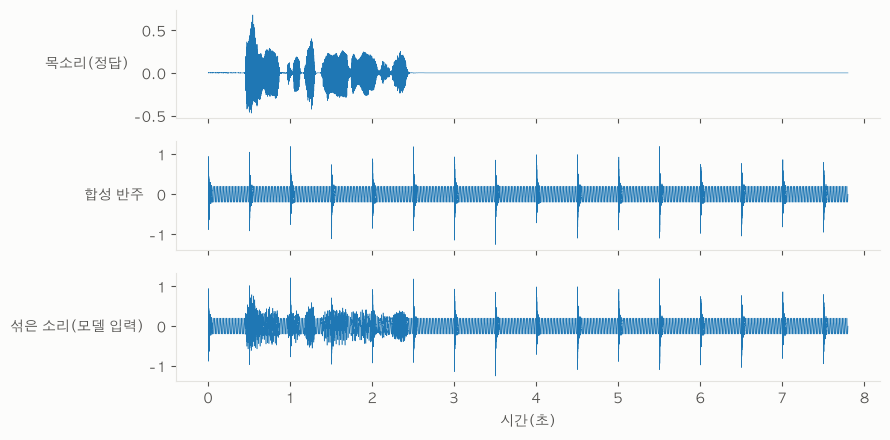

믹스 모양: (2, 343980) | 길이 7.8 초


In [9]:
# ── 6절: 합성 믹스 만들기 ────────────────────────────────────────────────────
# 하는 일: data/tts_cache/s01.wav(직접 쓴 예문 1번의 TTS)를 44.1 kHz 스테레오로 읽어 3초를 목소리(정답)로 쓰고,
#          55 Hz 저음 + 0.5초마다 울리는 잡음 타격을 반주로 더해 7.8초 믹스를 만든다(7.8초 = 모델의 학습 구간 길이).
SR = separate.MODEL_SR                                  # 44100
N = int(float(model.segment) * SR)                       # 343980 표본
voice = np.zeros((2, N), np.float32)
speech = separate.load_clip("data/tts_cache/s01.wav", 0.0, 3.0)    # (2, 표본): 앱의 구간 읽기 함수 재사용
voice[:, :speech.shape[1]] = speech[:, :N]
t = np.arange(N) / SR
rng = np.random.default_rng(0)                           # 시드 고정: 매번 같은 반주
bass = 0.2 * np.sin(2 * np.pi * 55 * t)
drums = np.zeros(N)
for k in range(0, N, SR // 2):
    L = min(int(0.05 * SR), N - k)
    drums[k:k + L] += rng.standard_normal(L) * np.exp(-np.arange(L) / (0.01 * SR)) * 0.4
accomp = np.stack([bass + drums] * 2).astype(np.float32)
mix = voice + accomp
fig, ax = plt.subplots(3, 1, figsize=(9, 4.5), sharex=True)
for a, x, name in zip(ax, [voice[0], accomp[0], mix[0]], ["목소리(정답)", "합성 반주", "섞은 소리(모델 입력)"]):
    a.plot(t, x, lw=0.4, color=theme.WAVEFORM); a.set_ylabel(name, rotation=0, ha="right", va="center")
ax[-1].set_xlabel("시간(초)"); plt.tight_layout(); plt.show()
print("믹스 모양:", mix.shape, "| 길이", round(N / SR, 2), "초")

## 7. 데이터의 모양은 층마다 어떻게 변하나 (forward hook)

**forward hook**은 "층이 계산을 끝낼 때마다 나에게 알려 줘"라고 걸어 두는 함수입니다. 모델을 고치지 않고 층의 입력·출력 모양을 기록할 수 있습니다. 여기서는 인코더·디코더·가운데 변환기·어텐션 모듈에 hook을 겁니다. **이 셀이 모델을 실제로 한 번 실행합니다(CPU 약 40초~1분).** 이 한 번의 실행 결과가 10절의 분리 결과로도 쓰입니다.

[수업에 없음] `register_forward_hook`: PyTorch의 기능으로, Keras의 중간 층 출력을 보려고 `Model(inputs, layer.output)`을 만드는 것과 같은 목적입니다.

In [10]:
# ── 7절-1: hook을 걸고 모델을 한 번 실행 ──────────────────────────────────────
# 하는 일: (1) 인코더/디코더/변환기 층의 입력·출력 모양, (2) 어텐션 모듈의 질의(query)·키(key) 모양을 기록한다.
#          (3) 같은 실행의 결과를 stems(분리된 4개 소리)로 저장한다. 입력 정규화는 separate.separate_vocals와 같은 방식.
def shape_of(o):
    if isinstance(o, torch.Tensor): return tuple(o.shape)
    if isinstance(o, (tuple, list)): return [shape_of(i) for i in o]
    return None
layer_rec, attn_rec, hooks = [], [], []
layer_names = [f"{p}.{i}" for p in ("tencoder", "encoder", "decoder", "tdecoder") for i in range(4)] + ["crosstransformer"]
for name, mod in model.named_modules():
    if name in layer_names:
        hooks.append(mod.register_forward_hook(lambda m, a, o, n=name: layer_rec.append((n, [shape_of(x) for x in a if x is not None and not isinstance(x, int)], shape_of(o)))))
    if isinstance(mod, torch.nn.MultiheadAttention):
        def h(m, args, kwargs, out, n=name):
            q = args[0] if args else kwargs["query"]; k = args[1] if len(args) > 1 else kwargs["key"]
            attn_rec.append((n, tuple(q.shape), tuple(k.shape)))
        hooks.append(mod.register_forward_hook(h, with_kwargs=True))

x = torch.from_numpy(mix)[None]                                  # (1, 2, 표본) = 배치 1개
ref = x.mean(1); mean, std = ref.mean(), ref.std()
t0 = time.time()
with torch.no_grad():                                            # 기울기 계산을 끄면 메모리·시간이 줄어든다
    stems = model((x - mean) / std) * std + mean                 # (1, 4, 2, 표본): 4개 소리
elapsed = time.time() - t0
for h_ in hooks: h_.remove()                                     # hook 정리(다음 실행에 영향 없게)
print(f"모델 한 번 실행: {elapsed:.0f}초 | 출력 모양 {tuple(stems.shape)} = (배치, 소리 4개, 채널 2, 표본)")

모델 한 번 실행: 212초 | 출력 모양 (1, 4, 2, 343980) = (배치, 소리 4개, 채널 2, 표본)


In [12]:
# ── 7절-2: 층별 모양 표 ───────────────────────────────────────────────────────
# 하는 일: 기록한 모양을 표로 보여 준다. 파형 가지는 (배치, 채널, 시간), 스펙트로그램 가지는 (배치, 채널, 주파수, 시간) 모양이다.
tab = pd.DataFrame([{"층": n, "입력 모양": s_in[0] if len(s_in) == 1 else s_in, "출력 모양": s_out} for n, s_in, s_out in layer_rec])
pd.set_option("display.max_colwidth", 80, "display.width", 200)
display(tab)

,층,입력 모양,출력 모양
0,tencoder.0,"(1, 2, 343980)","(1, 48, 85995)"
1,encoder.0,"(1, 4, 2048, 336)","(1, 48, 512, 336)"
2,tencoder.1,"(1, 48, 85995)","(1, 96, 21499)"
3,encoder.1,"(1, 48, 512, 336)","(1, 96, 128, 336)"
4,tencoder.2,"(1, 96, 21499)","(1, 192, 5375)"
5,encoder.2,"(1, 96, 128, 336)","(1, 192, 32, 336)"
6,tencoder.3,"(1, 192, 5375)","(1, 384, 1344)"
7,encoder.3,"(1, 192, 32, 336)","(1, 384, 8, 336)"
8,crosstransformer,"[(1, 512, 8, 336), (1, 512, 1344)]","[(1, 512, 8, 336), (1, 512, 1344)]"
9,decoder.0,"[(1, 384, 8, 336), (1, 384, 8, 336)]","[(1, 192, 32, 336), (1, 384, 8, 336)]"


### 모양이 알려 주는 것 (위 표의 숫자와 직접 대조하세요)

**[확인: 11-06 실행 값, 7.8초 믹스]**
- **시간(파형) 가지** `tencoder`: 길이 343,980 → 85,995 → 21,499 → 5,375 → 1,344 (한 층마다 **약 1/4**), 채널 2 → 48 → 96 → 192 → 384(첫 층 이후 **2배씩**). 수업 CNN의 "합성곱+스트라이드로 크기↓ 채널↑"과 같은 모양입니다.
- **스펙트로그램 가지** `encoder`: 입력 (4, 2048, 336)에서 주파수 칸이 2048 → 512 → 128 → 32 → 8(**1/4씩**), 시간 칸(336)은 유지, 채널 4 → 48 → 96 → 192 → 384.
  - 입력 채널 **4** = 스테레오 2채널 × (실수부, 허수부): `cac=True`가 복소수를 실수 2채널로 풀어 쌓기 때문입니다.
  - 주파수 칸 **2048** = `nfft 4096`의 절반, 시간 칸 **336** ≈ 343,980 ÷ `hop 1024` (5절 해상도와 일치).
- **디코더**는 인코더의 반대로 길이·주파수 칸을 4배씩 키우고 채널을 줄입니다. 마지막 `tdecoder.3`의 출력 (8, 343,980)은 **소리 4개 × 채널 2**가 원래 길이로 복원된 것입니다. 스펙트로그램 쪽 마지막 `decoder.3` 출력 (16, 2048, 336)은 **소리 4 × 채널 2 × (실수·허수)** 로 읽을 수 있습니다 [추정: 16 = 4×2×2].
- **가운데 `crosstransformer`**: 두 가지가 같은 채널 수(512)로 맞춰져 들어갑니다(인코더의 384 → 512는 `forward`가 변환기 앞에서 부르는 `channel_upsampler`(스펙트로그램 가지, 펼친 `(f t)` 위에서)와 `channel_upsampler_t`(시간 가지)이고, 변환기 뒤에는 `channel_downsampler`로 다시 384로 줄입니다 [확인: 4절 `forward` 줄 번호 59~72]). 스펙트로그램 가지는 (512, 8, 336), 시간 가지는 (512, 1344)이고, 변환기에는 이것이 **한 줄로 펼쳐진 토큰**으로 들어갑니다(8절).

In [13]:
# ── 7절-3 (새): 숫자로 다시 따라가기 — 한 번의 입력이 지나간 길 ────────────────────────────────
# 하는 일: 6절의 믹스가 모델에 들어가는 모양을 **계산으로 다시 만들어** 보고(STFT 설정 → (4, 2048, 336)),
#          층 하나(tencoder.0)를 열어 "왜 이 모양이 되나"를 숫자로 설명한다. 출력 모양을 외우는 대신 **계산식으로 재현**하는 연습.
# 필요: 6절(mix), 7절-1(layer_rec)을 먼저 실행. [수업에 없음] model._spec/_magnitude(소스 확인용 내부 함수), 합성곱 출력 길이 공식
need = [v for v in ("mix", "layer_rec", "model") if v not in globals()]
if need:
    raise RuntimeError(f"먼저 실행할 셀: 6절(mix), 7절-1(layer_rec). 지금 없는 변수: {need}")
rec = {n: (i, o) for n, i, o in layer_rec}                    # {층 이름: (입력 모양, 출력 모양)}
SRm, n_samples = model.samplerate, mix.shape[1]
print(f"[입력] 섞은 소리: {mix.shape[0]}채널 × {n_samples:,}표본 = {n_samples / SRm:.1f}초 × {SRm:,} Hz   ← 모델이 받는 것은 이것 하나뿐")

# (a) 스펙트로그램 가지의 입력을 계산으로 재현
with torch.no_grad():
    z = model._spec(torch.from_numpy(mix)[None])                # STFT → 복소수 (배치, 채널, 주파수, 시간)
    mag = model._magnitude(z)                                    # cac=True: 복소수를 (실수, 허수) 채널로 풀어 쌓음
print("\n[스펙트로그램 가지의 입력]")
print(f"  STFT 설정 nfft={model.nfft}, hop={model.hop_length} → 복소수 {tuple(z.shape)} = (배치, 스테레오 2, 주파수 칸, 시간 칸)")
print(f"  주파수 칸 2048 = nfft/2.  한 칸 = {SRm / model.nfft:.2f} Hz  →  2048칸 × {SRm / model.nfft:.2f} Hz ≈ {2048 * SRm / model.nfft:,.0f} Hz (= 표본화 주파수의 절반)")
print(f"  시간 칸 336 ≈ {n_samples:,} ÷ hop {model.hop_length} = {n_samples / model.hop_length:.1f}  →  한 칸 = {model.hop_length / SRm * 1000:.1f} ms")
print(f"  실수로 풀기: {tuple(mag.shape)}  → 채널 4 = 스테레오 2 × (실수부, 허수부)   [기록된 encoder.0 입력: {rec['encoder.0'][0][0]}]")

# (b) 층 하나 열어 보기: tencoder.0
conv = model.tencoder[0].conv
n_out = (n_samples + 2 * conv.padding[0] - conv.kernel_size[0]) // conv.stride[0] + 1
print("\n[tencoder.0 한 층]", conv)
print(f"  출력 길이 = ⌊(입력 {n_samples:,} + 2×패딩 {conv.padding[0]} − 커널 {conv.kernel_size[0]}) ÷ 스트라이드 {conv.stride[0]}⌋ + 1 = {n_out:,}"
      f"   (기록된 출력: {rec['tencoder.0'][1]}  → 같다: {n_out == rec['tencoder.0'][1][2]})")
n_w = conv.weight.numel()
print(f"  이 층의 가중치 = 필터 {conv.out_channels}개 × (입력 채널 {conv.in_channels} × 길이 {conv.kernel_size[0]}) = {n_w}개 → 이 숫자들이 학습으로 정해진다")

# (c) 단계마다 모양과 "원소 수"(채널 × 길이): 시간을 줄이는 대신 채널로 옮긴다
rows = []
for k in range(4):
    c_t, c_f = model.tencoder[k].conv.out_channels, model.encoder[k].conv.out_channels
    o_t, o_f = rec[f"tencoder.{k}"][1], rec[f"encoder.{k}"][1]
    rows.append({"단계": k, "파형 가지 (채널, 길이)": f"({o_t[1]}, {o_t[2]:,})", "원소 수": o_t[1] * o_t[2],
                 "스펙트로그램 가지 (채널, 주파수, 시간)": f"({o_f[1]}, {o_f[2]}, {o_f[3]})", "원소 수 ": o_f[1] * o_f[2] * o_f[3]})
tab = pd.DataFrame(rows)
display(tab)
print(f"입력의 원소 수: 파형 {mix.shape[0] * n_samples:,}  /  스펙트로그램 {mag.shape[1] * mag.shape[2] * mag.shape[3]:,}")
print(f"파형 가지 마지막 한 칸의 간격 = {n_samples / rec['tencoder.3'][1][2]:.0f}표본 = {n_samples / rec['tencoder.3'][1][2] / SRm * 1000:.1f} ms  (원래는 1표본 = {1 / SRm * 1000:.3f} ms)")

[입력] 섞은 소리: 2채널 × 343,980표본 = 7.8초 × 44,100 Hz   ← 모델이 받는 것은 이것 하나뿐

[스펙트로그램 가지의 입력]
  STFT 설정 nfft=4096, hop=1024 → 복소수 (1, 2, 2048, 336) = (배치, 스테레오 2, 주파수 칸, 시간 칸)
  주파수 칸 2048 = nfft/2.  한 칸 = 10.77 Hz  →  2048칸 × 10.77 Hz ≈ 22,050 Hz (= 표본화 주파수의 절반)
  시간 칸 336 ≈ 343,980 ÷ hop 1024 = 335.9  →  한 칸 = 23.2 ms
  실수로 풀기: (1, 4, 2048, 336)  → 채널 4 = 스테레오 2 × (실수부, 허수부)   [기록된 encoder.0 입력: (1, 4, 2048, 336)]

[tencoder.0 한 층] Conv1d(2, 48, kernel_size=(8,), stride=(4,), padding=(2,))
  출력 길이 = ⌊(입력 343,980 + 2×패딩 2 − 커널 8) ÷ 스트라이드 4⌋ + 1 = 85,995   (기록된 출력: (1, 48, 85995)  → 같다: True)
  이 층의 가중치 = 필터 48개 × (입력 채널 2 × 길이 8) = 768개 → 이 숫자들이 학습으로 정해진다


,단계,"파형 가지 (채널, 길이)",원소 수,"스펙트로그램 가지 (채널, 주파수, 시간)",원소 수
0,0,"(48, 85,995)",4127760,"(48, 512, 336)",8257536
1,1,"(96, 21,499)",2063904,"(96, 128, 336)",4128768
2,2,"(192, 5,375)",1032000,"(192, 32, 336)",2064384
3,3,"(384, 1,344)",516096,"(384, 8, 336)",1032192


입력의 원소 수: 파형 687,960  /  스펙트로그램 2,752,512
파형 가지 마지막 한 칸의 간격 = 256표본 = 5.8 ms  (원래는 1표본 = 0.023 ms)


> 📝 **보충 (11-10)**: 위 출력의 "**768개**"는 **가중치만** 센 값입니다. 필터마다 **bias 1개**(48개)가 더 있어 이 층이 학습하는 숫자는 **768 + 48 = 816개**입니다 → 코드로 확인은 아래 **7-3 보충 ④**.

### 7-3절 읽는 법: `tencoder.0` 한 층을 끝까지 설명해 보기 (위 출력과 대조)

입력 `(1, 2, 343,980)` → **Conv1d** → 출력 `(1, 48, 85,995)`. 네 가지 "왜?"에 숫자로 답합니다 **[확인: 11-09 실행]**.

1. **왜 입력 채널이 2개인가?** 스테레오(좌·우)라서입니다.
2. **왜 출력 채널이 48개인가?** 이 층이 **길이 8짜리 필터 48개**(`channels=48` 설정)를 갖기 때문입니다. 필터 하나가 "소리의 어떤 패턴이 있는가"를 한 줄의 숫자열로 만들어 내서 **필터 개수 = 출력 채널 수**입니다. 필터 값(가중치)은 학습으로 정해지므로 **각 채널이 무슨 패턴을 담당하는지는 이 노트북만으로는 알 수 없습니다**(예시로 "짧은 순간의 변화, 주기적인 진동" 같은 설명은 가능한 해석일 뿐입니다 [추정]).
3. **왜 길이가 약 1/4로 줄었는가?** `stride=4`, 즉 필터가 **4칸씩 건너뛰며** 놓이기 때문입니다. 위 계산식이 기록값 85,995와 같습니다. 4층을 지나면 `343,980 → 1,344`(약 1/256)입니다.
4. **이 변화가 다음 층에 주는 의미**: 마지막 단계의 한 칸이 원래 소리의 약 **256표본(5.8 ms)** 간격이 됩니다. 칸 수는 줄었지만 한 칸이 **더 긴 시간 범위**를 요약하고, 채널이 384개로 늘어서 요약 정보를 담을 자리가 생깁니다.

**원소 수(채널 × 길이)로 보면** 파형 가지는 `2×343,980 = 687,960`에서 단계 0에서 오히려 **늘었다가**(4.1M) 단계마다 **절반**으로 줄어 마지막에 약 52만 개가 됩니다. 스펙트로그램 가지는 입력 275만 개 → 마지막 103만 개입니다. 즉 **시간·주파수를 줄이고 그 정보를 채널로 옮기는 "압축"** 입니다(수업 CNN의 "크기↓ 채널↑"). 이 압축된 표현 위에서만 가운데 Transformer가 일합니다. 압축하지 않으면 토큰이 343,980개라 어텐션 점수 표가 약 1,180억 칸이 되어 계산이 불가능합니다 **[확인: 343,980² ≈ 1.18×10¹¹, 계산]**.

> 스펙트로그램 가지는 시간 칸(336)이 그대로이고 **주파수 칸만** 2048 → 512 → 128 → 32 → 8로 1/4씩 줄어듭니다(`Conv2d`의 커널·스트라이드가 `(8, 1)`·`(4, 1)`이라 주파수 방향으로만 건너뜀 [확인: `model.encoder[0].conv`]).

### 7-3 보충: 출력 길이 공식, Conv1d·Conv2d·Conv3d, 48이라는 숫자, 학습되는 숫자 세기 (11-10, 내 질문 2·11)

**① 위 계산식은 정해진 공식입니다.** PyTorch가 임의로 정한 규칙이 아니라 "커널이 입력 안에 완전히 놓일 수 있는 횟수"에서 나옵니다 [일반 지식; 아래 코드가 기록값 4개를 재현하는 것으로 확인].

$$L_{out}=\left\lfloor\frac{L_{in}+2P-D(K-1)-1}{S}\right\rfloor+1$$

($K$ 커널 크기, $S$ stride, $P$ padding, $D$ dilation(커널 원소 사이 간격, 기본 1)). 실제로 커널이 차지하는 폭이 $D(K-1)+1$이고, 끝에서 **온전히 놓이지 못하는 자리는 버리므로** 내림(floor)이 붙습니다. 첫 층은 $K=8,\ S=4,\ P=2,\ D=1$이라 $\lfloor (343{,}980+4-8)/4\rfloor+1 = 85{,}995$입니다.
**층이 이어질 때의 한 가지**: 파형 가지의 `HEncLayer.forward`는 길이가 stride의 배수가 아니면 **끝을 0으로 채웁니다**(`F.pad`, 소스 확인). 85,995는 4의 배수가 아니라 한 칸을 채운 뒤 21,499가 됩니다 — 아래 코드에 이 규칙이 들어 있습니다.

**② Conv1d·Conv2d·Conv3d는 "입력이 몇 차원인가"가 아니라 "커널이 몇 개의 축을 따라 움직이는가"의 차이입니다** [일반 지식]. Conv1d도 입력 텐서는 3개 축(배치·채널·시간)을 가집니다.

| 종류 | 입력 텐서 | 커널이 움직이는 축 | 쓰이는 곳 | 이 모델 |
|---|---|---|---|---|
| Conv1d | `(N, C, L)` | 1개(시간) | 파형, 시계열 | **파형 가지** |
| Conv2d | `(N, C, H, W)` | 2개 | 이미지, 스펙트로그램 | **스펙트로그램 가지** `(N, C, 주파수, 시간)` |
| Conv3d | `(N, C, D, H, W)` | 3개 | 3D 의료 영상, 동영상 | 사용 안 함 |

스펙트로그램 가지의 첫 Conv2d는 커널 `(8, 1)`·stride `(4, 1)`이라 **주파수 방향으로만** 8칸을 보고 4칸씩 움직이고, 시간 방향은 1칸이라 칸 수가 그대로입니다(위 7-3절의 `(8, 1)`·`(4, 1)`).

**③ 층 0의 "48"은 어디서 나왔나** — 입력 길이로 계산되는 숫자도, 학습으로 정해진 가중치도 **아닙니다.** 모델을 **설계할 때 정한 설정(하이퍼파라미터)** 입니다: `channels=48`(첫 인코더의 출력 채널 수), `growth=2`(층마다 2배), `depth=4`(층 수), `kernel_size=8`, `stride=4` [확인: 3절-2 표의 depth/channels, `htdemucs.py` 기본값]. 그 결과가 채널 48 → 96 → 192 → 384(7절 기록)입니다. 설정이 **필터의 개수와 연결 구조**를 정하고, 학습은 **그 필터 안의 숫자**를 정합니다.

**④ 학습되는 숫자 세기 — bias를 잊지 마세요.** 위 7-3절의 "768개"(= 48 × 2 × 8)는 **가중치만** 센 값입니다. 필터마다 **bias 1개**가 더 있어(48개) 이 층이 학습하는 숫자는 **768 + 48 = 816개**입니다.

In [ ]:
# ── 7-3절 보충 (새, 11-10): Conv 출력 길이 공식과 학습되는 숫자(가중치·bias) 직접 세어 보기 ─────────────────
# 하는 일: ① 합성곱 출력 길이 공식을 함수로 만들어 인코더 4층의 기록값(85,995 → … → 1,344)을 재현한다.
#          ② 첫 층 Conv1d(파형 가지)와 Conv2d(스펙트로그램 가지)의 가중치·bias 개수를 모델에서 직접 센다.
# 필요: 3절-2의 `model`(없으면 아래에서 다시 불러옴). [수업에 없음] 합성곱 출력 길이의 일반식(수업 006 CNN은 "크기가 줄어든다"까지)
if "model" not in globals():
    from demucs.pretrained import get_model
    model = get_model("htdemucs").models[0].eval()

def conv_out_len(L, K, S, P=0, D=1):
    """Conv1d 출력 길이 = floor((L + 2P - D(K-1) - 1) / S) + 1  (D: dilation, 기본 1)"""
    return (L + 2 * P - D * (K - 1) - 1) // S + 1

L, lens = 343_980, []
for i, enc in enumerate(model.tencoder):
    c = enc.conv                                            # 층 i의 Conv1d
    K, S, P = c.kernel_size[0], c.stride[0], c.padding[0]
    L += (-L) % S                                           # HEncLayer.forward가 stride의 배수가 되게 끝을 0으로 채움(소스 확인)
    L = conv_out_len(L, K, S, P)
    lens.append(L)
print("공식으로 계산한 파형 가지 길이:", " → ".join(f"{v:,}" for v in [343_980] + lens), "(7절 기록: 343,980 → 85,995 → 21,499 → 5,375 → 1,344)")

c1, c2 = model.tencoder[0].conv, model.encoder[0].conv
for name, c in [("파형 가지 첫 층 Conv1d", c1), ("스펙트로그램 가지 첫 층 Conv2d", c2)]:
    w, b = c.weight.numel(), c.bias.numel()
    print(f"{name}: 가중치 모양 {tuple(c.weight.shape)} = {w:,}개, bias {b}개 → 학습되는 숫자 {w + b:,}개")

공식으로 계산한 파형 가지 길이: 343,980 → 85,995 → 21,499 → 5,375 → 1,344 (7절 기록: 343,980 → 85,995 → 21,499 → 5,375 → 1,344)
파형 가지 첫 층 Conv1d: 가중치 모양 (48, 2, 8) = 768개, bias 48개 → 학습되는 숫자 816개
스펙트로그램 가지 첫 층 Conv2d: 가중치 모양 (48, 4, 8, 1) = 1,536개, bias 48개 → 학습되는 숫자 1,584개

#### 위 출력 읽는 법 [확인: 11-10 내 실행(헤드리스), 위 출력]
- 공식으로 계산한 파형 가지 길이가 **7절의 기록값과 4개 모두 같습니다**(85,995 · 21,499 · 5,375 · 1,344). 즉 7절의 "왜 이 모양인가"를 **설정값(K=8, S=4, P=2)만으로 재현**할 수 있습니다.
- 스펙트로그램 가지 첫 층은 가중치 `(48, 4, 8, 1)` = 48 × 4 × 8 × 1 = 1,536개 + bias 48 = 1,584개입니다. 입력 채널이 2가 아니라 4인 것은 실수·허수 때문(2-3절).

### 7-3 보충 2: 합성곱을 손으로 — 커널 `[1, 0, -1]`, "뒤집지 않는" 합성곱, 가중치 공유, 채널이 늘어나는 이유 (11-11, 보충자료)

**① 가장 작은 합성곱.** 입력 $X=[1,2,3,4,5]$에 커널 $W=[1,0,-1]$을 한 칸씩 옮기며 **곱해서 더하면** $y_i=x_i-x_{i+2}$입니다. 앞쪽 값과 뒤쪽 값의 **차이**를 재는 필터라서, 계속 **증가**하는 입력에서는 $-2$, 계속 **감소**하는 입력 $[5,4,3,2,1]$에서는 $+2$가 나옵니다. 합성곱 필터는 이렇게 **"이웃 값이 어떻게 변하는가"** 에 반응하는 작은 탐지기이고, 학습은 이 커널 숫자를 정합니다 [일반 지식 + 아래 코드].

**② PyTorch의 `Conv1d`는 커널을 뒤집지 않습니다.** 수학 교과서의 합성곱은 커널을 **뒤집어서** 곱하지만, 딥러닝 프레임워크의 `Conv1d`·`Conv2d`는 **뒤집지 않는 상호상관(cross-correlation)** 을 씁니다. 커널 값이 학습으로 정해지므로 뒤집어도 같은 종류의 필터가 학습되어 구분할 실익이 없어서 그냥 "합성곱"이라 부릅니다 [일반 지식, 아래 코드로 두 계산의 차이를 확인].

**③ 가중치 공유.** **같은 커널**을 모든 위치에 적용합니다. 그래서 (a) 학습하는 숫자 수가 **입력 길이와 무관**하고(층 0은 7-3 보충의 816개 그대로), (b) 패턴이 **어느 위치에 나와도** 같은 필터가 반응합니다. 아래 코드는 (a)를 숫자로 보입니다 [일반 지식 + 계산].

**④ 채널이 $2\to48\to96\to192\to384$로 늘어나는 이유.** 시간·주파수 칸 수는 줄이면서(압축) 채널 수는 늘려 **서로 다른 종류의 특징을 더 많이** 담으려는 설계입니다. 채널마다 **별도의 학습된 커널**이 있습니다. 다만 "48채널 중 몇 번이 보컬, 몇 번이 드럼"처럼 **악기를 전담하는 것은 아니고**, 여러 채널이 함께 소리의 다양한 음향 패턴을 표현합니다. 어느 채널이 무엇에 반응하는지는 **가중치·활성화를 꺼내 보지 않아 이 노트북은 모릅니다** [미확인].

In [ ]:
# ── 7-3 보충 2 (새, 11-11): 손으로 해 보는 합성곱, 뒤집기 여부, 가중치 공유의 크기 ─────────────────────
# 하는 일: 커널 [1,0,-1]을 [1..5]에 적용하고, 커널을 뒤집는 진짜 합성곱과의 차이를 보고, 층 0의 파라미터 수가 입력 길이와 무관함을 센다.
import numpy as np
def corr(x, w):                                   # 딥러닝의 Conv1d가 하는 일: 뒤집지 않고 곱해서 더하기(상호상관)
    return np.array([(x[i:i + len(w)] * w).sum() for i in range(len(x) - len(w) + 1)])
X, W = np.array([1, 2, 3, 4, 5.]), np.array([1, 0, -1.])
print("증가하는 입력 [1..5] →", corr(X, W), "| 감소하는 입력 [5..1] →", corr(X[::-1], W))
print("np.correlate('valid')와 같은가:", np.allclose(corr(X, W), np.correlate(X, W, "valid")))
print("커널을 뒤집는 수학적 합성곱 np.convolve('valid') →", np.convolve(X, W, "valid"), " (부호가 반대: 뒤집었기 때문)")
params = 48 * 2 * 8 + 48                          # 층 0: 출력 채널 48 × 입력 채널 2 × 커널 8 + bias 48 (7-3 보충의 816)
for L in (343_980, 100_000, 1_000):
    print(f"입력 길이 {L:>7,} → 층 0이 학습하는 숫자 {params}개 (길이와 무관)")
L_out = 85_995                                    # 층 0 출력 길이(7절 기록)
print(f"만약 위치마다 따로 가중치를 두는 완전연결이라면: 입력 2×343,980 → 출력 48×{L_out:,} = {2 * 343_980 * 48 * L_out:,}개 필요")

증가하는 입력 [1..5] → [-2. -2. -2.] | 감소하는 입력 [5..1] → [2. 2. 2.]
np.correlate('valid')와 같은가: True
커널을 뒤집는 수학적 합성곱 np.convolve('valid') → [2. 2. 2.]  (부호가 반대: 뒤집었기 때문)
입력 길이 343,980 → 층 0이 학습하는 숫자 816개 (길이와 무관)
입력 길이 100,000 → 층 0이 학습하는 숫자 816개 (길이와 무관)
입력 길이   1,000 → 층 0이 학습하는 숫자 816개 (길이와 무관)
만약 위치마다 따로 가중치를 두는 완전연결이라면: 입력 2×343,980 → 출력 48×85,995 = 2,839,733,769,600개 필요


### 7-3 보충 3: 디코더는 어떻게 크기를 되돌리나 — 전치 합성곱(`ConvTranspose`)의 출력 길이 (11-11, 보충자료)

인코더의 `Conv`가 길이를 **줄인다면**, 디코더의 **전치 합성곱**은 길이를 **늘립니다.** 출력 길이는 이렇습니다 [일반 지식].

$$L_{out}=(L_{in}-1)\,S-2P+D(K-1)+P_{out}+1$$

($S$ stride, $P$ padding, $D$ dilation, $K$ 커널, $P_{out}$ output_padding). 예: $L_{in}=4$, $K=4$, $S=2$, $P=1$이면 $(4-1)\cdot2-2+3+1=8$, 즉 **4 → 8**로 두 배가 됩니다. 두 가지를 구분합니다.
- **"원래 합성곱의 정확한 역연산"이 아닙니다.** 줄어든 길이를 **키우는 학습되는 연산**일 뿐이고, 압축 때 사라진 세부가 저절로 돌아오지는 않습니다(그래서 4-3절의 건너뛰기 더하기가 필요합니다).
- **Demucs의 실제 설정**: 시간 가지 디코더는 `ConvTranspose1d(kernel 8, stride 4, padding 0)`입니다 [확인: 11-11 이 컴퓨터에서 `tdecoder.0~3.conv_tr` 설정 출력]. 공식대로 1,344 → **5,380**이 나오고, 소스(`HDecLayer.forward`)가 **앞뒤를 `pad = 2`칸씩 잘라(`z[..., pad:pad+length]`) 목표 길이 5,375**에 맞춥니다 [확인: 소스 줄과 `tdecoder.0.pad == 2`]. 그래서 7절의 `(192, 5375)`가 나옵니다. **공식의 $P=0$이 아니라 "크게 만든 뒤 자른다"** 는 점이 교과서 예와 다릅니다.

In [ ]:
# ── 7-3 보충 3 (새, 11-11): 전치 합성곱의 출력 길이 — 교과서 예(4→8)와 Demucs 설정(1344→5380→5375) ──────
# 하는 일: ConvTranspose1d에 0 입력을 넣어 출력 길이만 본다. 필요: torch(Demucs 환경에 이미 있음).
import torch
f = lambda Lin, S, P, D, K, Pout: (Lin - 1) * S - 2 * P + D * (K - 1) + Pout + 1
print("공식 (4,S=2,P=1,K=4) =", f(4, 2, 1, 1, 4, 0), "| 실제 ConvTranspose1d:", tuple(torch.nn.ConvTranspose1d(1, 1, kernel_size=4, stride=2, padding=1)(torch.zeros(1, 1, 4)).shape))
ct = torch.nn.ConvTranspose1d(384, 192, kernel_size=8, stride=4)           # tdecoder.0.conv_tr와 같은 설정(채널 384 → 192)
y = ct(torch.zeros(1, 384, 1344))
print("Demucs 시간 가지 설정: 입력 1344 → 출력", y.shape[-1], f"(공식 {f(1344, 4, 0, 1, 8, 0)})")
pad, length = 2, 5375                          # 소스: z = z[..., pad:pad+length], tdecoder.0.pad == 2, 목표 길이는 인코더 기록의 5375
print(f"앞 {pad}칸을 버리고 {length}칸을 취함 → 길이 {y[..., pad:pad + length].shape[-1]}  (7절 기록의 tdecoder.0 출력 길이 5375와 같다)")

공식 (4,S=2,P=1,K=4) = 8 | 실제 ConvTranspose1d: (1, 1, 8)
Demucs 시간 가지 설정: 입력 1344 → 출력 5380 (공식 5380)
앞 2칸을 버리고 5375칸을 취함 → 길이 5375  (7절 기록의 tdecoder.0 출력 길이 5375와 같다)


## 7-4. CNN 인코더의 출력은 "특징 벡터의 열"이다 — 문장처럼 읽어 보기 (11-10)

2-2절의 말로 7절의 숫자를 다시 읽습니다. 마지막 인코더 단계의 출력 `(1, 384, 1344)`와 `(1, 384, 8, 336)`은 가운데 Transformer에 들어가기 직전의 모양입니다. Transformer(와 LSTM)는 **"벡터가 T개 줄지어 있는 것"** 만 받으므로, 이 텐서를 **토큰의 열**로 바꿔 읽습니다.
- 시간(파형) 가지: `(배치, 채널 384, 시간 칸 1344)` → **시간 칸 하나가 토큰 하나**, 토큰의 차원은 채널 384.
- 스펙트로그램 가지: `(배치, 채널 384, 주파수 8, 시간 336)` → **(시간 칸, 주파수 칸) 한 쌍이 토큰 하나** → 336 × 8 = 2,688개.

자연어로 치면 "1,344개 단어짜리 문장"과 "2,688개 단어짜리 문장" 두 개를 만들어 서로 참조하게 하는 것입니다. 단어 사이에는 **순서**가 있고(시간), 스펙트로그램 문장에는 **주파수 위치**도 있다는 점이 다릅니다(위치 정보는 8-5절).

In [ ]:
# ── 7절-4 (새): CNN 인코더의 출력은 "특징 벡터의 열"이다 — 문장처럼 읽어 보기 ──────────────────────────────
# 하는 일: 7절-1에서 기록한 마지막 인코더 단계의 모양을 "토큰의 열"로 다시 읽는다. 모양만 필요해서 값은 0으로 채운다.
# 필요: 7절-1(layer_rec)을 먼저 실행. [수업에 없음] einops.rearrange(demucs가 쓰는 같은 함수): 축 이름으로 모양을 바꾸는 도구
need = [v for v in ("layer_rec",) if v not in globals()]
if need:
    raise RuntimeError(f"먼저 실행할 셀: 7절-1(layer_rec). 지금 없는 변수: {need}")
import torch
from einops import rearrange
rec = {n: (i, o) for n, i, o in layer_rec}
t_shape, s_shape = rec["tencoder.3"][1], rec["encoder.3"][1]            # (1, 384, 1344), (1, 384, 8, 336)
xt, xs = torch.zeros(t_shape), torch.zeros(s_shape)
tok_t = rearrange(xt, "b c t -> b t c")                                    # 시간 가지: 칸 1,344개 × 벡터 384차원
tok_s = rearrange(xs, "b c f t -> b (t f) c")                              # 스펙트로그램 가지: (시간 칸 × 주파수 칸)개 × 벡터 384차원 (소스 CrossTransformerEncoder.forward와 같은 식)
print(f"[시간(파형) 가지]   인코더 출력 {t_shape} (배치, 채널, 시간 칸) → 토큰 열 {tuple(tok_t.shape)} = '단어' {tok_t.shape[1]:,}개, 각각 {tok_t.shape[2]}차원 벡터")
print(f"[스펙트로그램 가지] 인코더 출력 {s_shape} (배치, 채널, 주파수 칸, 시간 칸) → 토큰 열 {tuple(tok_s.shape)} = '단어' {tok_s.shape[1]:,}개 (= 시간 {s_shape[3]} × 주파수 {s_shape[2]}), 각각 {tok_s.shape[2]}차원")
n_samples = rec["tencoder.0"][0][0][2]                                     # 첫 층의 입력 (배치, 채널, 표본) 중 표본 수
SRm = 44100                                                                  # htdemucs의 표본화 주파수(7-3절의 model.samplerate)
print(f"\n시간 가지 토큰 한 개 = 원래 소리의 약 {n_samples / tok_t.shape[1]:.0f}표본 ≈ {n_samples / tok_t.shape[1] / SRm * 1000:.1f} ms 간격")
print(f"스펙트로그램 가지 토큰은 시간 칸 한 개가 hop 1024표본 ≈ {1024 / SRm * 1000:.1f} ms 간격이고, 주파수 칸 {s_shape[2]}개가 0~{SRm // 2:,} Hz를 나눠 맡는다")
print("\n비교(수업 6강, lesson06 실습 3-1): 음성 특징 (1, T, 40) = 프레임 T개 × Log-Mel 40차원  ← 같은 '벡터의 열' 모양이다")
print("그 뒤에 변환기 앞의 1×1 합성곱(channel_upsampler)이 각 토큰을 384 → 512차원으로 바꾼다(7절 해설).")

### 7-4절 읽는 법 [확인: 11-10 내 실행, 값은 7절의 기록에서]
- **토큰 한 개가 무엇을 요약하나**: 시간 가지는 원래 소리의 약 **256표본(5.8 ms)** 간격, 스펙트로그램 가지는 STFT의 **시간 칸 1개(약 23.2 ms)** 와 주파수 칸 1개입니다. 다만 CNN을 4층 지나며 한 칸이 보는 범위가 겹치며 넓어지므로(수용 영역), 위 간격은 **칸의 위치 간격**이지 토큰이 담은 정보의 길이가 아닙니다 [추정: 일반적인 CNN 성질].
- **384 → 512**: 변환기 앞의 `channel_upsampler`(1×1 합성곱)가 토큰마다 차원을 늘립니다(7절의 해설). 토큰 하나 = 512차원 벡터, 이것이 수업 008의 "단어 하나 = 임베딩 벡터"에 해당합니다.
- **수업 6강과 비교**: lesson06의 음성 특징 `(1, T, 40)`은 **사람이 정한 공식**(STFT·Mel·로그, 03·04강)으로 만든 벡터의 열이고, Demucs의 `(1, 1344, 384)`는 **학습된 필터**(CNN, 4,198만 개 중 인코더·디코더 22%)로 만든 벡터의 열입니다. 둘 다 LSTM·Attention이 읽을 수 있는 같은 종류의 입력입니다. 다른 점은 **벡터를 만드는 규칙을 사람이 썼는가, 학습으로 정했는가**입니다.
- **한계 [미확인]**: 토큰 한 칸의 384개 숫자가 소리의 어떤 성질을 담는지는 학습 결과라서 이 노트북으로는 해석하지 못했습니다.

## 7-5. 층마다 어떤 활성화 함수가 쓰이나 (11-10, 내 질문 8)

**활성화 함수가 필요한 이유**: 합성곱·선형 층만 이어 붙이면 전체가 **하나의 선형 변환**과 다르지 않아서, 사이에 비선형 함수를 넣어야 복잡한 패턴을 표현할 수 있습니다(수업 006 CNN의 ReLU와 같은 이유 [수업 + 일반 지식]).

| 이름 | 하는 일 | Demucs에서 |
|---|---|---|
| **GELU** | $x\Phi(x)$ ($\Phi$ = 표준정규분포의 누적분포). ReLU처럼 음수를 0으로 자르지 않고 **부드럽게** 줄임 | 인코더·디코더 층의 합성곱 뒤, DConv, Transformer의 FFN |
| **GLU** (Gated Linear Unit) | 채널을 **둘로 쪼개** $A\odot\sigma(B)$: $A$는 전할 특징, $B$는 **얼마나 통과시킬지**(게이트) → **채널이 절반**이 됨 | 인코더·디코더의 `rewrite` 합성곱 뒤(예: 96 → 48), DConv 끝 |
| **Softmax** | 어텐션 점수를 **합이 1인 가중치**로 바꿈 | `MultiheadAttention` 안(8절). 활성화라기보다 **정규화 연산** |

헷갈리기 쉬운 것: **GroupNorm·LayerNorm·LayerScale은 활성화 함수가 아니라** 값의 크기를 맞추거나 스케일을 학습하는 **정규화·스케일 층**입니다.

In [ ]:
# ── 7-5절 (새, 11-10): 층마다 어떤 활성화 함수·정규화가 쓰이나 — 모델에서 직접 세고 소스 줄을 읽기 ──────────────────
# 하는 일: ① 덩어리별(tencoder·encoder·tdecoder·decoder·crosstransformer)로 GELU·GLU·LayerNorm 등 "모듈로 들어 있는" 것을 센다.
#          ② 인코더·디코더 층의 forward 소스에서 F.gelu·F.glu처럼 **함수로 부르는** 줄을 찾는다(모듈로는 안 보이므로).
# 필요: 3절-2의 `model`. [수업에 없음] GELU, GLU(수업은 ReLU·sigmoid·softmax까지)
import collections, inspect, re
if "model" not in globals():
    from demucs.pretrained import get_model
    model = get_model("htdemucs").models[0].eval()
from demucs.hdemucs import HEncLayer, HDecLayer
kinds = ("GELU", "GLU", "ReLU", "Sigmoid", "Softmax", "LayerNorm", "GroupNorm", "LayerScale")
rows = []
for name in ("tencoder", "encoder", "tdecoder", "decoder", "crosstransformer"):
    cnt = collections.Counter(type(m).__name__ for m in getattr(model, name).modules())
    rows.append({"덩어리": name, **{k: cnt.get(k, 0) for k in kinds}})
display(pd.DataFrame(rows).set_index("덩어리"))
print("DConv(압축된 잔차 분기)가 있나:  인코더", hasattr(model.tencoder[0], "dconv") and model.tencoder[0].dconv is not None,
      "| 디코더", hasattr(model.tdecoder[0], "dconv") and model.tdecoder[0].dconv is not None)
print("변환기 FFN의 활성화:", model.crosstransformer.layers[0].activation.__name__ if hasattr(model.crosstransformer.layers[0].activation, "__name__") else model.crosstransformer.layers[0].activation)
for cls in (HEncLayer, HDecLayer):
    print(f"\n[{cls.__name__}.forward 소스 중 함수로 부르는 줄]")
    for ln in inspect.getsource(cls.forward).splitlines():
        if re.search(r"F\.gelu|F\.glu|self\.last|x = x \+ skip", ln):
            print("   ", ln.strip())
print("\n마지막 디코더 층의 last 값:", model.tdecoder[3].last, model.decoder[3].last, "| 앞 층:", model.tdecoder[0].last)

                  GELU  GLU  ReLU  Sigmoid  Softmax  LayerNorm  GroupNorm  LayerScale
덩어리                                                                                  
tencoder             8    8     0        0        0          0         16           8
encoder              8    8     0        0        0          0         16           8
tdecoder             8    8     0        0        0          0         16           8
decoder              8    8     0        0        0          0         16           8
crosstransformer     0    0     0        0        0         26          0          20
DConv(압축된 잔차 분기)가 있나:  인코더 True | 디코더 True
변환기 FFN의 활성화: gelu

[HEncLayer.forward 소스 중 함수로 부르는 줄]
    y = F.gelu(self.norm1(y))
    z = F.glu(z, dim=1)

[HDecLayer.forward 소스 중 함수로 부르는 줄]
    x = x + skip
    y = F.glu(self.norm1(self.rewrite(x)), dim=1)
    if not self.last:
    z = F.gelu(z)

마지막 디코더 층의 last 값: True True | 앞 층: False

#### 위 출력 읽는 법 [확인: 11-10 내 실행(헤드리스), 위 출력 + 소스]
- **인코더 한 층(`HEncLayer`)**: 합성곱(stride 4) → **GELU** → (DConv 분기) → `rewrite` 합성곱 → **GLU**. `norm1`·`norm2`는 `Identity`(실제 정규화 없음)이고 GroupNorm은 DConv 안에만 있습니다(표의 GroupNorm 16개).
- **디코더 한 층(`HDecLayer`)**: `x + skip` → `rewrite` 합성곱 → **GLU** → (DConv 분기) → `ConvTranspose` → **GELU, 단 마지막 층(`last=True`)은 GELU 없음** — 출력이 곧 소리(또는 스펙트로그램) 값이라 마지막에는 비선형을 걸지 않습니다 [추정: 이유의 해석, 소스는 `if not self.last`만 보여 줌].
- **함수로 부르는 것은 모듈 개수에 안 잡힙니다.** 표의 GELU·GLU 8개씩은 DConv 안의 모듈이고, 층 본체의 `F.gelu`·`F.glu`는 위 소스 줄에서만 보입니다(그래서 마지막 층의 GELU 생략도 소스에서만 보임).
- **변환기**: 표에 GELU가 0개인 이유는 FFN이 활성화를 **`F.gelu` 함수 객체로 들고 있기** 때문입니다(출력의 `gelu`). LayerNorm 26개·LayerScale 20개가 변환기의 정규화·스케일입니다(8-6절).
- ⚠️ **QnA의 ChatGPT 답변과 다른 점**: 답변은 "현재 설정은 인코더에만 DConv가 있고 디코더에는 없다(`dconv_mode=1`)"고 했지만, **설치된 사전학습 모델은 디코더 4층(`tdecoder`·`decoder`)에도 DConv가 있습니다**(위 출력 `디코더 True`). `htdemucs.py`의 함수 기본값(`dconv_mode=1`)과 **실제로 불러온 설정이 다르다**는 뜻입니다 [확인: 11-10 내 실행]. 이 노트북은 **실제 불러온 모델**을 기준으로 합니다.

## 8. Attention은 어디에서 무엇과 무엇을 연결하나

`crosstransformer` 안에는 어텐션이 **10개**(스펙트로그램 쪽 5 + 시간 쪽 5) 있습니다. 층 이름의 `self_attn` / `cross_attn`을 보면 종류를 알 수 있습니다.
- **셀프 어텐션**: 질의(Q), 키(K), 값(V)가 **같은 가지**에서 나옴 → 같은 소리 안에서 멀리 떨어진 부분끼리의 관계.
- **교차 어텐션**: 질의는 한 가지에서, 키·값은 **다른 가지**에서 → 파형 가지가 스펙트로그램 가지를 "참조"하는 식으로 정보를 교환 [일반 지식, 논문 설명].

In [14]:
# ── 8절-1: 어텐션 모듈의 질의·키 길이 ────────────────────────────────────────
# 하는 일: 7절에서 hook으로 기록한 값을 표로 보여 준다. 질의 길이 ≠ 키 길이면 교차 어텐션이다.
at = pd.DataFrame(attn_rec, columns=["모듈", "질의(Q) 모양", "키(K) 모양"])
at["종류"] = at["모듈"].str.contains("cross_attn").map({True: "교차(cross)", False: "셀프(self)"})
at["가지"] = at["모듈"].str.contains("layers_t").map({True: "시간(파형)", False: "스펙트로그램"})
display(at[["가지", "모듈", "종류", "질의(Q) 모양", "키(K) 모양"]])
print("셀프:", (at["종류"] == "셀프(self)").sum(), "개 | 교차:", (at["종류"] == "교차(cross)").sum(), "개")

,가지,모듈,종류,질의(Q) 모양,키(K) 모양
0,스펙트로그램,crosstransformer.layers.0.self_attn,셀프(self),"(1, 2688, 512)","(1, 2688, 512)"
1,시간(파형),crosstransformer.layers_t.0.self_attn,셀프(self),"(1, 1344, 512)","(1, 1344, 512)"
2,스펙트로그램,crosstransformer.layers.1.cross_attn,교차(cross),"(1, 2688, 512)","(1, 1344, 512)"
3,시간(파형),crosstransformer.layers_t.1.cross_attn,교차(cross),"(1, 1344, 512)","(1, 2688, 512)"
4,스펙트로그램,crosstransformer.layers.2.self_attn,셀프(self),"(1, 2688, 512)","(1, 2688, 512)"
5,시간(파형),crosstransformer.layers_t.2.self_attn,셀프(self),"(1, 1344, 512)","(1, 1344, 512)"
6,스펙트로그램,crosstransformer.layers.3.cross_attn,교차(cross),"(1, 2688, 512)","(1, 1344, 512)"
7,시간(파형),crosstransformer.layers_t.3.cross_attn,교차(cross),"(1, 1344, 512)","(1, 2688, 512)"
8,스펙트로그램,crosstransformer.layers.4.self_attn,셀프(self),"(1, 2688, 512)","(1, 2688, 512)"
9,시간(파형),crosstransformer.layers_t.4.self_attn,셀프(self),"(1, 1344, 512)","(1, 1344, 512)"


셀프: 6 개 | 교차: 4 개


**읽는 법**: 모양은 `(배치, 토큰 수, 차원)`입니다. 스펙트로그램 가지의 토큰 수는 **주파수 칸 × 시간 칸 = 8 × 336 = 2,688**, 시간 가지는 **1,344**입니다 [확인: 위 표]. **교차 어텐션에서는 질의 쪽 토큰 수와 키 쪽 토큰 수가 다릅니다**(예: 질의 2,688 · 키 1,344) = 서로 다른 표현의 정보를 섞는다는 증거입니다. 층 순서는 self → cross → self → cross → self라서 셀프 6개, 교차 4개입니다.

### 수업의 Attention 식을 눈으로: 토큰 4개짜리 작은 예

위 어텐션 모듈 안의 핵심 계산은 수업 011강의 이 식입니다. **토큰 4개**로 직접 계산해 봅니다.

$$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d}}\right)V$$

In [15]:
# ── 8절-2: 작은 어텐션 계산 (numpy) ──────────────────────────────────────────
# 하는 일: 토큰 4개, 차원 8의 Q·K·V로 점수 → softmax → 가중합을 직접 계산한다. 실제 모델은 이것을 토큰 수천 개, 헤드 여러 개로 한다.
rng = np.random.default_rng(1)
Q, K, V = (rng.standard_normal((4, 8)) for _ in range(3))
score = Q @ K.T / np.sqrt(Q.shape[1])                    # (4, 4): 질의 i가 키 j를 얼마나 보나
w = np.exp(score - score.max(1, keepdims=True)); w /= w.sum(1, keepdims=True)     # softmax: 각 줄의 합이 1
out = w @ V                                               # (4, 8): 값(V)의 가중합
print("가중치(각 줄의 합 = 1):\n", w.round(2), "\n줄 합:", w.sum(1).round(2))
print("출력 모양:", out.shape, "| 질의 4개 각각이 '키 4개'를 섞어 새 벡터를 만든다")
tokens = 8 * 336
print(f"스펙트로그램 가지 셀프 어텐션의 점수 표: {tokens} x {tokens} = {tokens * tokens:,} 칸 (토큰 수의 제곱)")

가중치(각 줄의 합 = 1):
 [[0.19 0.21 0.36 0.24]
 [0.44 0.16 0.15 0.25]
 [0.24 0.29 0.29 0.18]
 [0.03 0.81 0.11 0.04]] 
줄 합: [1. 1. 1. 1.]
출력 모양: (4, 8) | 질의 4개 각각이 '키 4개'를 섞어 새 벡터를 만든다
스펙트로그램 가지 셀프 어텐션의 점수 표: 2688 x 2688 = 7,225,344 칸 (토큰 수의 제곱)


**연산량 감각** [확인: 값은 계산]: 점수 표가 **약 720만 칸**이고 토큰 수의 제곱으로 늘어서, 긴 소리를 한 번에 넣지 못하고 **7.8초 조각으로 나눠 처리**하는 이유 중 하나일 것입니다 [추정].

### 8-2 보충: 왜 $\sqrt{d}$로 나누나 — 점수가 커지면 softmax가 한 칸에 쏠립니다 (11-11, 보충자료)

$QK^\top$는 두 벡터의 **내적**이라 차원 $d$가 커질수록 값의 폭도 커집니다(성분이 독립이라면 표준편차가 약 $\sqrt d$배). 점수가 크면 softmax가 **한 칸에만 거의 100%** 를 주는 쪽으로 쏠려 다른 위치를 사실상 못 보게 되고 학습도 불안해집니다. 그래서 $\sqrt d$로 나눠 **폭을 d와 무관하게 맞춥니다** [일반 지식 + 아래 계산]. 위 4개짜리 예($d=8$)는 값이 작아서 차이가 안 보이므로 $d$를 바꿔 봅니다.

In [ ]:
# ── 8-2 보충 (새, 11-11): 나누지 않으면 softmax가 쏠린다 — 차원 d를 키워 가며 ───────────────────────
# 하는 일: 표준정규 난수 Q·K(200개)로 점수 표를 만들고, 줄마다 가장 큰 가중치의 평균을 "나누기 전/후"로 비교한다. 필요: numpy.
import numpy as np
def softmax(z):
    e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)
rng = np.random.default_rng(0)
print("   d | 점수의 표준편차 | 가장 큰 가중치(평균): 나누기 전 → √d로 나눈 뒤")
for d in (2, 64, 512):
    Q, K = rng.standard_normal((200, d)), rng.standard_normal((200, d))
    S = Q @ K.T
    print(f"{d:4d} | {S.std():14.2f} | {softmax(S).max(1).mean():.3f} → {softmax(S / np.sqrt(d)).max(1).mean():.3f}")
print("→ d가 커질수록 나누지 않은 쪽은 1에 가까워진다(한 칸에 쏠림). 나눈 쪽은 d와 무관하게 비슷하다. [확인: 이 난수 계산]")

   d | 점수의 표준편차 | 가장 큰 가중치(평균): 나누기 전 → √d로 나눈 뒤
   2 |           1.41 | 0.121 → 0.064
  64 |           7.93 | 0.784 → 0.053
 512 |          22.61 | 0.912 → 0.050
→ d가 커질수록 나누지 않은 쪽은 1에 가까워진다(한 칸에 쏠림). 나눈 쪽은 d와 무관하게 비슷하다. [확인: 이 난수 계산]


## 8-4. Q·K·V는 소리에서 무엇이고, 셀프와 교차는 계산에서 무엇이 다른가 (11-10)

8-2절은 토큰 4개로 $\mathrm{softmax}(QK^\top/\sqrt d)V$를 계산했습니다. 거기서는 Q·K·V가 **모두 같은 열**(X)에서 나왔고 그것이 **셀프 어텐션**입니다. 교차 어텐션은 계산식은 같고 **Q는 한 열(A)에서, K·V는 다른 열(B)에서** 가져옵니다. 그래서 A와 B의 **토큰 수가 달라도** 됩니다. 소리에 대입하면 이렇습니다(위 큰 그림 3의 ④).
- **셀프(스펙트로그램 가지 안)**: "이 (시간, 주파수) 칸을 해석하려면 같은 소리의 다른 (시간, 주파수) 칸들 중 어디를 참고할까?" 질의·키·값이 모두 스펙트로그램 토큰 2,688개.
- **교차(스펙트로그램 → 파형)**: "이 스펙트로그램 칸을 해석하려면 **파형 가지의 어느 시간 칸**을 참고할까?" 질의는 스펙트로그램 토큰 2,688개, 키·값은 파형 토큰 1,344개. **출력 개수는 질의 쪽(2,688개)** 을 따릅니다. 파형 → 스펙트로그램 방향도 따로 있어서(`old_x`를 키·값으로) 두 가지가 **서로** 정보를 주고받습니다.

In [ ]:
# ── 8절-4 (새): 셀프 어텐션과 교차 어텐션은 계산에서 무엇이 다른가 — 질의와 키·값의 개수가 달라도 된다 ──────────────
# 하는 일: 8절-2의 4개짜리 계산을 "질의 5개, 키·값 3개"로 바꿔서 교차 어텐션의 모양을 본다. 필요: numpy(앞에서 import함).
rng = np.random.default_rng(2)
def attend(Q, K, V):
    score = Q @ K.T / np.sqrt(Q.shape[1])                                    # (질의 수, 키 수)
    w = np.exp(score - score.max(1, keepdims=True)); w /= w.sum(1, keepdims=True)   # softmax: 질의마다 합이 1
    return w, w @ V                                                          # 가중치, 값의 가중합 (질의 수, 차원)
X = rng.standard_normal((4, 8))                                              # 한 가지의 토큰 4개
A = rng.standard_normal((5, 8))                                              # 가지 A의 토큰 5개
B = rng.standard_normal((3, 8))                                              # 가지 B의 토큰 3개
w_self, out_self = attend(X, X, X)                                           # 셀프: Q·K·V가 모두 같은 열에서 나온다
w_cross, out_cross = attend(A, B, B)                                         # 교차: Q는 A에서, K·V는 B에서
print("셀프 : 가중치", w_self.shape, "(4 × 4) | 출력", out_self.shape)
print("교차 : 가중치", w_cross.shape, "(5 × 3) | 출력", out_cross.shape, "  ← 출력 개수는 질의 쪽(5)을 따른다. 5개 각각이 B의 3개를 섞어 새 벡터가 됨")
print("교차 가중치의 각 줄의 합:", w_cross.sum(1).round(2), "(질의마다 B의 3개에 100%를 나눠 줌)")
nq, nk = 2688, 1344
print(f"\nDemucs의 교차 어텐션: 질의 {nq:,}개(스펙트로그램 가지) × 키·값 {nk:,}개(시간 가지) → 점수 표 {nq:,}×{nk:,} = {nq * nk:,}칸, 출력은 질의 쪽 {nq:,}개")
print(f"  (반대 방향 교차도 {nk:,}×{nq:,} = {nk * nq:,}칸) | 셀프: 스펙트로그램 {nq * nq:,}칸, 시간 {nk * nk:,}칸")
print("→ 두 가지의 토큰 수가 달라도 계산이 된다. 이것이 Hybrid가 두 가지의 길이를 맞추려고 애쓰던 일을 HT가 하지 않아도 되는 이유다(큰 그림 2).")

### 8-4절 읽는 법 [확인: 11-10 내 실행, 위 출력]
- **출력 모양은 질의가 정한다**: 교차에서 질의 5개 × 키·값 3개 → 점수 표 `(5, 3)`, 출력 `(5, 8)`. 질의 하나마다 키·값 3개에 확률(합 1)을 나눠 주고, 그 비율로 값을 섞어 새 벡터를 만듭니다. 이것이 "한 가지가 다른 가지를 **참조**해 자기 벡터를 갱신한다"의 계산적 의미입니다.
- **Demucs의 크기**: 점수 표가 교차 3,612,672칸(2,688 × 1,344), 셀프(스펙트로그램) 7,225,344칸(8-2절의 "약 720만"과 같은 값). 두 가지의 토큰 수가 다른데도 계산되므로 **두 표현의 길이를 맞추는 수고가 필요 없습니다**(큰 그림 2의 ①).
- **Q·K·V가 "실제로 어떤 특징"인지**: 같은 입력 토큰에 **서로 다른 가중치 행렬**을 곱해 Q·K·V를 만드는데(이 노트북의 numpy 예에서는 생략하고 같은 값을 썼음), 학습된 행렬이 무엇을 묻고 답하도록 배웠는지는 **어텐션 가중치를 꺼내 봐야 알 수 있고 이 노트북은 하지 못했습니다** [미확인]. 가중치를 꺼내려면 `nn.MultiheadAttention`의 `need_weights` 옵션 등으로 모듈 출력을 받아야 합니다 [일반 지식, 이 노트북에서는 시도하지 않음].

### 8-4 보충: 교차 도메인 어텐션을 식으로 — 방향이 둘이고, 모든 층이 교환하는 것은 아닙니다 (11-11, 보충자료)

시간(파형) 가지의 토큰을 $Z_t\in\mathbb{R}^{B\times T\times D}$, 스펙트로그램 가지의 토큰을 $Z_f\in\mathbb{R}^{B\times (F\!\cdot\! T')\times D}$라 하면(이 모델에서 **1,344개**와 **8×336 = 2,688개**, 차원 512 [확인: 큰 그림의 장면 4, 8-4절 기록]), 두 방향의 교차 어텐션은 질의와 키·값의 출처만 다릅니다.

$$A_{t\leftarrow f}=\mathrm{softmax}\!\Big(\frac{Q_tK_f^\top}{\sqrt{d_k}}\Big),\quad O_t=A_{t\leftarrow f}V_f \qquad (Q_t=Z_tW_Q,\ K_f=Z_fW_K,\ V_f=Z_fW_V)$$

$$A_{f\leftarrow t}=\mathrm{softmax}\!\Big(\frac{Q_fK_t^\top}{\sqrt{d_k}}\Big),\quad O_f=A_{f\leftarrow t}V_t$$

- 첫 식은 **파형 칸이 스펙트로그램 정보를 참고**(표 $1{,}344\times2{,}688$), 둘째 식은 **반대 방향**(표 $2{,}688\times1{,}344$)입니다. 출력 개수는 **질의 쪽**을 따르고(8-4절), 위 8-4 셀이 두 크기를 이미 출력했습니다 [확인].
- **모든 층이 정보를 교환하지는 않습니다.** 변환기 5층의 순서는 **셀프 → 교차 → 셀프 → 교차 → 셀프**(셀프 6개·교차 4개)여서, 셀프 층에서는 **각 가지가 자기 안에서만** 문맥을 보고, 교차 층에서만 두 가지가 **서로** 주고받습니다 [확인: 큰 그림 장면 4의 기록]. 그래서 "항상 양방향으로 섞는다"가 아니라 **"두 표현 사이에서 정보를 교환하는 층이 번갈아 있다"** 가 정확합니다.
- 헤드·층에서 **실제로 무엇을 주고받는지(학습된 가중치)** 는 열어 보지 않았습니다 [미확인].

## 8-5. 위치 정보는 어떻게 알려 주나 — 사인파 위치 인코딩 (수업 012 연결, 12절 질문 4번)

어텐션은 토큰의 **순서를 모릅니다**. 계산식에 "몇 번째인지"가 어디에도 없어서, 토큰을 섞어 넣으면 출력도 **순서만 똑같이 섞여 나올 뿐** 값은 같습니다(수업 `012_transformer/Positional_Encoding_정리.md` 2.2절: "Self-Attention은 순서를 구분하지 못한다", permutation equivariance). RNN·LSTM은 순서대로 읽는 **구조**가 순서를 알려 주지만, Attention은 그렇지 않으니 **위치를 나타내는 벡터를 토큰에 더해** 줍니다(같은 정리의 3절, 3.4절 "왜 더하기인가"). 이 노트북의 12절 질문 4번("위치 정보(순서)는 어떻게 알려 주나요?")의 답입니다.

Demucs가 하는 일을 소스로 확인합니다.
- **시간(파형) 가지**: 토큰 위치 0, 1, 2, … 에 대한 사인·코사인 벡터(`create_sin_embedding`)를 토큰에 **더합니다**.
- **스펙트로그램 가지**: 토큰이 (시간, 주파수) 두 방향이라 **2차원 위치 벡터**(`create_2d_sin_embedding`): 차원의 **절반은 시간 위치용, 절반은 주파수 위치용** 사인파입니다.
- 둘 다 `x = x + weight_pos_embed × 위치 벡터` (이 모델에서 `weight_pos_embed = 1.0`).

In [ ]:
# ── 8절-5 (새): 위치 정보 — 사인파로 만든 "위치 벡터"가 토큰에 더해진다 ───────────────────────────────────
# 하는 일: 설치된 모델의 위치 인코딩 설정을 읽고, 위치 벡터를 직접 만들어 "가까운 위치일수록 비슷한가"를 숫자로 본다.
# 필요: 6절 이후 변수 model(모델 객체). [수업에 없음] create_sin_embedding·create_2d_sin_embedding(demucs.transformer): 위치 벡터를 만드는 함수
import inspect
import torch
from demucs.transformer import create_sin_embedding, create_2d_sin_embedding, CrossTransformerEncoder
if "model" not in globals():
    raise RuntimeError("먼저 실행할 셀: 3절·6절(model). 지금 없는 변수: ['model']")
ct = model.crosstransformer
print(f"위치 인코딩 방식 emb = '{ct.emb}' | max_period = {ct.max_period:,.0f} | 위치 벡터에 곱하는 값 weight_pos_embed = {float(ct.weight_pos_embed)}")
pe1 = create_sin_embedding(1344, 512)               # 시간 가지: (위치 1,344, 1, 차원 512)
pe2 = create_2d_sin_embedding(512, 8, 336)          # 스펙트로그램 가지: (1, 차원 512, 주파수 8, 시간 336) — 절반은 시간 위치, 절반은 주파수 위치용
print("시간 가지 위치 벡터", tuple(pe1.shape), "| 스펙트로그램 가지 위치 벡터", tuple(pe2.shape))
v = pe1[:, 0, :]
cos = lambda a, b: float(a @ b / (a.norm() * b.norm()))
print("위치 0과 위치 1의 닮음(코사인): %.3f | 위치 0과 10: %.3f | 위치 0과 500: %.3f   ← 가까울수록 비슷하다" % (cos(v[0], v[1]), cos(v[0], v[10]), cos(v[0], v[500])))
print("\n[소스: CrossTransformerEncoder.forward에서 위치 벡터를 쓰는 줄]")
for line in inspect.getsource(CrossTransformerEncoder.forward).splitlines():
    if "pos_emb" in line:
        print("  ", line.strip())

### 8-5절 읽는 법 [확인: 11-10 내 실행, 위 출력 + 소스]
- **더하기**: 소스에 `x = x + self.weight_pos_embed * pos_emb_2d`(스펙트로그램), `xt = xt + self.weight_pos_embed * pos_emb`(파형)가 그대로 나옵니다. 이어 붙이지 않고 더하는 이유는 수업 정리 3.4절에 있습니다: 이어 붙이면 모든 층의 차원이 늘어나므로 **차원을 유지하는 합이 단순**하고, 고차원에서는 모델이 내용과 위치를 학습으로 분리해 쓸 수 있다고 본다(이 부분은 논문이 증명한 것이 아니라 **설계 선택**이라고 정리에 적혀 있음).
- **가까운 위치일수록 비슷하다**: 위치 0과 1의 코사인 닮음 **0.973**, 0과 10은 **0.680**, 0과 500은 **0.269**. 수업 정리 4.5절의 "가까운 위치일수록 벡터가 비슷하다"와 같은 성질을 이 모델의 실제 함수로 확인한 것입니다.
- **수업의 식과 세부는 다릅니다** [확인: 소스 대 수업 정리 3.1절]: 같은 발상(주기가 다른 사인·코사인 여러 개)이지만 Demucs 소스는 앞 절반에 cos, 뒤 절반에 sin을 이어 붙이고 `phase = 위치 / max_period^(i/(절반 차원−1))`(`max_period=10,000`)로 계산합니다. 수업 정리의 짝수·홀수 번갈아 놓는 식과 **배치와 지수의 분모가 조금 다릅니다.** 논문 원식과 똑같다고 말하지 마세요.
- **위치 정보를 다르게 준 세대도 있습니다** [논문 Hybrid]: Hybrid Demucs의 **지역 어텐션**은 위치 임베딩을 **쓰지 않고**, 먼 위치를 바라보는 것에 벌점을 주는 항으로 가까운 곳을 중심으로 보게 했고, 논문의 제거 실험(ablation)은 "위치 임베딩이 없는데도 지역 어텐션이 가장 중요했다"고 적습니다. 즉 **위치를 알려 주는 방법은 하나가 아니고**, HT가 사인파 위치 인코딩을 쓰는 것은 한 가지 선택입니다.
- **`sin_random_shift`**: 소스에는 사인파 시작 위치를 무작위로 밀어 학습하는 옵션이 있고 이 모델은 0입니다(밀지 않음) [확인: 위 출력 위의 속성]. 또 `emb`가 `"cape"`일 때는 학습 중에 위치를 무작위로 흔드는 다른 방식도 소스에 있으나 이 모델은 `'sin'`입니다.
- **[미확인]**: 위치 벡터가 학습된 모델에서 실제로 어떻게 쓰이는지(예: 위치에 따라 어텐션이 달라지는지)는 어텐션 가중치를 보지 않아 알 수 없습니다.

## 8-6. Attention ≠ Transformer — 변환기 한 층의 구성품, 파라미터가 어디 있나, 그리고 Head (11-10, 내 질문 4·7)

**① Attention과 Transformer는 같은 말이 아닙니다** [일반 지식]. **Attention**은 "다른 위치의 정보를 얼마나 참고할지"를 계산하는 **메커니즘**($\mathrm{softmax}(QK^\top/\sqrt d)V$, 8-2절), **Transformer**는 그것을 핵심 부품으로 포함한 **신경망 구조**입니다. 그리고 **"Transformer 층 = 임베딩(토큰으로 만들어 비슷한 것끼리 모음)"은 정확하지 않습니다.** 토큰 열을 **만드는 일**은 변환기 **앞**의 준비 단계입니다 — Demucs에서는 CNN 출력을 토큰 열로 펴고(7-4절), `channel_upsampler`로 384 → 512로 늘리고, 위치 벡터를 더합니다(8-5절). 변환기 층이 하는 일은 **토큰들 사이에 정보를 주고받고, 각 토큰의 표현을 반복해서 바꾸는 것**입니다.

**② 변환기 한 층의 구성품** [확인: 11-10, 설치된 `CrossTransformerEncoderLayer.forward`, `norm_first=True`]
```text
셀프 층:  x ← x + γ₁ · 셀프어텐션( LayerNorm(x) )          ← 잔차 연결 ①
          x ← x + γ₂ · FFN( LayerNorm(x) )                  ← 잔차 연결 ②   (FFN = Linear 512→2048 → GELU → Linear 2048→512)
          x ← LayerNorm(x)                                    (norm_out)
교차 층:  q ← q + γ₁ · 교차어텐션( LayerNorm(q), LayerNorm(k) )   ← 질의는 q(한 가지), 키·값은 k(다른 가지)
          이하 같음
```
γ는 **LayerScale**(처음에 작은 값으로 시작해 학습되는 스케일)입니다. 어텐션 앞에서 정규화하는 구조라 `norm_first = True`입니다.

In [ ]:
# ── 8-6절 (새, 11-10): Transformer 한 층의 구성품과 어텐션 "헤드" — 모델에서 직접 열어 보기 ─────────────────────
# 하는 일: ① 변환기 한 층(셀프 층·교차 층) 안에 어떤 부품과 파라미터가 있는지 센다. ② 헤드 수·헤드당 차원을 읽는다.
# 필요: 3절-2의 `model`. 수업 011(Attention)·012(Transformer)와 같은 개념이다.
if "model" not in globals():
    from demucs.pretrained import get_model
    model = get_model("htdemucs").models[0].eval()
ct = model.crosstransformer
npar = lambda m: sum(p.numel() for p in m.parameters())
rows = []
for i, (ls, lt) in enumerate(zip(ct.layers, ct.layers_t)):
    kind = "셀프" if hasattr(ls, "self_attn") else "교차"
    att = ls.self_attn if kind == "셀프" else ls.cross_attn
    rows.append({"층": i, "종류": kind, "한 층 파라미터(만 개)": round(npar(ls) / 1e4, 1),
                 "어텐션(만 개)": round(npar(att) / 1e4, 1), "FFN(만 개)": round((npar(ls.linear1) + npar(ls.linear2)) / 1e4, 1)})
display(pd.DataFrame(rows).set_index("층"))
a = ct.layers[0].self_attn
print(f"임베딩 차원 {a.embed_dim}, 헤드 수 {a.num_heads} → 헤드당 {a.embed_dim // a.num_heads}차원 | Q·K·V를 한꺼번에 만드는 행렬 in_proj_weight {tuple(a.in_proj_weight.shape)} (= 3×{a.embed_dim}, {a.embed_dim})")
print(f"FFN: Linear {ct.layers[0].linear1.in_features} → {ct.layers[0].linear1.out_features} → {ct.layers[0].linear2.out_features} (은닉 = 차원의 {ct.layers[0].linear1.out_features // a.embed_dim}배), norm_first(어텐션 앞에서 정규화) = {ct.layers[0].norm_first}")
print("한 층의 직속 부품:", [n for n, _ in ct.layers[0].named_children()])
print("교차 층의 직속 부품:", [n for n, _ in ct.layers[1].named_children()])

   종류  한 층 파라미터(만 개)  어텐션(만 개)  FFN(만 개)
층                                       
0  셀프          315.4     105.1     210.0
1  교차          315.5     105.1     210.0
2  셀프          315.4     105.1     210.0
3  교차          315.5     105.1     210.0
4  셀프          315.4     105.1     210.0
임베딩 차원 512, 헤드 수 8 → 헤드당 64차원 | Q·K·V를 한꺼번에 만드는 행렬 in_proj_weight (1536, 512) (= 3×512, 512)
FFN: Linear 512 → 2048 → 512 (은닉 = 차원의 4배), norm_first(어텐션 앞에서 정규화) = True
한 층의 직속 부품: ['self_attn', 'linear1', 'dropout', 'linear2', 'norm1', 'norm2', 'dropout1', 'dropout2', 'norm_out', 'gamma_1', 'gamma_2']
교차 층의 직속 부품: ['cross_attn', 'linear1', 'dropout', 'linear2', 'norm1', 'norm2', 'norm3', 'norm_out', 'gamma_1', 'gamma_2', 'dropout1', 'dropout2']

#### 위 출력 읽는 법 [확인: 11-10 내 실행(헤드리스), 위 출력]
- **4,198만 개 중 75%인 변환기 3,155만 개의 속**: 한 층이 약 **315만 개 = 어텐션 105만 + FFN 210만**이고, 5층 × 두 가지(시간·스펙트로그램) = 10층이 **3,155만 개**입니다(315 × 10 ≈ 3,155). 즉 변환기 파라미터의 **약 2/3는 어텐션이 아니라 FFN**입니다. 4절-1의 "75%가 변환기"는 "어텐션이 무겁다"가 아니라 "512 → 2,048 → 512로 넓히는 FFN 층이 많다"로도 읽어야 합니다. (셀프 층과 교차 층의 크기는 같습니다.)
- **Head**: 여기서 Head는 Multi-Head Attention의 **어텐션 헤드**입니다. 임베딩 512차원을 헤드 **8개**로 나누어 **헤드당 64차원**씩 어텐션을 계산한 뒤 이어 붙입니다. **8개가 서로 완전히 독립된 별도 신경망은 아닙니다**: Q·K·V를 한꺼번에 만드는 행렬 하나(`in_proj_weight` `(1536, 512)` = 3 × 512)가 있고 그 결과를 8조각으로 나눠 씁니다. 소스에서 `t_heads`가 이 수입니다 [확인].
- **차원이 384인 이유(논문)와 512인 이유(이 모델)**: 논문은 변환기의 **입·출력 차원을 384**로 쓰고 안쪽 차원으로 바꾸는 선형 층을 둔다고 적었습니다(헤드 8개 → 384/8 = 48차원). 설치된 사전학습 모델은 안쪽 차원이 **512**(헤드당 64)입니다(위 출력, 큰 그림 2의 "차원 512 행") [확인: 논문 PDF 문장과 위 출력].
- **무엇을 하는 헤드인가**: "헤드 1은 보컬, 헤드 2는 드럼" 같은 역할은 **사람이 정하지 않았고** 학습으로 정해질 텐데, **학습된 어텐션 가중치를 꺼내 보지 않아** 이 노트북은 모릅니다 [미확인]. (`Head`는 다른 문맥에서 "예측 헤드·분류 헤드"처럼 **출력부**를 뜻하기도 하지만 `t_heads`는 어텐션 헤드의 수입니다.)
- **한계**: Attention 계산을 해 봤다고 해서 모델이 **실제로 어느 악기·시간을 중요하게 참고하는지**를 확인한 것은 아닙니다(8-4절의 한계와 같음).

## 8-3. 하나의 입력이 네 개의 소리가 되기까지 — 기록한 숫자로 이어 읽기

7절·8절은 층마다의 모양을 **따로따로** 보여 줬습니다. 아래 셀은 그 기록을 **한 줄의 이야기로 이어서** 출력합니다(이야기의 문장은 코드가 기록값으로 채웁니다). 5개 장면을 순서대로 읽어 보세요.

In [16]:
# ── 8절-3 (새): 기록한 숫자로 이야기 이어 읽기 ─────────────────────────────────────────────
# 하는 일: 7절-1의 층 모양 기록(layer_rec), 8절-1의 어텐션 기록(attn_rec), 모델 출력(stems)을 5개 장면으로 이어 출력한다.
# 필요: 6절(mix), 7절-1(layer_rec, attn_rec, stems)을 먼저 실행.
need = [v for v in ("mix", "layer_rec", "attn_rec", "stems", "model") if v not in globals()]
if need:
    raise RuntimeError(f"먼저 실행할 셀: 6절, 7절-1. 지금 없는 변수: {need}")
rec = {n: (i, o) for n, i, o in layer_rec}
sec = mix.shape[1] / model.samplerate
kinds = {"스펙트로그램": [], "시간(파형)": []}
for name_, q, k in attn_rec:                                    # 8절-1과 같은 분류: 모듈 이름의 cross_attn/self_attn, layers_t = 시간(파형) 가지
    branch = "시간(파형)" if "layers_t" in name_ else "스펙트로그램"
    kinds[branch].append("교차" if "cross_attn" in name_ else "셀프")
tok_f = [t for n, q, k in attn_rec if "layers." in n and "layers_t" not in n for t in [q[1]]][0]
tok_t = [t for n, q, k in attn_rec if "layers_t" in n for t in [q[1]]][0]

print("═" * 78)
print(f"장면 1. 도착   섞인 소리 {tuple(mix.shape)} = {mix.shape[0]}채널 × {mix.shape[1]:,}표본 ({sec:.1f}초). 모델이 받는 것은 이 하나뿐이다.")
print(f"                x(t) = vocals + drums + bass + other.  어떤 소리가 어떤 모양인지는 알려 주지 않는다.")
print("─" * 78)
print(f"장면 2. 두 가지 표현   같은 소리를 ① 파형 그대로 {rec['tencoder.0'][0][0]}  ② STFT 스펙트로그램 {rec['encoder.0'][0][0]} 로 나란히 본다.")
print(f"                ②의 4채널 = 스테레오 2 × (실수, 허수), 2048칸 × {model.samplerate / model.nfft:.2f} Hz, 336칸 × {model.hop_length / model.samplerate * 1000:.1f} ms")
print("─" * 78)
print("장면 3. CNN 인코더  (4층, 한 층마다 시간 또는 주파수를 1/4로, 채널은 2배로)")
for k in range(4):
    print(f"                층 {k}:  파형 {rec[f'tencoder.{k}'][0][0][1:]} → {rec[f'tencoder.{k}'][1][1:]}   |   스펙트로그램 {rec[f'encoder.{k}'][0][0][1:]} → {rec[f'encoder.{k}'][1][1:]}")
print("─" * 78)
print(f"장면 4. 만남   채널을 512로 맞추고 한 줄로 펼쳐 토큰으로 만든다: 스펙트로그램 8×336 = {tok_f:,}개, 파형 {tok_t:,}개 (차원 512)")
print(f"                Transformer 5층, 순서 = {' → '.join(kinds['스펙트로그램'][:5])}  (셀프 {sum(k == '셀프' for v in kinds.values() for k in v)}개 · 교차 {sum(k == '교차' for v in kinds.values() for k in v)}개)")
ex = [(n, q, k) for n, q, k in attn_rec if "cross_attn" in n][:1][0]
print(f"                교차 어텐션 예) {ex[0].split('.')[-3]}.{ex[0].split('.')[-2]}: 질의 {ex[1][1]:,}개(한 가지) ↔ 키 {ex[2][1]:,}개(다른 가지) = 서로 다른 표현을 섞는다")
print("─" * 78)
print("장면 5. 복원   디코더 4층이 인코더의 같은 단계 출력을 **더하며**(건너뛰기 연결) 크기를 4배씩 되돌린다.")
print(f"                마지막 tdecoder.3 출력 {rec['tdecoder.3'][1][0][1:]} → 8채널 = 소리 4개 × 스테레오 2, 길이 {mix.shape[1]:,}로 복원")
print(f"                최종 출력 {tuple(stems.shape)} = (배치, 소리, 채널, 표본),  소리 순서 = {list(model.sources)}")
print("═" * 78)
print(f"학습된 숫자(가중치) {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M개 중 crosstransformer가 "
      f"{sum(p.numel() for p in model.crosstransformer.parameters()) / sum(p.numel() for p in model.parameters()) * 100:.0f}%  ← 압축된 표현 위에서 일하는 부분이 가장 무겁다")

══════════════════════════════════════════════════════════════════════════════
장면 1. 도착   섞인 소리 (2, 343980) = 2채널 × 343,980표본 (7.8초). 모델이 받는 것은 이 하나뿐이다.
                x(t) = vocals + drums + bass + other.  어떤 소리가 어떤 모양인지는 알려 주지 않는다.
──────────────────────────────────────────────────────────────────────────────
장면 2. 두 가지 표현   같은 소리를 ① 파형 그대로 (1, 2, 343980)  ② STFT 스펙트로그램 (1, 4, 2048, 336) 로 나란히 본다.
                ②의 4채널 = 스테레오 2 × (실수, 허수), 2048칸 × 10.77 Hz, 336칸 × 23.2 ms
──────────────────────────────────────────────────────────────────────────────
장면 3. CNN 인코더  (4층, 한 층마다 시간 또는 주파수를 1/4로, 채널은 2배로)
                층 0:  파형 (2, 343980) → (48, 85995)   |   스펙트로그램 (4, 2048, 336) → (48, 512, 336)
                층 1:  파형 (48, 85995) → (96, 21499)   |   스펙트로그램 (48, 512, 336) → (96, 128, 336)
                층 2:  파형 (96, 21499) → (192, 5375)   |   스펙트로그램 (96, 128, 336) → (192, 32, 336)
                층 3:  파형 (192, 5375) → (384, 1344)   |   스펙트로그램 (192, 32, 336) → (384, 8, 336)
─────

### 8-3절 읽는 법 — 그리고 아직 **설명하지 못하는 것**

위 5개 장면이 "하나의 입력이 네 개의 소리가 되는 과정"입니다. 숫자를 외우기보다 **각 장면에서 무슨 일이 일어나는지**를 말해 보세요.

| 장면 | 한 문장 | 수업 개념 |
|---|---|---|
| 1 도착 | 섞인 소리 하나만 들어온다 | (문제 정의) |
| 2 두 표현 | 같은 소리를 파형·스펙트로그램 두 모양으로 | 03·04강 STFT |
| 3 CNN | 시간·주파수를 줄이고 채널을 늘려 **압축** | 006 CNN |
| 4 만남 | 압축된 두 표현을 토큰으로 펼쳐 **서로 참조** | 011 Attention, 012 Transformer |
| 5 복원 | 건너뛰기 연결을 더하며 원래 크기로 **복원**, 소리 4개 | 010 Seq2Seq(인코더–디코더) |

**아직 설명하지 못하는 것 [미확인]** — 이 노트북은 **모양과 흐름**까지만 확인했습니다.
- 각 가지가 **어떤 정보를 학습했는지**(예: 파형 가지가 타악기의 순간 타격을, 스펙트로그램 가지가 보컬의 배음을 담당하는가)는 **단정할 수 없습니다.** 이 노트북의 숫자로는 확인되지 않았습니다.
  - **그러면 왜 둘 다 쓰나? [확인: 논문 PDF `2111.03600v3.pdf`(Hybrid Demucs) 소개부]**: 표현마다 **생기는 잡음(artifact)의 종류가 다르기** 때문이라고 설명합니다. 스펙트로그램 방식은 **위상이 어긋나** 타악기의 타격음이 "속이 빈 듯한" 소리가 되기 쉽고, 파형 방식(이전 Demucs)은 보컬에 **지직거리는 정적 잡음**이 남기 쉽다고 합니다. 그래서 **모델이 소리마다 어느 표현이 알맞은지 스스로 고르게, 때로는 둘을 합치게** 했다고 합니다(논문의 표현을 풀어 쓴 것). 이 노트북은 그 주장을 **검증하지 않았고**, 논문이 이렇게 말한다는 것만 **확인**했습니다. 블로그(velog)도 비슷하게 "파형 방식은 드럼·베이스, 스펙트로그램 방식은 고조파가 주인 소리에 이점이 있어 보인다"고 적었지만 **작성자 스스로 추정**이라고 표시했습니다(큰 그림 2의 ⑥).
- 교차 어텐션이 **실제로 어느 토큰을 얼마나 참고했는지**(어텐션 가중치)는 꺼내 보지 않았습니다.
- 모델이 **무엇을 근거로 보컬이라고 판단하는지**는 4,198만 개의 가중치 값 안에 있어서 이 노트북으로는 읽을 수 없습니다. 대신 **그 가중치가 어떻게 정해졌는지**는 아래 **11-2절(학습)** 에서 확인합니다.

### 8-3 보충: 5장면에서 고치고 덧붙일 네 가지 (11-10)

| 장면 | 보충 |
|---|---|
| 1 도착 | 소리 이름의 `other`는 **기타가 아니라 나머지 반주 전체**(1-2절) |
| 3 CNN | 스펙트로그램 가지는 시간 칸(336)은 그대로이고 **주파수 칸만** 1/4씩 줄어듦(7-3절) |
| 4 만남 | 변환기 5층이 **두 가지에 병렬**로 있어 어텐션 모듈이 **10개**(5층 × 2가지; 셀프 6·교차 4, 8-6절) |
| 5 복원 | 아래 — **두 디코더 결과를 각각 파형으로 만든 뒤 합산** |

**장면 5의 마지막 단계 [확인: 11-10, `htdemucs.py` 630~660행]**
```text
스펙트로그램 가지  decoder.3 출력 (1, 16, 2048, 336)
        → _mask: 16 = 소리 4 × 오디오 채널 2 × (실수·허수)  →  복소수 스펙트로그램 (1, 4, 2, 2048, 336)   (cac=True이면 마스크를 곱하지 않고 이것이 곧 추정값)
        → _ispec: 역 STFT                                    →  파형 (1, 4, 2, 343980)
파형 가지          tdecoder.3 출력 (1, 8, 343980) → (1, 4, 2, 343980)   (입력 정규화를 되돌림: × std + mean)
최종:  x = xt + x    ← 두 파형 추정값을 **더함**                        →  (1, 4, 2, 343980) = (배치, 소리, 채널, 표본)
```
7절 표의 `(16, 2048, 336)`을 "소리 4 × 채널 2 × (실수·허수)로 읽을 수 있다"고 했던 추정은 소스의 `_mask`(`m.view(B, S, -1, 2, Fr, T)`)로 **확인**되었습니다. 즉 소리 하나의 최종 추정은 **"시간 영역에서 직접 복원한 파형 + 스펙트로그램을 되돌려 만든 파형"** 입니다.

**수정한 한 문단 (코드를 닫고 말해 보는 용도)**
> 하나의 음악이 들어오면 HTDemucs는 같은 소리를 **파형**과 **스펙트로그램**이라는 두 관점에서 봅니다. CNN 인코더는 각각의 특징을 뽑으며 시간(또는 주파수) 칸 수를 줄이고 채널을 늘립니다. 가운데 Transformer는 압축된 두 표현 사이에서 셀프·교차 어텐션으로 정보를 주고받습니다. 마지막으로 디코더가 인코더에서 저장한 특징을 **더하며** 원래 크기로 복원하고, 두 영역에서 얻은 추정 파형을 **합쳐** 드럼·베이스·그 밖의 반주·보컬을 냅니다.

**한 흐름으로 설명할 수 있어야 하는 네 곳**: 7-3절(텐서 모양) → 7-4절(토큰 열) → 8-4절(어텐션 계산) → 8-3절(복원). 이 네 부분을 코드와 숫자를 보지 않고 설명할 수 있으면 주요 구조를 이해한 것입니다.

---
## 8-7. 파형 가지와 스펙트로그램 가지는 각각 무엇을 보고, 보컬은 어떻게 "모이나" — 직관과 그 한계 (11-10, 내 질문)

> ⚠️ 이 절의 설명은 **직관(일반 지식·추정)** 입니다. 이 노트북은 **가중치와 어텐션 값을 열어 보지 않았으므로** 학습된 모델이 실제로 이렇게 한다고 **확인한 것이 아닙니다**(8-3절의 "설명하지 못하는 것"과 같음).

- **주파수 대역만으로는 부족합니다.** 보컬과 피아노가 같은 주파수 영역에서 울리고, 기타와 보컬이 비슷한 음높이를 낼 수 있기 때문입니다. 이것은 **이 노트북이 10절에서 직접 확인한 것**입니다(고정 대역통과 필터 SDR 2.98·4.38 dB 대 Demucs 21.63 dB, 합성 입력에서만 해당).
- **같은 소리를 두 좌표계로 봅니다**: 파형 = **시간에 따른 진폭**, 스펙트로그램 = **시간에 따른 주파수 성분**. 둘은 서로 다른 소리가 아니라 같은 믹스의 다른 표현입니다.
  - Conv1d 초기 층이 반응할 수 있는 예: 급격한 진폭 변화(드럼 타격), 지속되는 주기적 진동, 소리가 시작해 커졌다 사라지는 모양. 층이 깊어질수록 더 넓은 시간 범위의 패턴 [추정].
  - Conv2d가 반응할 수 있는 예: **배음 줄무늬**(5-3절), 포먼트 같은 에너지 분포, 그 시간 변화 [추정].
  - **필터가 이런 패턴을 찾도록 사람이 정해 준 것은 없습니다.** 학습 가능한 커널 값이 유용한 국소 패턴에 반응하도록 정해질 뿐입니다(11-3절).
- **셀프 어텐션**은 같은 가지 안의 먼 위치끼리 관계를 봅니다(예: 앞부분과 뒷부분이 비슷한 음색인가, 같은 패턴이 반복되는가). **교차 어텐션**은 한 가지의 한 위치가 **다른 가지의 어느 위치와 관련 있는지**를 계산해 두 표현이 서로 보완하게 합니다 — 한쪽이 다른 쪽에 **정답을 알려 주는 것이 아니라**, 둘 다 같은 믹스에서 나온 특징을 서로 참조합니다.
- **보컬이 "모이는" 방식**: Demucs 안에 "보컬을 알아보는 필터" 하나가 있는 것도, "1번 채널 = 보컬"인 것도 아닙니다. **여러 층의 많은 채널이 함께 만든 분산된 표현**이, 학습 때 **정답 보컬 파형과의 차이(손실)를 줄이는 압력**을 받아(11-2절) 마지막 디코더에서 보컬 파형으로 나오게 된 것입니다. 학습이 완벽하지 않으므로 **반주가 조금 섞이거나 보컬 일부가 사라질 수** 있습니다(10-4절의 누설 확인).

## 9. 긴 소리는 어떻게 처리하나: `split=True`, `overlap=0.25`

앱의 `separate_vocals`는 `apply_model(..., split=True, overlap=0.25)`를 부릅니다. 소스를 읽어 확인한 동작 [확인: `demucs/apply.py`]:
- `segment_length = int(samplerate × segment)` = 7.8초 분량의 표본 수 → **조각 하나의 길이**
- `stride = int((1 − overlap) × segment_length)` → 겹침 0.25이면 **조각을 75%씩만 옮김**(25%는 앞 조각과 겹침)
- 조각마다 모델을 따로 실행하고 **삼각형 가중치**(조각 가운데가 크고 가장자리가 작음)를 곱해 이어 붙인 뒤 **가중치 합으로 나눠** 정규화 → 이음새가 부드럽게 섞입니다.

        sum_weight = th.zeros(length, device=mix.device)
        segment_length: int = int(model.samplerate * segment)
        stride = int((1 - overlap) * segment_length)
        offsets = range(0, length, stride)
        scale = float(format(stride / model.samplerate, ".2f"))
        weight = th.cat([th.arange(1, segment_length // 2 + 1, device=device),
                         th.arange(segment_length - segment_length // 2, 0, -1, device=device)])
        assert len(weight) == segment_length
        weight = (weight / weight.max())**transition_power
            chunk = TensorChunk(mix, offset, segment_length)
            out[..., offset:offset + segment_length] += (
            sum_weight[offset:offset + segment_length] += weight[:chunk_length].to(mix.device)
        assert sum_weight.min() > 0
        out /= sum_weight
20초 입력 → 조각 4개 (조각 7.80초, 이동 5.85초)
60초 입력 → 조각 11개 (조각 7.80초, 이동 5.85초)


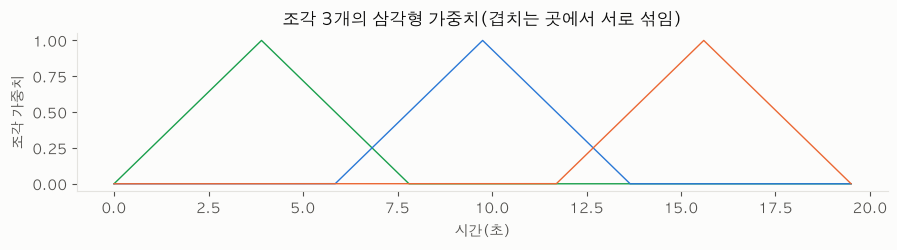

In [17]:
# ── 9절: 조각 처리 계산 ───────────────────────────────────────────────────────
# 하는 일: apply_model 소스의 핵심 줄을 보여 주고, 20초·60초 입력이 몇 조각으로 나뉘는지 같은 공식으로 계산한 뒤, 삼각형 가중치가 겹쳐 합이 1이 되는 모습을 그린다.
for l in inspect.getsource(apply.apply_model).splitlines():
    if re.search(r"segment_length|stride|offsets =|weight = |sum_weight|out /= sum_weight", l):
        print(l.rstrip()[:120])
seg_len = int(model.samplerate * float(model.segment)); stride = int((1 - 0.25) * seg_len)
for sec in (20, 60):
    length = sec * model.samplerate
    offs = list(range(0, length, stride))
    print(f"{sec}초 입력 → 조각 {len(offs)}개 (조각 {seg_len / model.samplerate:.2f}초, 이동 {stride / model.samplerate:.2f}초)")
# 삼각형 가중치 3개를 겹쳐 합이 1(정규화 후)이 되는 모양
w = np.concatenate([np.arange(1, seg_len // 2 + 1), np.arange(seg_len - seg_len // 2, 0, -1)]).astype(float); w /= w.max()
tot = stride * 2 + seg_len; acc = np.zeros(tot); fig, ax = plt.subplots(figsize=(9, 2.6))
for i in range(3):
    seg = np.zeros(tot); seg[i * stride:i * stride + seg_len] = w; acc += seg
    ax.plot(np.arange(tot) / model.samplerate, seg, lw=1, color=theme.SERIES[i])
ax.set_xlabel("시간(초)"); ax.set_ylabel("조각 가중치"); ax.set_title("조각 3개의 삼각형 가중치(겹치는 곳에서 서로 섞임)"); plt.tight_layout(); plt.show()

## 10. 분리가 실제로 되었나? 소리로 확인하고, 고정 필터와 비교

7절에서 얻은 `stems`(분리 결과)를 쓰고 정답(목소리)을 알고 있으므로 **그림 → 대역별 비율 → 숫자(SDR)** 순서로 봅니다.

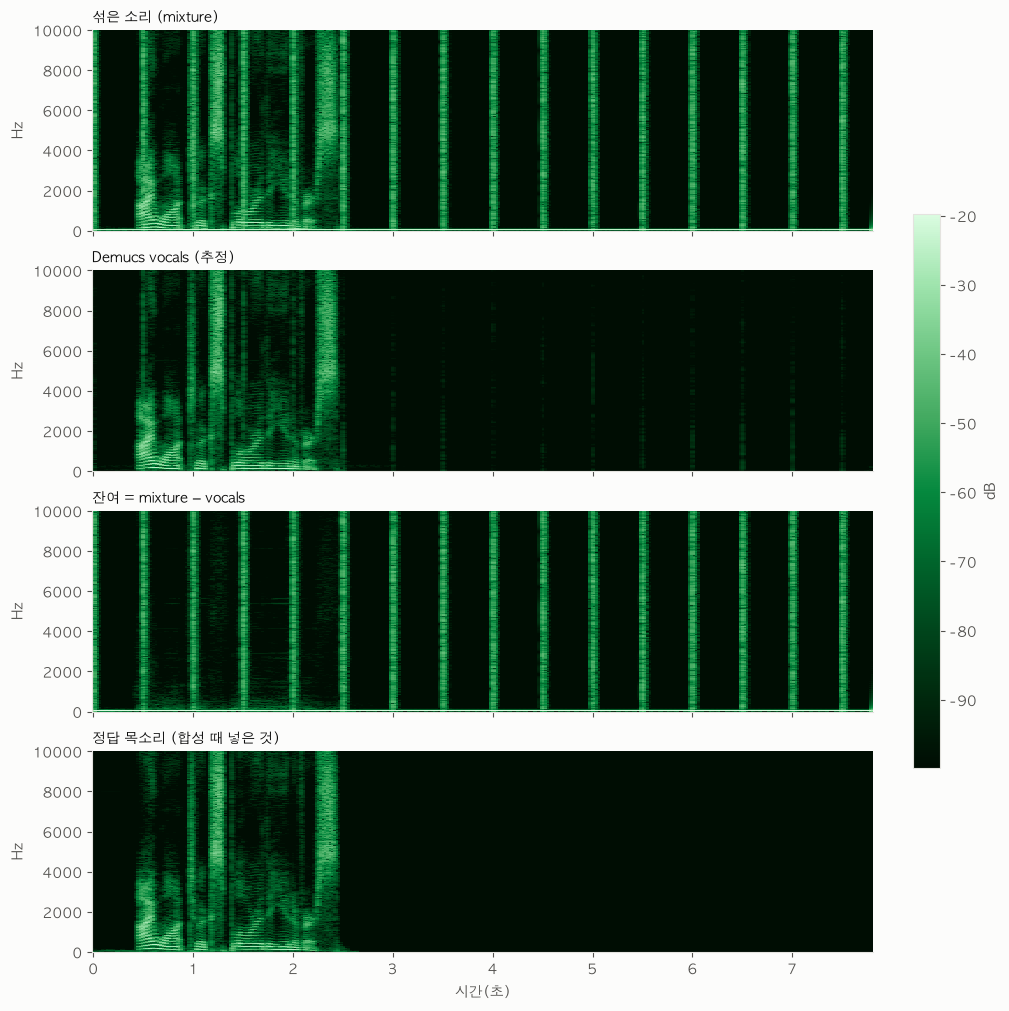

In [18]:
# ── 10절-1: 스펙트로그램 4종 비교 ─────────────────────────────────────────────
# 하는 일: 섞은 소리 / Demucs가 추정한 vocals / 잔여(mixture − vocals) / 정답 목소리의 스펙트로그램을 같은 설정(창 4096, 겹침 3072)과 같은 색 범위로 그린다.
# scipy.signal.stft: 수업 03강의 STFT를 라이브러리로 계산. 색은 프로젝트 공통 cmap(theme.CMAP_SPEC).
from scipy.signal import stft
voc = stems[0, model.sources.index("vocals")].numpy()
mono = lambda a: a.mean(0)
signals = [("섞은 소리 (mixture)", mono(mix)), ("Demucs vocals (추정)", mono(voc)),
           ("잔여 = mixture − vocals", mono(mix) - mono(voc)), ("정답 목소리 (합성 때 넣은 것)", mono(voice))]
fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True, constrained_layout=True)
vmax = None
for ax, (title, sig) in zip(axes, signals):
    f, tt, z = stft(sig, fs=SR, nperseg=4096, noverlap=3072)
    db = 20 * np.log10(np.abs(z) + 1e-7)
    vmax = db.max() if vmax is None else vmax                     # 첫 그림(믹스)의 최댓값을 기준으로 4개의 색 범위를 같게
    im = ax.pcolormesh(tt, f, db, shading="auto", cmap=theme.CMAP_SPEC, vmin=vmax - 80, vmax=vmax)
    ax.set_ylim(0, 10000); ax.set_title(title, loc="left", fontsize=10); ax.set_ylabel("Hz")
axes[-1].set_xlabel("시간(초)"); fig.colorbar(im, ax=axes, label="dB", shrink=0.6); plt.show()

### 대역별 에너지 비율

대역마다 **(그 소리의 에너지 ÷ 섞은 소리의 에너지)** 를 봅니다. 정답 목소리의 비율이 "이상적인 분리"의 기준선입니다. 단, 이것은 **기술적 관찰값**입니다: 위상과 상관관계 때문에 "원곡에서 보컬이 차지하는 실제 비율"이라고 단정할 수 없고, 정답이 없는 실제 곡에서는 정확도를 평가할 수도 없습니다.

,대역(Hz),정답 목소리/믹스,Demucs vocals/믹스
0,0-100,0.013,0.013
1,100-200,0.383,0.382
2,200-400,0.967,0.958
3,400-800,0.942,0.929
4,800-1600,0.824,0.791
5,1600-3200,0.329,0.311
6,3200-6400,0.370,0.369
7,6400-12800,0.213,0.213
8,12800-22050,0.000,0.000


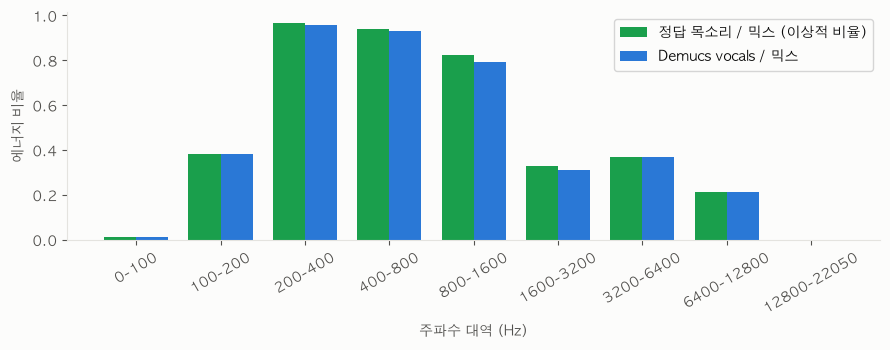

In [19]:
# ── 10절-2: 대역별 에너지 비율 (#35 ②의 작은 버전) ────────────────────────────
# 하는 일: 주파수 대역마다 (소리의 에너지 ÷ 섞은 소리의 에너지)를 표와 그림으로 보여 준다.
# visualisation.stft_power: 앱의 STFT 파워 계산(수업 3강 방식)을 그대로 재사용.
edges = [0, 100, 200, 400, 800, 1600, 3200, 6400, 12800, 22050]
def band_energy(x):
    hz, _t, p = visualisation.stft_power(x.mean(0), SR)
    return np.array([p[(hz >= lo) & (hz < hi)].sum() for lo, hi in zip(edges[:-1], edges[1:])])
e_mix, e_ref, e_voc = band_energy(mix), band_energy(voice), band_energy(voc)
labels = [f"{lo}-{hi}" for lo, hi in zip(edges[:-1], edges[1:])]
display(pd.DataFrame({"대역(Hz)": labels, "정답 목소리/믹스": (e_ref / e_mix).round(3), "Demucs vocals/믹스": (e_voc / e_mix).round(3)}))
xx = np.arange(len(labels)); wd = 0.38
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(xx - wd / 2, e_ref / e_mix, wd, label="정답 목소리 / 믹스 (이상적 비율)", color=theme.SERIES[0])
ax.bar(xx + wd / 2, e_voc / e_mix, wd, label="Demucs vocals / 믹스", color=theme.SERIES[1])
ax.set_xticks(xx); ax.set_xticklabels(labels, rotation=30); ax.set_xlabel("주파수 대역 (Hz)"); ax.set_ylabel("에너지 비율")
ax.legend(); plt.tight_layout(); plt.show()

### 숫자로 비교: SDR과 고정 대역통과 필터

"주파수 대역만으로 분리할 수 있는가?"를 확인하려고 **대역통과 필터를 대조군**으로 둡니다. **필터의 통과 대역은 결과를 보기 전에 정했습니다**(결과를 본 뒤 유리하게 바꾸지 않으려고): 200~4,000 Hz(말소리·보컬 중심 대역으로 짐작한 값 [추정])와 150~5,000 Hz(넓은 대역, 두 번째 후보) 두 가지입니다. 필터는 통과 대역 밖의 목소리 성분도 같이 지웁니다.

비교 기준 **SDR**(신호 대 왜곡비, 클수록 정답에 가까움): $\mathrm{SDR}=10\log_{10}\frac{\sum \text{정답}^2}{\sum(\text{정답}-\text{추정})^2}$ [일반 지식: 음원 분리 평가의 기본형]. **정답 stem이 있어야만 계산할 수 있습니다**(Demucs가 만든 vocals를 자기 자신의 정답으로 삼으면 성립하지 않음).

In [20]:
# ── 10절-3: SDR 비교와 잔여 검증 ──────────────────────────────────────────────
# 하는 일: 정답(voice)과 각 추정의 SDR을 계산한다. scipy.signal.butter: 버터워스 대역통과 필터(4차), sosfiltfilt: 앞뒤로 두 번 걸어 위상이 밀리지 않게.
# 또 잔여(mixture − vocals)가 나머지 3개 stem(drums+bass+other)의 합과 얼마나 같은지 본다(둘은 정확히 같을 이유가 없다: 모델의 근사).
# [수업에 없음] SDR, 버터워스 필터(수업은 FFT로 주파수를 보는 데까지)
from scipy.signal import butter, sosfiltfilt
def sdr(ref, est):
    return 10 * np.log10((ref ** 2).sum() / (((ref - est) ** 2).sum() + 1e-12))
def band(lo, hi):
    return sosfiltfilt(butter(4, [lo, hi], btype="bandpass", fs=SR, output="sos"), mix, axis=1).astype(np.float32)
res = pd.DataFrame({"방법": ["섞은 소리 그대로", "고정 대역통과 200~4000 Hz", "고정 대역통과 150~5000 Hz", "Demucs vocals"],
                    "SDR(dB)": [sdr(voice, mix), sdr(voice, band(200, 4000)), sdr(voice, band(150, 5000)), sdr(voice, voc)]}).round(2)
display(res)
rest = (stems[0, [i for i, s in enumerate(model.sources) if s != "vocals"]].sum(0)).numpy()     # drums+bass+other
resid_err = np.linalg.norm((mix - voc) - rest) / np.linalg.norm(mix - voc)
print(f"잔여(mixture−vocals)와 나머지 3개 stem 합의 상대 차이: {resid_err:.3f} (0이면 완전히 같음)")
for s_name in model.sources:
    e = stems[0, model.sources.index(s_name)].numpy()
    print(f"{s_name:7s} RMS = {np.sqrt((e ** 2).mean()):.4f}")

,방법,SDR(dB)
0,섞은 소리 그대로,-9.45
1,고정 대역통과 200~4000 Hz,2.98
2,고정 대역통과 150~5000 Hz,4.38
3,Demucs vocals,21.63


잔여(mixture−vocals)와 나머지 3개 stem 합의 상대 차이: 0.044 (0이면 완전히 같음)
drums   RMS = 0.0398
bass    RMS = 0.1418
other   RMS = 0.0038
vocals  RMS = 0.0493


### 이 합성 입력에서 나온 결과 [확인: 11-06 실행, 시드 고정, 이 입력에서만 해당]
- **SDR**: 섞은 소리 그대로 **−9.45 dB**, 고정 대역통과 200~4,000 Hz **2.98 dB**, 150~5,000 Hz **4.38 dB**, Demucs `vocals` **21.63 dB**. 단순한 주파수 필터는 통과 대역을 넓혀 봐도 개선이 작았고(두 후보 모두 5 dB 미만), 학습된 모델은 정답에 훨씬 가깝습니다. 사전에 정한 두 후보만 시험했으므로 다른 대역에서는 달라질 수 있습니다.
- **스펙트로그램 4종 (10절-1 그림)**: 섞은 소리에는 0.5초마다 **세로줄(타악기)** 과 목소리의 **배음 줄무늬**가 함께 보입니다. Demucs `vocals`에서는 세로줄이 거의 사라지고 목소리 구간(약 0.4~2.5초)만 남으며, 잔여에는 반대로 세로줄만 남습니다. 정답 목소리와 `vocals`의 모양이 거의 같습니다 [확인: 그림].
- **대역별 에너지 비율**: 정답 목소리의 비율(초록)은 200~1,600 Hz에서 0.8~1에 가깝고, 1,600~12,800 Hz에서는 0.2~0.35로 **0과 1 사이**입니다. 이유는 합성 타악기(잡음)가 넓은 대역에 걸쳐 있어서 **목소리와 같은 대역을 공유**하기 때문입니다. 그런데도 Demucs의 막대(파랑)가 정답 막대와 거의 겹칩니다. → "음역대가 달라서 분리된다"만으로는 설명이 안 되고, 같은 대역을 공유해도 분리된다는 증거입니다(**이 합성 입력에서만**; 실제 곡에서는 #35의 ①~③으로 확인해야 함 [미확인]).
- **잔여 검증**: 잔여(mixture − vocals)와 나머지 3개 stem(drums+bass+other)의 합은 **상대 차이 0.044**(약 4%)로 거의 같지만 **정확히 같지는 않습니다.** 각 stem이 모델의 독립된 추정이라 합이 믹스와 정확히 일치할 이유가 없기 때문입니다 [추정].
- **주의**: 입력이 말소리 + 합성 반주라 실제 노래의 성능으로 일반화하지 않습니다. SDR이 높게 나온 것은 쉬운 입력이기 때문일 수 있습니다 [추정].

In [21]:
# ── 10절-4 (새): SDR 21.63 dB를 어디까지 믿나 — 무음 구간 영향 확인 ──────────────────────────────
# 하는 일: 정답 목소리가 실제로 있는 구간만으로 SDR을 다시 계산하고, 목소리가 **없어야 하는** 구간에 Demucs가 남긴 소리(누설)의 양을 센다.
# 필요: 6절(voice, mix), 10절-3(sdr, voc)을 먼저 실행. SDR 식: 10·log10( Σ정답² / Σ(정답−추정)² ).
need = [v for v in ("voice", "voc", "sdr", "mix") if v not in globals()]
if need:
    raise RuntimeError(f"먼저 실행할 셀: 6절, 10절-1·10절-3. 지금 없는 변수: {need}")
active = np.nonzero(np.abs(voice[0]) > 1e-6)[0]
n_v = int(active.max()) + 1                                       # 정답 목소리가 있는 마지막 표본(TTS가 3초보다 짧으면 그만큼)
SRm = model.samplerate
print(f"정답 목소리가 있는 구간: 0 ~ {n_v / SRm:.2f}초 (전체 {mix.shape[1] / SRm:.1f}초 중 {n_v / mix.shape[1] * 100:.0f}%)")
print(f"SDR 전체 구간(위 10절-3): {sdr(voice, voc):.2f} dB")
print(f"SDR 목소리 구간만      : {sdr(voice[:, :n_v], voc[:, :n_v]):.2f} dB")
leak = (voc[:, n_v:] ** 2).sum() / (voc ** 2).sum()
print(f"목소리가 없어야 하는 구간({(mix.shape[1] - n_v) / SRm:.1f}초)에 남은 vocals 에너지: 전체 vocals의 {leak * 100:.2f}%  (정답은 이 구간이 완전한 무음)")
mix_leak = (np.abs(voc[:, n_v:]).mean() / (np.abs(mix[:, n_v:]).mean() + 1e-12))
print(f"그 구간의 평균 진폭: 섞은 소리 대비 vocals가 {mix_leak * 100:.1f}%  → 반주는 거의 지워졌다")

정답 목소리가 있는 구간: 0 ~ 2.65초 (전체 7.8초 중 34%)
SDR 전체 구간(위 10절-3): 21.63 dB
SDR 목소리 구간만      : 21.64 dB
목소리가 없어야 하는 구간(5.2초)에 남은 vocals 에너지: 전체 vocals의 0.00%  (정답은 이 구간이 완전한 무음)
그 구간의 평균 진폭: 섞은 소리 대비 vocals가 0.1%  → 반주는 거의 지워졌다


### 10-4절 읽는 법 — 21.63 dB를 **어디까지** 믿나

**[확인: 11-09 실행, 위 출력]** 정답 목소리가 있는 구간은 **0~2.65초**(전체 7.8초의 34%; 6절 주석은 "3초"라고 적었지만 TTS 소리가 그보다 짧습니다). SDR은 **전체 구간 21.63 dB, 목소리 구간만 21.64 dB**로 거의 같고, 목소리가 없어야 하는 나머지 5.2초에 남은 vocals 에너지는 **전체의 0.00%** 입니다. 즉 이 입력에서는 무음 구간이 SDR을 부풀리지도, 누설로 깎지도 않았습니다.

- SDR 식의 **분자는 정답 에너지**, 분모는 **정답과 추정의 차이 에너지**입니다. 정답이 무음인 구간에서는 분자에 보태는 것이 없고, 추정이 거기에 소리를 남기면 **분모(오차)만 커집니다.** 즉 이 합성 입력에서 "무음 구간이 있어서 SDR이 부풀려졌다"가 아니라, **누설이 있으면 오히려 깎입니다**(위 두 SDR을 비교). 그래서 무음 구간의 영향은 **한쪽 방향으로 점수를 올려 주지 않습니다** [확인: 식과 위 숫자].
- 그래도 **이 숫자를 실제 노래의 성능으로 읽으면 안 됩니다.** 입력이 ① **말소리**(Demucs는 노래 보컬로 학습) ② **합성 반주**(저음 사인파 + 잡음 타격: 실제 악기보다 단순) ③ 정답 목소리 **3초 미만**이기 때문입니다. 쉬운 입력이라 높게 나온 것일 수 있습니다 [추정].
- 이 실험이 **분명히 보여 주는 것**은 하나입니다: **통과 대역만 고르는 고정 필터(2.98·4.38 dB)** 로는 같은 입력에서 한계가 있고, **학습된 모델(21.63 dB)** 은 같은 대역에 섞인 소리도 구분해 냈다는 점입니다. "음역대가 달라서 분리된다"가 아니라 "학습으로 얻은 패턴으로 구분한다"는 해석과 맞습니다 [확인: 이 입력에서만].

## 11. 평가: 무엇으로 재야 하나 (WER과 분리 품질은 다릅니다)

| 평가 관점 | 방법 | 답하는 질문 | 이 노트북에서 |
|---|---|---|---|
| SongLingo의 목적 | WER / CER | 분리 후 STT가 정답 가사에 가까워졌나? | 아직 안 함(실제 곡 구간 필요, 15.4절 기록: 전체로는 악화) |
| 분리 자체 | SDR / SI-SDR | 추정 stem이 기준 stem에 얼마나 가까운가? | **합성 입력에서만** 계산(10절) |
| 처리 비용 | 지연 시간 / 실시간 대비 배수 | 실제 사용에 필요한 시간은? | 아래 셀 |
| 청취 | 주관 평가 | 반주 잔류·보컬 손실·인공음이 들리는가? | 사람이 직접 |

SDR/SI-SDR에는 **정답 vocals stem**이 필요하므로 정답이 없는 상업곡에는 쓸 수 없고, 그래서 우리 프로젝트는 청취와 STT의 WER/CER로 대신 비교합니다.

In [22]:
# ── 11절: 처리 시간 ───────────────────────────────────────────────────────────
# 하는 일: 7절에서 잰 시간을 오디오 길이로 나눠 "실시간 대비 배수"를 구하고 15.4절의 기록과 나란히 놓는다. 이 값은 이 PC(CPU)·이 입력의 값이다.
audio_sec = N / SR
print(f"이번 실행: 오디오 {audio_sec:.1f}초를 {elapsed:.0f}초에 처리 → 실시간의 약 {elapsed / audio_sec:.1f}배")
print("15.4절 기록: 20초 구간을 약 65초에 처리 → 약 3.2배 (CPU 스레드 2개, 프로세스 시작·모델 읽기 포함 여부는 [미확인])")

이번 실행: 오디오 7.8초를 212초에 처리 → 실시간의 약 27.2배
15.4절 기록: 20초 구간을 약 65초에 처리 → 약 3.2배 (CPU 스레드 2개, 프로세스 시작·모델 읽기 포함 여부는 [미확인])


## 11-2. 학습(Training)과 추론(Inference)은 다릅니다 — 이 노트북이 지금까지 한 것은 **추론**

| | 추론 (이 노트북이 한 것) | 학습 (모델의 숫자가 정해진 과정) |
|---|---|---|
| 입력 | 섞인 소리 하나 | 섞인 소리 + **정답 stem 4개**(보컬·드럼·베이스·기타) |
| 가중치 | **고정**(바꾸지 않음) | **조금씩 고침** |
| 하는 일 | 입력 → 모델 → 4개 소리 출력 | 입력 → 모델 → 4개 소리 출력 → **정답과 비교(손실)** → 손실이 줄어드는 방향으로 가중치 수정 |
| PyTorch 코드 | `model.eval()`, `torch.no_grad()` | 손실 계산 → `loss.backward()` → `optimizer.step()` |
| 사람이 정하는 것 | — | 모델 구조·손실 함수·데이터. **"이것이 사람 목소리"라는 규칙은 사람이 쓰지 않는다.** |

모델의 4,198만 개 숫자는 학습으로 정해졌고, 수업 6강(Keras `fit`)의 **손실 → 역전파 → 가중치 갱신**과 같은 구조입니다. 이 절에서는 ① 설치된 Demucs의 **실제 학습 코드**를 읽고(확인), ② 같은 방식의 **아주 작은 모델**을 직접 학습해 숫자로 봅니다(장난감).

In [23]:
# ── 11-2절-1 (새): 설치된 Demucs의 학습 코드 읽기 (실행하지 않고 읽기만) ──────────────────────────
# 하는 일: 설치된 demucs 패키지의 solver.py(학습 한 스텝을 하는 파일)에서 "믹스를 만들고 → 모델에 넣고 → 손실 → 역전파 → 갱신" 줄을 그대로 보여 준다.
# 주의: solver.py는 import하지 않는다(학습용 의존 패키지 dora가 없어 import가 실패한다). 파일을 글로 읽기만 한다.
# [수업에 없음] 학습 코드 구조  [수업과 같음] 손실 → backward → optimizer.step (6강 Keras fit이 안에서 하는 일)
import demucs
from pathlib import Path
solver_path = Path(demucs.__file__).parent / "solver.py"
lines = solver_path.read_text(encoding="utf-8").splitlines()
want = {"믹스 만들기(정답 stem을 더함)": "mix = sources.sum(dim=1)", "모델 통과": "estimate = self.dmodel(mix)",
        "손실(L1: 출력과 정답의 차이의 평균)": "loss = F.l1_loss(estimate, sources, reduction='none')", "소리 종류별 가중 평균": "loss = (loss * weights).sum() / weights.sum()",
        "기울기 계산(역전파)": "loss.backward()", "가중치 갱신": "self.optimizer.step()", "다음 스텝을 위해 기울기 지우기": "self.optimizer.zero_grad()",
        "데이터 증강(새 믹스 만들기)": "sources = self.augment(sources)"}
print(f"파일: .../demucs/{solver_path.name}\n")
for title, key in want.items():
    n = next(i for i, l in enumerate(lines) if key in l)
    print(f"{n + 1:>4}줄  {lines[n].strip():<62} ← {title}")
from demucs import augment
print("\nRemix(학습 때 쓰는 증강)의 설명:", augment.Remix.__doc__.strip().splitlines()[0])

파일: .../demucs/solver.py

 310줄  mix = sources.sum(dim=1)                                       ← 믹스 만들기(정답 stem을 더함)
 318줄  estimate = self.dmodel(mix)                                    ← 모델 통과
 325줄  loss = F.l1_loss(estimate, sources, reduction='none')          ← 손실(L1: 출력과 정답의 차이의 평균)
 336줄  loss = (loss * weights).sum() / weights.sum()                  ← 소리 종류별 가중 평균
 370줄  loss.backward()                                                ← 기울기 계산(역전파)
 385줄  self.optimizer.step()                                          ← 가중치 갱신
 386줄  self.optimizer.zero_grad()                                     ← 다음 스텝을 위해 기울기 지우기
 309줄  sources = self.augment(sources)                                ← 데이터 증강(새 믹스 만들기)

Remix(학습 때 쓰는 증강)의 설명: Shuffle sources to make new mixes.


### 읽는 법 [확인: 위 출력 = 설치된 소스의 줄]

학습 한 스텝은 이렇게 움직입니다.
1. 데이터에는 **정답 stem 4개**가 있습니다(`sources`). 이것을 **더해서 믹스**를 만듭니다(`mix = sources.sum(dim=1)`). → "정답을 아는 믹스"가 공짜로 생깁니다. 이 노트북의 6절(정답 목소리 + 합성 반주)이 **같은 발상**입니다.
2. 믹스를 모델에 넣어 `estimate`(추정 4개)를 얻습니다.
3. **손실** = 추정과 정답의 차이의 평균(`l1_loss`). 추정이 정답에 가까울수록 작습니다.
4. `loss.backward()`가 "각 가중치를 어느 쪽으로 얼마나 고치면 손실이 줄어드는가"(기울기)를 구하고, `optimizer.step()`이 **4,198만 개의 가중치를 조금씩 고칩니다.**
5. 이것을 **많은 곡의 조각**에 반복합니다. `Remix`는 서로 다른 곡의 stem을 **섞어 새 믹스**를 만들어 같은 곡이 아니어도 다양한 조합을 보게 합니다 — 어떤 한 곡을 외우는 것이 아니라 "보컬 소리의 일반적인 특징"을 배우게 하려는 장치입니다 [추정: 코드의 목적 해석].

**학습 설정은 논문에서 확인했습니다 [확인: 논문 PDF `2211.08553v1.pdf`(Hybrid Transformers for Music Source Separation) 5.1절]**
- 손실은 **파형에 대한 L1 손실**(위 `l1_loss`와 같음), 최적화는 **Adam**, 학습률 3·10⁻⁴, **배치 크기 32**.
- **1,200 에포크 × 800 배치**, 데이터는 **MUSDB18-HQ**(150곡 중 학습용 87곡)에 **직접 거른 800곡**을 더한 것, 44.1 kHz 스테레오. **NVIDIA V100 GPU 8장**.
- 데이터 증강으로 **스템을 섞어 새 믹스를 만드는 리믹스**와 음높이·속도 바꾸기를 씁니다(위 `Remix`와 같은 발상 [확인: 논문 + 설치된 소스]). **리믹스를 끄면 SDR이 8.70 → 8.00(−0.7 dB)** 로 떨어져 가장 중요한 증강입니다(논문 Table 3). 블로그(velog)는 v1에서 "L1과 L2 손실 사이에 큰 차이가 없었다"고 적습니다 [블로그].
- **Transformer는 데이터를 많이 먹습니다.** 논문 Table 1: 추가 데이터가 없으면 HT Demucs(7.52 dB)가 Hybrid Demucs(7.64)보다 **오히려 낮고**, **800곡을 더하면** HT 8.80 대 Hybrid 8.34로 약 **+0.46 dB**(초록의 "0.45 dB")입니다. 즉 **4,198만 개 숫자 중 75%가 있는 Attention은 데이터가 충분해야 제 몫을 한다**는 것입니다. 800곡은 이전 모델로 stem의 "새어 나옴"이 적은 곡만 골라 만든 것입니다(논문 4절).
- 논문의 연구 질문은 "**긴 문맥**을 Transformer로 활용하면 도움이 되는가"입니다: 이전 Demucs는 최대 **약 10초**의 앞뒤 문맥을 쓸 수 있고, 문맥이 길면 모호한 부분을 풀 수 있다고 설명합니다(논문 서론). 이 노트북의 모델이 한 번에 보는 길이는 **7.8초**(`model.segment`)입니다.

**아직 확인하지 못한 것 [미확인]**: 앱이 쓰는 `htdemucs` **가중치 파일이 정확히 위 설정으로 학습된 것인지**(**구성**은 논문 Table 2의 한 행 — 7.8초·깊이 5·차원 512 — 과 같아 보이지만, 가중치의 학습 세부는 저장소 README로 확인 필요. 큰 그림 2의 ②), 학습 중 손실이 어떻게 변했는지(곡선은 논문에 없음). 설치된 패키지에는 설정 파일(`conf`)이 없어 이 환경에서는 설정값을 읽을 수 없고, 위 값은 **논문에 적힌 값**입니다.

### 장난감으로 직접 학습해 보기 — "규칙을 쓰지 않아도 데이터에서 규칙이 나온다"

Demucs를 학습할 수는 없으니, **같은 방식(믹스 입력 → 출력과 정답의 L1 차이를 줄이도록 가중치 수정)** 으로 **아주 작은 모델**을 학습해 봅니다. **이것은 Demucs가 아닙니다.** 학습이 무엇인지를 숫자로 보는 장난감입니다.

- **데이터(합성)**: 정답 `목소리` = 기본 주파수 180~360 Hz의 배음 8개(진폭이 천천히 변함) / `반주` = 저음 사인파 + 0.25초마다 터지는 잡음. 믹스 = 목소리 + 반주. 학습 60개, **시험 12개(학습에 안 쓴 것)**, 각 2초, 표본화 16 kHz.
- **모델 A (가중치 513개)**: 주파수 칸마다 하나씩 "이 칸을 얼마나 통과시킬까(0~1)"를 배운다(고정 필터와 같은 종류). **모델 B (약 13만 개)**: 작은 신경망이 **한 프레임의 스펙트럼 모양을 보고** 칸별 통과 정도를 정한다(문맥을 본다).
- 둘 다 믹스의 STFT 크기에 마스크를 곱해 목소리의 STFT 크기에 가까워지도록(L1) 학습한다. 비교 대조군은 **미리 정한 고정 대역통과 필터(150~5,000 Hz)** 와 섞은 소리 그대로.
- 실험 원칙: 모델 B는 **초기값(시드)을 바꿔 3번** 학습해 평균·범위를 봅니다.

학습 예제 60개, STFT 크기 (60, 513, 126) = (예제, 주파수 칸 513, 시간 칸)
모델 A: 가중치 513개 | 손실 0.775 → 0.202(100스텝) → 0.171(300스텝)
모델 B: 가중치 131,969개 | 시드별 손실 [0.753, 0.821, 0.793] → [0.1, 0.086, 0.094]


,방법,SDR 평균(dB),최소,최대
0,섞은 소리 그대로,-0.83,-1.23,-0.45
1,고정 필터 150~5000 Hz,9.24,7.49,10.25
2,모델 A (정적 마스크),12.30,11.58,12.96
3,모델 B (시드 0),13.76,13.04,14.23
4,모델 B (시드 1),13.98,13.32,14.51
5,모델 B (시드 2),13.97,13.17,14.50


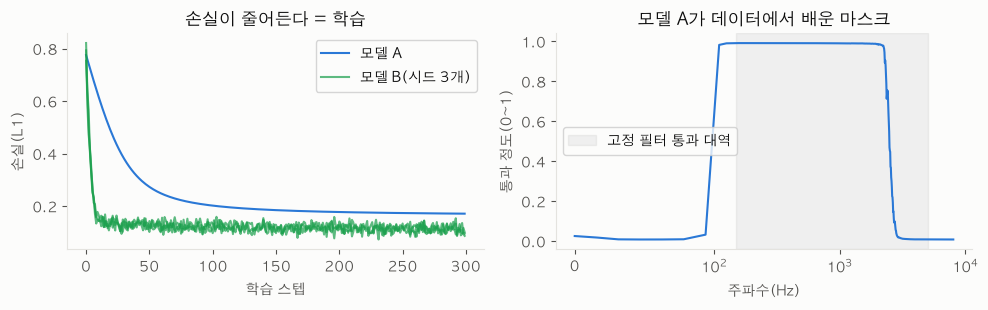

  모델 A 통과 정도 평균    0~100  Hz: 0.02
  모델 A 통과 정도 평균  100~1000 Hz: 0.99
  모델 A 통과 정도 평균 1000~3000 Hz: 0.75
  모델 A 통과 정도 평균 3000~8000 Hz: 0.01


In [24]:
# ── 11-2절-2 (새): 장난감 학습 — 마스크 모델 A(정적)·B(작은 신경망) 학습과 시험 ──────────────────────────
# 하는 일: 합성 (목소리 + 반주) 60개로 학습하고, 학습에 쓰지 않은 12개에서 SDR을 잰다. 손실이 줄어드는 모습과 배운 마스크의 모양을 본다.
# 실행 시간: CPU에서 약 1~2분. [수업과 같음] 손실 → 역전파 → 갱신(6강)  [수업에 없음] STFT 크기 마스크, Adam, torch.stft/istft
import numpy as np, torch
torch.set_num_threads(2)
SRt, DURt, NF, HOP = 16000, 2.0, 1024, 256
NT = int(SRt * DURt); win = torch.hann_window(NF)

def make_example(rng):
    t = np.arange(NT) / SRt
    f0 = rng.uniform(180, 360); env = 0.6 + 0.4 * np.sin(2 * np.pi * rng.uniform(1, 3) * t + rng.uniform(0, 6.28))
    vib = 1 + 0.01 * np.sin(2 * np.pi * 5 * t)
    voice_ = sum((1 / h) * np.sin(2 * np.pi * f0 * h * vib * t) for h in range(1, 9)) * env * 0.3
    drum_ = np.zeros(NT)
    for k in range(0, NT, SRt // 4):
        L = min(int(0.05 * SRt), NT - k); drum_[k:k + L] += rng.standard_normal(L) * np.exp(-np.arange(L) / (0.01 * SRt)) * 0.5
    bass_ = 0.25 * np.sin(2 * np.pi * rng.uniform(45, 70) * t)
    return voice_.astype(np.float32), (drum_ + bass_).astype(np.float32)

stft_ = lambda x: torch.stft(torch.from_numpy(x), NF, HOP, window=win, return_complex=True)
sdr_ = lambda ref, est: 10 * np.log10((ref ** 2).sum() / (((ref - est) ** 2).sum() + 1e-12))
rng0 = np.random.default_rng(0)
train_set = [make_example(rng0) for _ in range(60)]
test_set = [make_example(np.random.default_rng(100 + i)) for i in range(12)]     # 학습에 쓰지 않는 시험용
Xtr = torch.stack([stft_(v + a).abs() for v, a in train_set]); Ytr = torch.stack([stft_(v).abs() for v, a in train_set])   # (예제, 주파수, 시간)
n_bins = Xtr.shape[1]
print(f"학습 예제 {len(train_set)}개, STFT 크기 {tuple(Xtr.shape)} = (예제, 주파수 칸 {n_bins}, 시간 칸)")

# ── 모델 A: 주파수 칸마다 통과 정도 하나(가중치 n_bins개) ──
torch.manual_seed(0)
a_param = torch.zeros(n_bins, requires_grad=True)
opt = torch.optim.Adam([a_param], lr=0.05)
loss_log_A = []
for step in range(300):
    mask = torch.sigmoid(a_param)[None, :, None]
    loss = (mask * Xtr - Ytr).abs().mean()                         # L1: 출력(마스크×믹스)과 정답(목소리)의 차이
    opt.zero_grad(); loss.backward(); opt.step()                    # 역전파 → 가중치 갱신
    loss_log_A.append(float(loss))
print(f"모델 A: 가중치 {n_bins}개 | 손실 {loss_log_A[0]:.3f} → {loss_log_A[99]:.3f}(100스텝) → {loss_log_A[-1]:.3f}(300스텝)")

# ── 모델 B: 한 프레임의 스펙트럼을 보고 마스크를 정하는 작은 신경망, 시드 3개 ──
Xf = Xtr.permute(0, 2, 1).reshape(-1, n_bins); Yf = Ytr.permute(0, 2, 1).reshape(-1, n_bins); scale_ = Xf.mean()
nets, loss_logs_B = [], []
for seed in (0, 1, 2):
    torch.manual_seed(seed)
    net = torch.nn.Sequential(torch.nn.Linear(n_bins, 128), torch.nn.ReLU(), torch.nn.Linear(128, n_bins), torch.nn.Sigmoid())
    opt = torch.optim.Adam(net.parameters(), lr=2e-3); log = []
    for step in range(300):
        idx = torch.randint(0, Xf.shape[0], (256,))
        m = net(Xf[idx] / scale_); loss = (m * Xf[idx] - Yf[idx]).abs().mean()
        opt.zero_grad(); loss.backward(); opt.step(); log.append(float(loss))
    nets.append(net); loss_logs_B.append(log)
print(f"모델 B: 가중치 {sum(p.numel() for p in nets[0].parameters()):,}개 | 시드별 손실 {[round(l[0], 3) for l in loss_logs_B]} → {[round(l[-1], 3) for l in loss_logs_B]}")

# ── 시험: 학습에 쓰지 않은 12개에서 SDR(믹스의 위상을 그대로 쓰고 크기만 마스크로 바꿔 파형으로 되돌림) ──
from scipy.signal import butter, sosfiltfilt
def restore(v, a, mask_fn):
    Z = stft_(v + a); mag_ = Z.abs()
    out = torch.istft(mask_fn(mag_) * mag_ * torch.exp(1j * torch.angle(Z)), NF, HOP, window=win, length=NT)
    return out.numpy()
sos_ = butter(4, [150, 5000], btype="bandpass", fs=SRt, output="sos")
scores = {"섞은 소리 그대로": [], "고정 필터 150~5000 Hz": [], "모델 A (정적 마스크)": []}
for k in range(3): scores[f"모델 B (시드 {k})"] = []
for v, a in test_set:
    scores["섞은 소리 그대로"].append(sdr_(v, v + a))
    scores["고정 필터 150~5000 Hz"].append(sdr_(v, sosfiltfilt(sos_, v + a)))
    scores["모델 A (정적 마스크)"].append(sdr_(v, restore(v, a, lambda m_: torch.sigmoid(a_param).detach()[:, None])))
    for k, net in enumerate(nets):
        with torch.no_grad():
            scores[f"모델 B (시드 {k})"].append(sdr_(v, restore(v, a, lambda m_, net=net: net(m_.T / scale_).T)))
table_ = pd.DataFrame([{"방법": k, "SDR 평균(dB)": round(np.mean(v_), 2), "최소": round(min(v_), 2), "최대": round(max(v_), 2)} for k, v_ in scores.items()])
display(table_)

# ── 그림: 손실 곡선과 모델 A가 배운 마스크(주파수별 통과 정도) ──
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(loss_log_A, label="모델 A", color=theme.SERIES[1])
for k, l_ in enumerate(loss_logs_B): ax[0].plot(l_, color=theme.SERIES[0], alpha=0.7, label="모델 B(시드 3개)" if k == 0 else None)
ax[0].set_xlabel("학습 스텝"); ax[0].set_ylabel("손실(L1)"); ax[0].set_title("손실이 줄어든다 = 학습"); ax[0].legend()
hz_ = np.arange(n_bins) * SRt / NF
ax[1].plot(hz_, torch.sigmoid(a_param).detach().numpy(), color=theme.SERIES[1]); ax[1].set_xscale("symlog", linthresh=100)
ax[1].axvspan(150, 5000, color="#999999", alpha=0.12, label="고정 필터 통과 대역")
ax[1].set_xlabel("주파수(Hz)"); ax[1].set_ylabel("통과 정도(0~1)"); ax[1].set_title("모델 A가 데이터에서 배운 마스크"); ax[1].legend()
plt.tight_layout(); plt.show()
for lo, hi in [(0, 100), (100, 1000), (1000, 3000), (3000, 8000)]:
    sel = (hz_ >= lo) & (hz_ < hi); print(f"  모델 A 통과 정도 평균 {lo:>4}~{hi:<4} Hz: {torch.sigmoid(a_param).detach().numpy()[sel].mean():.2f}")

### 장난감 학습이 보여 주는 것 [확인: 11-09 내 실행, 위 출력과 대조 / 합성 데이터에서만]

- **손실이 줄어든다 = 학습한다.** 모델 A는 0.775 → 0.171, 모델 B는 시드 3개 모두 0.75~0.82 → **0.09~0.10**으로 줄었습니다(300스텝). 아무도 "100~1,000 Hz는 통과시켜라"고 쓰지 않았는데, 모델 A의 마스크는 **저음(0~100 Hz, 저음 사인파: 통과 정도 0.02)과 높은 주파수(3~8 kHz, 잡음: 0.01)를 거의 막고 100~1,000 Hz(0.99)는 통과시키는 모양**을 데이터에서 스스로 만들었습니다(1~3 kHz는 0.75). 이것이 "**학습으로 규칙이 생긴다**"의 가장 작은 예입니다.
- **정적 마스크는 "고정 필터와 같은 종류"** 입니다. 그래도 사람이 정한 필터(150~5,000 Hz, 시험 평균 **9.24 dB**)보다 모델 A의 시험 SDR(**12.30 dB**)이 높게 나온 것은 **데이터에 맞게 통과 대역을 고쳤기 때문**입니다(합성 데이터라서 가능한 일이며, 실제 노래에서도 그렇다는 뜻이 아닙니다).
- **모델 B**가 A보다 높게 나온 것은 **한 프레임의 스펙트럼 모양(배음 줄무늬 대 평평한 잡음)을 보고** 칸마다 다르게 정하기 때문입니다 — 즉 **문맥을 보는 모델이 고정된 마스크보다 낫다.** 모델 B는 시드 3개가 **13.76 / 13.98 / 13.97 dB**(섞은 소리 그대로는 −0.83 dB)로 서로 비슷했습니다(시험 12개의 최소~최대는 표 참고).
- **이 장난감과 Demucs의 관계**: 방식(믹스 입력 → 정답과의 L1 차이를 줄이도록 숫자 수정)은 **같고**, 규모와 능력이 다릅니다. Demucs는 가중치 **4,198만 개**, 주파수만이 아니라 **시간 구조**(파형 가지)와 **먼 거리 관계**(Attention)까지 보며, **실제 음악**(여러 악기·화음·잔향)에서 학습합니다.
- **한계**: 합성 데이터는 쉽습니다(배음 몇 개 + 잡음). 시험 12개도 모두 같은 방식으로 만든 소리입니다. **이 SDR 값을 Demucs의 성능과 비교하지 않습니다.**

## 11-3. 처음엔 무작위인 숫자가 어떻게 "특징"이 되나 — 시행착오가 아니라 기울기를 따라 고치는 일 (11-10, 내 질문 18)

**내 이해**: "랜덤 파라미터에서 시작해서 시행착오를 거치며 손실을 줄이면 패턴이 나타난다." → **방향은 맞고, "무작위 시행착오"만 바로잡으면 됩니다.** 파라미터를 **무작위로 바꿔 보는 것이 아니라**, 역전파가 **"각 숫자를 조금 바꾸면 손실이 어느 쪽으로 얼마나 변하는가"(기울기)** 를 알려 주고 그 **반대 방향으로 조금** 고칩니다 [일반 지식, 11-2절의 학습 코드와 같은 구조].

```text
① 초기화      가중치를 작은 무작위 값으로 시작 (이 값에는 아직 "보컬"이라는 의미가 없다)
② 순전파      섞인 소리를 넣어 4개 소리를 예측
③ 손실 계산   예측과 정답 stem의 차이(L1)
④ 역전파      각 가중치가 손실에 준 영향 ∂L/∂w 계산
⑤ 갱신        w ← w − η·∂L/∂w   (η = 학습률)
⑥ 새 데이터로 ②~⑤ 반복  (미니배치마다 손실이 잠깐 오를 수도 있지만 평균적으로 줄어듦)
```

In [ ]:
# ── 11-3절 (새, 11-10): 가중치 하나가 손실을 줄이는 방향으로 고쳐지는 모습 — 손으로 따라가는 숫자 ─────────────────
# 하는 일: 예측 = w·x, 손실 L = (w·x − 정답)², 기울기 dL/dw = 2(w·x − 정답)·x 로 w를 `w ← w − η·기울기` 5번 고친다.
# 11-2절 장난감 학습과 같은 구조를 숫자 1개로 줄인 것이다(수업 6강의 fit과 같음).
w, x, target, lr = 0.5, 2.0, 3.0, 0.1                           # 처음엔 아무 값이나(여기서는 0.5)
for step in range(6):
    pred = w * x
    loss = (pred - target) ** 2
    grad = 2 * (pred - target) * x                               # 손실을 w로 미분한 값: w를 키우면 손실이 어떻게 변하나
    print(f"step {step}: w={w:.4f}  예측={pred:.4f}  손실={loss:.4f}  기울기={grad:+.3f}")
    w = w - lr * grad                                            # 기울기의 반대 방향으로 조금(학습률 η=0.1) 이동

step 0: w=0.5000  예측=1.0000  손실=4.0000  기울기=-8.000
step 1: w=1.3000  예측=2.6000  손실=0.1600  기울기=-1.600
step 2: w=1.4600  예측=2.9200  손실=0.0064  기울기=-0.320
step 3: w=1.4920  예측=2.9840  손실=0.0003  기울기=-0.064
step 4: w=1.4984  예측=2.9968  손실=0.0000  기울기=-0.013
step 5: w=1.4997  예측=2.9994  손실=0.0000  기울기=-0.003

#### 위 출력 읽는 법 [확인: 11-10 내 실행(헤드리스), 손으로 따라갈 수 있는 숫자 1개짜리]
- step 0: `w=0.5` → 예측 1.0, 정답 3.0이라 손실 4.0, 기울기 −8(w를 **키우면** 손실이 줄어든다는 뜻). `w ← 0.5 − 0.1×(−8) = 1.3` → 손실이 **4.0 → 0.16**으로 급감. 이후 기울기가 줄어드니 **고치는 폭도 자동으로 줄어** 정답(w=1.5)에 수렴합니다.
- Demucs는 이것이 **4,198만 개의 숫자에 동시에, 곡 단위로 수없이** 일어나는 것입니다. 11-2절의 장난감 모델이 같은 일을 작은 신경망으로 한 것입니다.

**학습이 끝난 뒤의 채널**: 각 필터는 주기적 진동·급격한 진폭 변화·배음 구조 같은 **유용한 패턴에 반응하게** 되지만, **한 채널이 한 특징만 맡는 것은 아니고** 여러 채널·층의 결과가 함께 쓰입니다(**분산 표현**, 8-7절) [일반 지식; 역전파 논문 등 출처는 ChatGPT가 인용했고 직접 확인하지 않음 — 미확인]. 그래서 "이 채널은 보컬을 인식한다"고 **사전에 지정하지 않아도** 목표(손실)에 유용한 내부 표현이 생깁니다.

**"이런 학습은 21세기에 가능해진 것인가?"** → 절반은 맞고 보정이 필요합니다 [일반 지식]. 역전파(1980년대)와 CNN(1990년대)의 아이디어는 훨씬 이전부터 있었고, 큰 모델이 실제로 학습되기 시작한 것은 **데이터 · 연산(GPU·병렬) · 알고리즘(구조·최적화 기법)** 세 가지가 함께 갖춰졌기 때문입니다(2012년 AlexNet이 자주 전환점으로 언급됨). 또 **언제나 방대한 데이터가 필요한 것은 아닙니다**(데이터 증강 등으로 적은 정답 데이터에서도 성능을 낸 예가 있다고 ChatGPT가 전함 [미확인]). Demucs에서도 비슷한 일이 보입니다: 이 폴더의 논문(HT Demucs)이 **MUSDB만으로 학습하면 HT(7.52 dB)가 Hybrid(7.64 dB)보다 낮고, 선별한 800곡을 더하면 Hybrid보다 0.45 dB 높다**고 적었습니다 [확인: 11-10, 논문 PDF `2211.08553v1.pdf`의 결과 표와 초록] — **구조가 복잡할수록 데이터가 더 필요**할 수 있다는 예입니다(큰 그림 2).

---
## 11-4. 역전파에는 항상 "정답"이 필요한가? — 지도·자기지도·비지도·강화 (11-10, 내 질문 19) [일반 지식]

**구분할 두 가지**: ① 학습에 **사람이 준 정답**이 필요한가? ② 학습 목표를 **손실(미분 가능한 목적 함수)** 로 만들어 기울기를 구할 수 있는가? **역전파는 ②와 관련된 방법이고, 정답 레이블이 필수인 것은 아닙니다.** 필요한 것은 "정답"이 아니라 **줄여야 할 손실**입니다.

| 학습 방식 | 정답 | 학습 신호 | 예 |
|---|---|---|---|
| **지도학습** | 사람이 준 레이블 | 예측과 정답의 차이 | **Demucs**: 섞인 소리 입력, 정답 stem 4개와 비교 |
| **자기지도학습** | 외부 정답 없음 — 데이터에서 **자동으로** 만든 목표 | 가린 부분·다음 부분을 맞히기 | 다음 단어 예측(GPT 계열), 마스크 단어 맞히기(BERT) |
| **비지도학습** | 명시적 정답 없음 | 데이터 자체의 구조·목적 함수 | 군집화(K-means는 **신경망이 아니라 역전파를 쓰지 않음**), Autoencoder(입력을 복원 — **역전파 사용**) |
| **강화학습** | 정답 레이블 없음 | **보상**(Reward) | 장애물을 피해 목적지에 가는 로봇. 신경망 기반이면 역전파 활용 |

- Autoencoder는 자료에 따라 비지도 또는 자기지도로 분류가 갈립니다 [일반 지식].
- **Demucs에 대입하면**: 학습에는 **사람이 만든 분리 음원(정답 stem)이 필요**하지만 **추론에는 필요 없습니다.** 그래서 정답 보컬이 없는 상업곡에도 동작합니다(11-2절의 추론 대 학습 표; 12절 질문 7의 답). 음악 자체에서 목표를 만드는 **자기지도 오디오 모델**도 있다고 ChatGPT가 말했지만 이름은 확인하지 못했습니다 [미확인].
- **다음에 이어서 풀 만한 질문**: ① 체인 룰이 실제로 어떻게 쓰이는지 **숫자 예**(위 11-3 코드는 변수 1개짜리, 층이 둘이면?) ② 자기지도로 음악 특징을 배우면 Demucs와 무엇이 달라지나 ③ **Autoencoder와 U-Net의 구조 차이**(건너뛰기가 있고 없고, 4-3절).

---
## 11-5. 학습 데이터와 "더 좋은 모델을 만들 수 있나" (11-10, 내 질문 20)

**상황**: 리서치 중 찾은 **약 23 GB** 데이터는 공식 저장소가 안내하는 **MUSDB18-HQ**(150곡: 학습 100 · 평가 50, 44.1 kHz 스테레오, 곡마다 mixture + vocals·drums·bass·other, 22.7 GB)로 보인다는 것이 ChatGPT의 답입니다 [미확인: 이 노트북에서 데이터 사이트에 접속하지 않음]. 지도학습(11-4절)의 **입력(mixture)과 정답(stem)** 이 모두 있어 **이론적으로 새 모델을 학습할 수 있습니다.**

**그런데 기존 모델은 이 데이터만으로 학습하지 않았습니다** [확인: 11-3절의 논문 인용]: HT Demucs는 **선별한 800곡을 더** 썼고, MUSDB만으로는 Transformer가 오히려 낮았습니다. 데이터가 모자라면 복잡한 구조가 불리할 수 있다는 뜻입니다.

| 개선 방법 | 내용 | 주의 |
|---|---|---|
| **A. 구조 개선** | 합성곱 블록·어텐션·손실·디코더를 바꿈. HT 논문은 소스별 **미세조정**(fine-tuning)도 적용했다고 적음 [확인: 논문 초록] | 소스(보컬·드럼)마다 성격이 달라 소스별 설계가 유리할 수도 [추정] |
| **B. 데이터 증강** | 서로 다른 곡의 stem을 섞어 **새 믹스**를 만듦. 저장소의 자동 믹스 도구가 이 접근이라고 ChatGPT가 전함 [미확인: 설치된 pip 패키지에는 해당 폴더 없음] | BPM·박 위치·조성·음량을 맞춰야 함. 새 가수·악기 **음색**이 늘지는 않음 |
| **C. 사전학습 모델 미세조정** | 이미 학습된 가중치에서 추가 학습(보컬만 집중 등) | **같은 데이터를 반복**하면 일반화가 나빠질 수 있음 [일반 지식] |
| **D. 새 데이터 추가** | 장르·가수·악기가 다양한 데이터 | stem 정답 확보가 어렵고 **라이선스** 문제. MUSDB18-HQ는 교육 목적이며 상업 이용에 제한이 있다고 전해짐 [미확인] |

**평가 원칙** [일반 지식]: **테스트 곡(50)은 마지막 평가용으로 보존**하고 학습 곡 일부를 **검증용**으로 떼어 하이퍼파라미터를 조정합니다. 같은 테스트로 계속 고치면 테스트에 과적합됩니다. 평균 SDR만 보지 말고 **소스별 SDR**(특히 보컬)도 봅니다.

**이 프로젝트와의 관계**: 이 프로젝트는 **학습하지 않고 사전학습 모델의 추론만** 씁니다(11-2절). 위는 "이해를 이어 가는 다음 단계"이며, 공식 저장소가 2025년 1월에 읽기 전용(archived)이 되었다는 것은 ChatGPT가 전한 말이라 **직접 확인하지 못했습니다** [미확인].

## 12. 정리 (직접 채우는 칸)

### 오늘 코드로 확인한 사실 [확인]
- `get_model("htdemucs")`는 `BagOfModels`를 돌려주고 안에는 `HTDemucs` 하나가 있다. 파라미터 약 4,198만 개, **75%가 `crosstransformer`**.
- 시간 가지와 스펙트로그램 가지가 각각 4층 인코더/디코더를 갖고, 가운데 변환기 5층(self·cross 교대)이 둘을 잇는다. `nn.LSTM`은 0개, `MultiheadAttention`은 10개(셀프 6·교차 4).
- 건너뛰기 연결은 **더하기**(`x = x + skip`), 변환기 입력은 **주파수×시간을 한 줄로 펼친 토큰**, `cac=True`이면 **마스크가 아니라 복소수 스펙트로그램을 직접 출력**한다.
- `apply_model`은 7.8초 조각을 75%씩 옮기며(겹침 25%) 삼각형 가중치로 이어 붙인다.
- (직접 적기)

### 내가 이해한 것 (내 말로)
- 
- 

### 아직 이해하지 못한 것 → 강사님께 (두 노트북의 질문을 합쳐 중복을 없앴습니다. **굵은 글씨**가 우선 3개)
1. **두 가지(파형, 스펙트로그램)는 학습으로 서로 어떤 보완적인 표현을 얻나요?** 두 결과를 더해서 최종 소리를 만드는 이유는요? (지금 확인한 것: 각 가지의 모양, 마지막에 두 출력을 더함)
2. **CNN 인코더가 이미 국소 패턴을 뽑는데 왜 Attention이 또 필요한가요?** 파라미터의 75%가 변환기에 있는 것은 무슨 뜻인가요?
3. **건너뛰기 연결(더하기)** 은 복원에서 어떤 역할을 하나요? 수업 Seq2Seq(010)에 같은 장치가 있었나요?
4. 변환기에 들어갈 때 주파수×시간을 **한 줄로 펼친 토큰**(2,688개)으로 만드는데, 위치 정보(순서)는 어떻게 알려 주나요? 교차 어텐션의 질의와 키는 왜 서로 다른 가지에서 오고, 토큰 수가 달라도 계산이 되는 이유는요?
5. `cac=True`에서 모델이 마스크가 아니라 **복소수 스펙트로그램을 직접 예측**하는데, 왜 복소수를 실수 2채널로 풀어 다루나요?
6. 토큰 2,688개의 점수 표가 약 720만 칸입니다. 모델이 **7.8초 조각으로만 학습·동작**하는 것과 관련이 있나요?
7. 학습할 때 정답은 어떻게 주나요(손실 함수)? 정답 보컬이 없는 상업곡에 왜 잘 동작하나요?
8. 이전 세대 Demucs는 LSTM, 지금은 Transformer인 이유가 수업의 RNN → Attention 흐름과 같은 이야기인가요?
9. 우리 앱의 목적에는 **WER/CER 비교가 실용 평가로 충분**한가요? 분리 자체의 품질을 주장하려면 SDR/SI-SDR이 필요한가요?
10. (도전) 어텐션 **가중치를 직접 시각화**하고 싶은데 어떻게 꺼낼 수 있나요?

### 다음 단계
1. **#35의 ①**: 실제 시연 곡 구간 1개의 원곡·보컬·잔여 스펙트로그램과 WER/CER 비교(결과는 `results/`에만, 커밋 금지)
2. **Whisper 탐구**(같은 형식): 입력 로그 멜(창 400·hop 160·Mel 80개) 대 우리 그림(512·128·40), 디코더의 토큰 생성, 교차 어텐션과 단어 시간
3. 앱에서 겪은 현상을 구조로 설명하기(노래에서 VAD를 켜면 가사가 지워지는 일, 반복 루프, 언어 감지가 앞 30초만 보는 점)

### 실험 기록 템플릿 (실제 곡으로 #35를 할 때 복사해서 쓰기)
| 항목 | 기록 |
|---|---|
| 날짜 / 실험 ID | |
| Demucs 버전 / 모델 | |
| 익명 입력 ID / 구간 길이 | |
| 입력 표본화 주파수 / 채널 | |
| 실행 장치 / 스레드 수 | |
| mixture·vocals·residual 청취 평가 | |
| 처리 시간 | |
| STT 모델 / 설정 | |
| WER / CER (mixture) | |
| WER / CER (vocals) | |
| 관찰·해석·한계 | |
| 다음 질문 | |

### 완료 기준
- [x] 원본 Demucs 저장소와 SongLingo 통합 코드의 역할 차이를 설명한다(0절).
- [x] 설치된 `HTDemucs` 클래스의 실제 소스 경로와 핵심 모듈을 확인한다(3·4절).
- [x] `forward()`의 호출 순서를 추적한다(4절).
- [x] 주요 모듈의 입출력 텐서 모양을 한 번 기록한다(7절).
- [x] `apply_model(split=True, overlap=0.25)`의 분할·결합 방식을 설명한다(9절).
- [x] mixture/vocals/residual 스펙트로그램을 같은 설정으로 비교한다(10절, **합성 입력**).
- [ ] 실제 곡 구간으로 분리 전후 WER 결과와 한계를 설명한다(#35 ①, 다음 단계).

### 참고
- [facebookresearch/demucs — GitHub](https://github.com/facebookresearch/demucs) · 프로젝트 문서 15.4절 · `separate.py` · 이슈 #35
- 라이브러리 소스: `demucs/htdemucs.py`, `demucs/transformer.py`, `demucs/apply.py` (3절 셀에서 줄 번호 확인)
- 논문: Hybrid Transformers for Music Source Separation / Hybrid Spectrogram and Waveform Source Separation (세부 내용과 링크는 [미확인]; ChatGPT판이 단 arXiv 링크가 어느 논문인지는 읽기 전에 확인 필요)
- 발표에서는 **논문·저장소에서 확인한 내용**과 **이 프로젝트 환경에서 확인한 구현값**을 구분해서 말합니다.

## 12-2. 이해 점검 — 코드를 **닫고** 자기 말로 설명할 수 있나?

체크 기준은 "코드를 보면 알겠다"가 아니라 **"코드를 닫고도 내 말로 설명할 수 있다"** 입니다. 하나씩 소리 내어 말해 보고, 막히는 항목은 **오른쪽 절**을 다시 보세요.

- [ ] Demucs가 푸는 문제와 입력·출력의 모양을 설명할 수 있다 → 1절, 8-3절 (`(2, 343,980)` → `(4, 2, 343,980)`)
- [ ] 파형과 스펙트로그램을 **함께** 쓰는 이유를 설명할 수 있다(모양은 확인, 이유의 증거는 논문 [일반 지식]) → 구조 개념도, 5절, 7-3절
- [ ] CNN 인코더가 텐서의 크기와 채널을 **어떻게 바꾸고 왜 그렇게 하는지** 설명할 수 있다 → 7-3절 (`stride 4`, 필터 48개, 원소 수)
- [ ] 셀프 어텐션과 교차 어텐션의 **차이**를 설명할 수 있다 → 8절, 8-3절 (질의 2,688 ↔ 키 1,344)
- [ ] Transformer가 두 가지 사이에서 하는 역할을 설명할 수 있다 → 8-3절 장면 4
- [ ] 디코더와 건너뛰기 연결(**더하기**)이 필요한 이유를 설명할 수 있다 → 구조 개념도, 8-3절 장면 5
- [ ] 추정 결과를 **정답과 비교해 평가**하는 방법과 그 숫자의 한계를 설명할 수 있다 → 10절, 10-4절
- [ ] **학습과 추론의 차이**, 가중치가 어떻게 정해지는지 설명할 수 있다 → 11-2절

**막힐 때 쓰는 질문**: 이 단계에서 ① 데이터의 **모양**이 어떻게 바뀌나(입력 → 출력), ② 그 바뀜을 만드는 **계산**은 무엇인가, ③ 왜 **필요**한가(없으면 무슨 문제?)를 순서대로 물어보세요. (예: 압축이 없으면 토큰이 343,980개라 어텐션이 불가능하다 → 그래서 CNN이 먼저 압축한다.)

### 12-2 보충 (11-10): 세 질문, 그리고 무엇을 먼저·나중에 공부할까

**이 세 질문에 스스로 답하면 기본 구조를 상당히 이해한 것입니다.**

| 질문 | 한 줄 답 | 절 |
|---|---|---|
| ① 왜 파형 가지와 스펙트로그램 가지를 **함께** 쓰나? | 한쪽은 **시간 영역**, 다른 쪽은 **주파수·시간 영역**의 특징을 강조해 **서로 보완**할 수 있기 때문 (논문의 동기는 표현마다 잡음의 종류가 다르다는 것, 학습된 보완 관계는 미확인) | 8-3절, 8-7절 |
| ② Transformer는 왜 필요한가? | 합성곱은 **국소 패턴**에 강하고, 어텐션은 **먼 시점·서로 다른 표현 사이의 관계**를 한 층에서 직접 계산하기 때문 | 8-4절, 8-6절, 큰 그림 4 |
| ③ Decoder는 왜 필요한가? | 압축된 특징에서 **원래 시간 해상도의 소리 파형**을 복원해야 하고, 이때 **건너뛰기**로 인코더의 세부 정보를 쓰기 때문 | 4-3절, 8-3 보충 |

| 주제 | 지금 필요한 이해 수준 | 우선순위 |
|---|---|---|
| 텐서 모양 | 배치·채널·시간·주파수 축 구분 | **필수** (2-3절) |
| Conv1d/2d | 커널·stride·padding·dilation의 원리 | **필수** (7-3 보충) |
| U-Net | 인코더·병목·디코더·건너뛰기 | **필수** (4-3절) |
| STFT | 파형과 스펙트로그램의 관계 | **필수** (5절, 5-2절) |
| 특징 추출 | 국소 특징 → 추상 특징으로 발전 | **필수** (7-3절, 8-7절) |
| Transformer | Q/K/V, 셀프·교차 어텐션, Head | **필수** (8·8-4·8-6절) |
| 손실·옵티마이저 | 정답과 예측의 차이로 가중치 갱신 | **필수** (11-2·11-3절) |
| 각 채널의 의미 | 내부 특징의 해석 | 나중에 |
| 어텐션 맵 분석 | 어느 위치 사이에 어텐션이 집중되나 | 나중에 |
| 구현 최적화 | 희소 어텐션, CUDA 커널 등 | 나중에 |

## 12-3. 강사님께 질문 다듬기

"HTDemucs 구조가 잘 이해되지 않습니다"는 **무엇을 확인했고 무엇이 막혔는지**가 안 보입니다. 아래처럼 **확인한 것 → 막힌 지점 → 원하는 도움** 순서로 구체화하면 답이 정확해집니다.

> HTDemucs의 `forward`를 따라가며, 7.8초 믹스 `(2, 343,980)`가 **파형 가지**(`tencoder` 4층, 길이 343,980 → 1,344)와 **스펙트로그램 가지**(`encoder` 4층, 주파수 2048 → 8)로 나란히 압축되고, 가운데 **crosstransformer**에서 두 가지가 **교차 어텐션**(질의 2,688개 ↔ 키 1,344개)으로 정보를 교환한 뒤, 디코더가 건너뛰기 연결을 더해 `(4, 2, 343,980)`를 복원하는 것까지 모양으로 확인했습니다. 또 설치된 학습 코드(`solver.py`)에서 정답 stem을 더한 믹스를 넣고 L1 손실로 가중치를 고치는 구조를 읽었습니다. 논문(Hybrid Demucs)에서 두 표현을 쓰는 이유가 **표현마다 잡음의 종류가 다르기 때문**(스펙트로그램은 위상 문제로 타격음이 속이 빈 듯하고, 파형은 보컬에 정적 잡음이 남음)이라는 것까지는 읽었습니다. 아직 이해하지 못한 것은 **학습된 두 가지가 실제로 그렇게 역할을 나누는지, 그리고 교차 어텐션이 그 정보 교환을 어떻게 돕는지**입니다. 이를 확인한 분석이 있는지, 어텐션 가중치를 꺼내 볼 방법이 있을지 알고 싶습니다.

**그 밖에 물어볼 수 있는 것(위 12절의 10개 질문 중 우선순위)**: ② 파라미터의 75%가 Transformer에 있는 이유, ⑦ 학습에 쓴 데이터·손실(11-2절에서 설치된 코드의 `l1_loss`와 논문의 학습 설정까지는 확인함), ⑨ 우리 앱의 목적에는 WER/CER 비교만으로 충분한가.

## 12-4. 이 노트북에 반영한 피드백 (11-09)

| 피드백 | 반영 |
|---|---|
| "관찰한 사실들이 하나의 작동 원리로 연결되지 않는다" | 맨 앞 **한 문단 목표**와 **한 장 그림**, **8-3절**(기록한 숫자로 5개 장면을 이어 출력) |
| "①문제·④학습이 약하다 / 추론과 학습을 혼동할 여지" | **11-2절 신설**: 추론 대 학습 표, 설치된 `solver.py`의 학습 줄 읽기, 장난감 모델의 직접 학습 |
| "출력 모양만 외우지 말고 왜 그런 모양인지 설명하라(예: `tencoder.0`)" | **7-3절**: 계산식으로 모양 재현, 네 가지 "왜?"에 숫자로 답, 원소 수로 본 압축 |
| "SDR 21.63 dB를 해석할 때 한계(무음 구간·합성 입력)" | **10-4절**: 목소리 구간만 SDR, 누설 에너지 계산, 믿을 범위 |
| "셀을 모두 같은 중요도로 읽지 말라 / 입력·연산·출력으로 읽어라" | 맨 앞 **읽는 순서 표**(절 기준)와 **셀 읽는 법** |
| "이해도 점검(8항목), 질문 구체화" | **12-2·12-3절** |
| (추가) 블로그 2편(`demucs/` 폴더의 PDF 사본)로 보완 | **큰 그림 2**: 세대별 층 구성(v1 6층+LSTM → Hybrid 5+5층+공유 6층 → HT 바깥 4층+Transformer), **우리 모델 = 논문 Table 2의 7.8초·깊이 5·차원 512 행**, **7.8초 조각의 근거(OOM)**, 성능 표(전체 9.20 vs **보컬 8.93~9.37**), 데이터 선별(3,500→800곡)과 증강 효과(리믹스 −0.7 dB). 블로그의 "0.35 vs 0.45 dB"는 둘 다 논문에 있는 수치임을 확인 |
| (추가) 큰 그림이 필요하다(발표 전달용) | 맨 앞 **큰 그림 절**: 딥러닝 이전 방법, Demucs 계보(v1 → Hybrid → HT), 발표용 1분 흐름, 참고 자료의 읽기 상태(못 읽은 블로그 포함) |
| (추가) 이 폴더에 있는 논문 PDF 2편으로 [미확인] 해소 | 두 표현을 쓰는 이유(8-3절 끝), 학습 설정(11-2절)을 **논문에서 확인**으로 바꿈. 논문 내용은 풀어 쓴 요약이며 그림·원문은 옮기지 않음 |

**피드백에서 그대로 옮기지 않은 것**: 외부 사이트의 그림·링크(출처와 이용 조건 미확인), 피드백의 셀 번호(셀을 더하면 번호가 바뀌므로 절 이름으로 바꿈). 피드백의 숫자(343,980 · 85,995 · 2,688 · 1,344 · SDR 4개)는 이 노트북의 기록과 **모두 일치**하는지 확인했습니다. 피드백이 빠뜨린 점: 스펙트로그램 가지는 **시간이 아니라 주파수만** 1/4씩 줄어듭니다(7-3절).

## 12-5. 11-10에 새로 확인한 것 — 12절의 질문이 어디까지 풀렸나

**내가 궁금했던 것**: "LSTM·Attention·Transformer는 자연어 처리 모델 아닌가? 어떻게 소리에 쓰이나?" → **풀림**. 이 셋은 "순서 있는 벡터의 열"을 다루는 범용 부품이고, 소리에서는 **CNN 인코더(또는 STFT·Mel)가 그 열을 만들어** 줍니다(큰 그림 3, 2-2절·7-4절). 수업 6강의 음성 모델이 이미 같은 구조였습니다(2-2절 표).

| 12절 질문 | 11-10 현재 상태 |
|---|---|
| 2. CNN이 있는데 왜 Attention이 필요한가? | **일부**: CNN은 **국소** 패턴을 압축하고, Attention은 압축된 토큰들 사이의 **먼 관계와 두 가지 사이의 정보 교환**을 맡는 것으로 읽힌다(8절, 8-4절) [추정]. 논문이 "긴 거리 문맥"을 말한다는 것까지 확인(11-2절). **학습된 Attention이 실제로 그 일을 하는지는 미확인** |
| 4. 위치 정보(순서)는 어떻게 알려 주나? 교차에서 토큰 수가 달라도 되는 이유는? | **풀림**: 8-5절(사인파 위치 벡터를 **더함**, 시간·주파수 2차원), 8-4절(질의·키 개수가 달라도 계산됨) |
| 8. 이전 세대는 LSTM, 지금은 Transformer — 수업의 RNN → Attention 흐름과 같은 이야기인가? | **일부**: 수업 `Attention_개요_정리.md` 2-1절의 연쇄(RNN의 한계 → Attention → Transformer)와 **같은 방향의 이야기로 읽힘** [추정]. 다만 Demucs 논문이 LSTM을 뺀 이유를 이 연쇄(병렬화·병목)로 적었는지는 **확인하지 못함**: HT 논문이 적은 이유는 "서로 다른 모양의 두 표현을 그대로 다룰 수 있다"(큰 그림 2) |
| 1·3·5·6·7·9·10 | 변화 없음(위 표 참고, 7번은 11-2절) |

**이 절의 대화가 제안한 다음 학습 순서와 이 노트북의 위치**: ① `CNN → LSTM → Decoder`로 최초 Demucs 이해하기 → 2-2절(BLSTM 코드)·큰 그림 3 ② Waveform·STFT를 CNN에 넣었을 때 텐서 모양 → 7-3·7-4절 ③ Self/Cross-Attention의 결합 → 8·8-4·8-5절.

**아직 열어 보지 못한 것 [미확인]**: ⓐ 이전 세대의 학습된 LSTM이 배운 것, ⓑ 현재 모델의 어텐션 가중치(무엇을 얼마나 참고하는지), ⓒ 두 가지(파형·스펙트로그램)가 학습으로 나눠 맡은 역할. 모두 **가중치·어텐션 값을 열어야** 알 수 있는 것이고, 이 노트북은 모양·흐름·설정까지만 확인했습니다.

## 12-6. 11-10 QnA로 풀린 것, 남은 것, 그리고 ChatGPT 답변과 달랐던 것

**12절 질문의 현재 상태 (12-5절에 이어서)**
| 12절 질문 | 11-10 QnA 이후 |
|---|---|
| 1. 두 가지(파형·스펙트로그램)는 학습으로 어떤 보완 표현을 얻나? | **일부**: 8-7절에 직관을 붙임. 학습된 보완 관계 자체는 **여전히 미확인**(가중치·어텐션을 열어야 함) |
| 2. CNN이 있는데 왜 Attention이 필요한가? 75%는 무슨 뜻? | **일부**: CNN(국소·가중치 공유·층으로 수용 영역 확대) 대 Attention(위치 쌍을 직접 계산)을 큰 그림 4·8-6절에 정리. 75% 중 **FFN이 약 2/3**임을 확인(8-6절). 학습된 어텐션이 실제로 그 일을 하는지는 **미확인** |
| 3. 건너뛰기(더하기)의 역할은? 수업 Seq2Seq(010)에도 있었나? | **풀림**(역할): 4-3절. **수업과의 대응은 확인 못 함** [미확인] |
| 5. `cac=True`에서 왜 복소수를 실수 2채널로 풀어 다루나? | **일부**: 소스에서 **복소수를 채널로 풀어 쌓는 방식**이고 디코더 출력이 곧 복소 스펙트로그램임은 확인(8-3 보충). **"왜"는 여전히 미확인** |
| 7. 학습 때 정답은 어떻게 주나? 정답 보컬 없는 상업곡에 왜 잘 동작하나? | **풀림**: 학습은 정답 stem 필요, 추론은 불필요(11-2·11-4절) |
| 1·4·6·8·9·10 중 나머지 | 변화 없음(12-5절 표 참고) |

**새로 생긴 질문**: ① **DConv(압축 잔차 분기)** 는 무엇을 하나 — 7-5절에서 인코더·디코더 모두에 있다는 것은 확인했지만 역할은 큰 그림 2의 한 줄(논문의 "compressed residual branch") 이상 모릅니다 [미확인] ② 체인 룰 숫자 예, 자기지도와 Demucs의 차이, Autoencoder 대 U-Net(11-4절) ③ 학습된 **채널·어텐션 시각화**(나중에).

**ChatGPT 답변과 이 노트북의 실행 결과가 달랐던 것** (사실로 받아들이기 전에 확인한 기록)
| QnA의 답변 | 확인 결과 |
|---|---|
| "현재 모델은 **디코더에 DConv가 없다**(`dconv_mode=1`)" | **디코더 4층 모두 DConv가 있음**(7-5절 코드). 함수 기본값과 불러온 설정이 다름 [확인] |
| 변환기 **차원 384, 헤드당 48** (논문 기준) | 논문은 **입·출력 차원 384**, 이 사전학습 모델의 안쪽 차원은 **512, 헤드당 64**. 둘 다 사실이고 대상이 다름(8-6절) [확인] |
| 7-3절의 768개는 bias를 뺀 값 | **맞음**(768 + 48 = 816, 7-3 보충 코드) [확인] |
| 5장면 중 장면 5에 역 STFT·두 출력 합산이 빠짐 | **맞음** → 8-3 보충에 소스 줄로 보충 [확인] |

**확인하지 못한 채 [미확인]으로 남긴 외부 정보**: MUSDB18-HQ의 크기·라이선스, 저장소 archived 시점, 저장소의 자동 믹스 도구, U-Net·AlexNet·역전파 원 논문의 세부, 공식 발음, 6개 소리 모델의 품질 설명. (ChatGPT 답변의 외부 이미지·링크는 옮기지 않았습니다.)

**11-11 보충자료(CNN·Transformer 수식 유도 대화)에서 새로 정리한 것과 남은 질문**: 합성곱 손계산·상호상관·가중치 공유·채널 증가(7-3 보충 2), 전치 합성곱 길이 공식과 Demucs의 "크게 만든 뒤 자르기"(7-3 보충 3), $\sqrt d$로 나누는 이유(8-2 보충), 두 모델의 수식 한 줄 비교(큰 그림 4 보충), 교차 도메인 어텐션 식과 "교환하는 층은 번갈아"(8-4 보충). 대화가 이어서 제안한 세 질문은 **아직 하지 않았습니다** [미확인]: ① Conv1d 커널과 Q·K·V 가중치가 **역전파로 갱신되는 과정을 실제 숫자로 유도**(11-3절은 가중치 하나짜리까지만) ② Whisper 교차 어텐션을 **실제 열 지도로 보기**(`../whisper_anatomy_claude_code.ipynb` 10절에 계획) ③ HTDemucs의 **파형 가지와 스펙트로그램 가지가 서로 다른 정보를 배운다는 것을 실제 파형·스펙트로그램으로 분석**(위 12절 질문 1과 같은 미확인).
